# Nemotron 3 Nano 4B through NVIDIA NIM

**You are here → 04 — Nemotron through NIM.**

**Main workflow:** understand a local AI request → optimize Qwen → optimize Nemotron.
**Optional extensions:** model-specific NIM deployment; separate CPU portability branch.

| **Step** | **Notebook** | **Purpose** |
|---|---|---|
| 0. Understand the request | [00 — How a local AI request works](00_local_serving.ipynb) | Follow a question through schema context, model serving and generated SQL, then evaluate the results to establish a quality baseline. |
| 1. Qwen optimization | [01 — Qwen: caching and quantization](01_qwen_optimization.ipynb) | Compare FP16/AWQ W4A16 and prefix caching, with cold and warm requests reported separately. |
| 2. Nemotron optimization | [02 — Nemotron optimization](02_nemotron_optimization.ipynb) | Test schema context, supported prefix caching, concurrent requests, scheduler capacity and output budgets. |
| 3. Qwen NIM (optional) | [03 — Qwen through NIM](03_qwen_nim.ipynb) | Deploy Qwen in a container, check the plan format, and compare schema context and concurrent requests. |
| **→ 4. Nemotron NIM (optional) (current)** | [04 — Nemotron through NIM](04_nemotron_nim.ipynb) | Deploy the hybrid model through NIM and compare schema context and request concurrency. |
| 5. CPU portability (optional) | [05 — Qwen with ExecuTorch](05_edge_portability_executorch.ipynb) | Follow Qwen3-4B conversion and CPU export, then inspect a generated SQL answer and its timing. |
| 6. Compatibility study (optional) | [06 — Nemotron with ExecuTorch](06_nemotron_executorch.ipynb) | Check whether the installed exporter accepts Nemotron and identify what a working port still needs. |

We deploy a vLLM-backed NIM container, check the application response contract, then compare schema context and one, two and four concurrent requests. A NIM profile selects a deployment configuration for the checkpoint and GPU.

The workload is structured clinical-trial questions on synthetic data with no personally identifiable information (PII). We compare response time with executed SQL and reference-result matches.

Configure your GPU environment below, then run the cells in order to collect new measurements. Each experiment saves its results separately. Completed outputs are visible when a live execution has been saved. For the previous Dell measurements, use the reference links at the end.

Follow [SETUP.md](../SETUP.md) and [the execution guide](../tutorial/RUN_ALL.md) first. The target is **Nemotron 3 Nano 4B**, `nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16`, on a **Linux NVIDIA GPU**. Model loading and server startup happen before request timing.

**Live Dell GPU run — 7 November 2026.** The results below come from that run. The default remains `MODE="live"`; Run All collects new measurements on your configured GPU.


## 1. Imports and editable configuration

`MODE` controls execution: **live** collects new inference; **plan** previews commands; **replay** explicitly reads archived results. It overrides an older local JSON mode. CPU validation supplies `LOCAL_AI_LAB_MODE=plan` or `replay` before executing these cells.

Keep machine paths, exact checkpoint revisions and deployment settings in the per-notebook local JSON. Downloads are opt-in. Remove the obsolete `execute` flag; mode is the execution authority.


In [1]:
from pathlib import Path
import os
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'src/clinical_trial_mvp').is_dir())
sys.path.insert(0, str(ROOT / 'src'))
from IPython.display import JSON, Markdown, display
from clinical_trial_mvp.tutorial.workflow import Study, read_config
from clinical_trial_mvp.tutorial.teaching import server_example, request_example, response_example, interpret

MODE = "live"  # "plan" previews commands; "replay" displays archived results
MODE = os.environ.get('LOCAL_AI_LAB_MODE', MODE)  # Explicit CPU validation override.
CONFIG = read_config('nim', 'nemotron', root=ROOT, mode=MODE)
# Edit CONFIG here or the matching tutorial/config/*.local.json before continuing.
if 'study' in globals():
    study.close()
study = Study('nim', 'nemotron', root=ROOT, config=CONFIG, mode=MODE)
results = study.results
print('Effective mode:', study.mode)
print('Model:', 'nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16')
print('Hardware target: Linux / NVIDIA GPU; actual device checked next')
print('Session:', study.session_id)
print('Current-session measurements:', len(results))


Effective mode: replay
Model: nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16
Hardware target: Linux / NVIDIA GPU; actual device checked next
Session: 20261111T040237-97a143d434
Current-session measurements: 0


## 2. Preflight checks

Check the GPU, selected runtime, checkpoint paths/revisions and port 8000 before loading a model. NIM also checks Docker access, an already available image, GPU access from that image and your selected profile. Missing prerequisites stop with instructions; no package installation or image pull is automatic.


In [2]:
display(JSON(study.preflight()))


<IPython.core.display.JSON object>

## 3. Model preparation and compatibility smoke

Preparation validates local checkpoint identity and precision. It downloads weights only when `download_models=true`. NIM verifies the selected profile against discovery for this deployment.

Qwen's vLLM study requires a successful AWQ SQL smoke before all four variants. Nemotron core needs no AWQ checkpoint: its optional stretch remains separate. NIM smoke tests both serving and SQL execution; a failed required smoke blocks dependent experiments.


In [3]:
print(study.prepare())


Replay: recorded Dell measurements; no model download, server, GPU or network calls.


In [4]:
smoke = study.smoke()
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(smoke)))


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/NIM/nemotron/smoke | completed | 3/4 | 2/4 | 1.061 / 1.066 | 8.872 / 12.333 | 23.883 / 34.539 | 42.647 | 13.853 |

Memory scope: device VRAM (includes idle allocation).

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261107T204145_046415Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/NIM/nemotron/smoke&quot;,
  &quot;runtime&quot;: &quot;nim&quot;,
  &quot;hardware&quot;: &quot;Quadro RTX 5000&quot;,
  &quot;configuration&quot;: {
    &quot;runtime&quot;: &quot;nim&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;Quadro RTX 5000&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp4-nim-nemotron&quot;,
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;concurrency&quot;: 1,
    &quot;max_tokens&quot;: 1024,
    &quot;repeats&quot;: 1,
    &quot;warmups&quot;: 1,
    &quot;structured_outputs&quot;: false,
    &quot;nim_profile&quot;: &quot;tutorial/nim_nemotron.local.json&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/provenance/nim-nemotron-dell-01.json&quot;,
    &quot;experiment&quot;: &quot;MVP4/NIM/nemotron/smoke&quot;
  },
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3299423f0312f40615c36e80e378a46171b8eacad78de52a962a2324da8147d3&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 1,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 23.88257909350068,
    &quot;latency_p95_seconds&quot;: 34.53939020734979,
    &quot;sql_executed&quot;: 3,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    }
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 4,
    &quot;successful&quot;: 4,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 4,
    &quot;measurement_seconds&quot;: 35.876250515997526,
    &quot;requests_per_second&quot;: 0.11149437141477106,
    &quot;slo_requests_per_second&quot;: 0.11149437141477106,
    &quot;output_tokens_per_second&quot;: 42.64659706614993,
    &quot;ttft_p50_seconds&quot;: 1.0614933934994042,
    &quot;ttft_p95_seconds&quot;: 1.0655238590006775,
    &quot;e2e_p50_seconds&quot;: 8.871513477504777,
    &quot;e2e_p95_seconds&quot;: 12.33278517439976,
    &quot;mean_prompt_tokens&quot;: 2425
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 14874050560.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 992,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count distinct subjects per treatment_arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Group by treatment_arm. So SQL: SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s it.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;).\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 5.358391461006249,
            &quot;query_seconds&quot;: 2.409127565988456,
            &quot;privacy_check_seconds&quot;: 0.0004659219994209707,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count distinct subjects per treatment_arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Group by treatment_arm. So SQL: SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s it.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;).\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.058677612003521,
              &quot;e2e_seconds&quot;: 5.35822485400422,
              &quot;prompt_tokens&quot;: 2510,
              &quot;output_tokens&quot;: 211,
              &quot;decode_tokens_per_second&quot;: 48.842352038509325
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count of subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) grouped by treatment_arm. So population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). measure: count of distinct subject_id per treatment_arm. grouping: by treatment_arm. time_window: none. filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). ranking: none. needs_clarification: false. clarification_question: \&quot;\&quot;.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 6.35250971300411,
        &quot;plan_model_metrics&quot;: {
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count of subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) grouped by treatment_arm. So population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). measure: count of distinct subject_id per treatment_arm. grouping: by treatment_arm. time_window: none. filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). ranking: none. needs_clarification: false. clarification_question: \&quot;\&quot;.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.5479817150044255,
          &quot;e2e_seconds&quot;: 6.3517540550092235,
          &quot;prompt_tokens&quot;: 2516,
          &quot;output_tokens&quot;: 236,
          &quot;decode_tokens_per_second&quot;: 48.91988699026592
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 14.140650172004825,
        &quot;inference_seconds&quot;: 11.71090117401036,
        &quot;query_seconds&quot;: 2.409127565988456,
        &quot;privacy_check_seconds&quot;: 0.0006465549959102646,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: null,
            &quot;sql&quot;: null,
            &quot;sql_safety&quot;: null,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Could not generate an answer plan: Model did not return valid JSON: We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects have enrolled at each site?\&quot; So we need count of enrolled subjects per site. Population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) (enrolled subjects). Measure: count distinct subject_id per site. Grouping: each site. Time_window: none. Filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Ranking: none. &quot;,
            &quot;inference_seconds&quot;: 0.0,
            &quot;query_seconds&quot;: 0.0
          }
        ],
        &quot;plan&quot;: null,
        &quot;plan_checks&quot;: null,
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects have enrolled at each site?\&quot; So we need count of enrolled subjects per site. Population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) (enrolled subjects). Measure: count distinct subject_id per site. Grouping: each site. Time_window: none. Filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation description: rows or subjects eligible: subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Include zero-count groups where requested? There are sites with zero enrolled subjects; we need to include them. So population includes all sites, with count possibly zero.\n\nThus JSON:\n\n{\n \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n \&quot;grouping\&quot;: \&quot;site_id\&quot;,\n \&quot;time_window\&quot;: \&quot;none\&quot;,\n \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n \&quot;ranking\&quot;: \&quot;none\&quot;,\n \&quot;needs_clarification\&quot;: false,\n \&quot;clarification_question\&quot;: \&quot;\&quot;\n}\n\nReturn only JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: &quot;Could not generate an answer plan: Model did not return valid JSON: We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects have enrolled at each site?\&quot; So we need count of enrolled subjects per site. Population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) (enrolled subjects). Measure: count distinct subject_id per site. Grouping: each site. Time_window: none. Filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Ranking: none. &quot;,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 8.392510286998004,
        &quot;plan_model_metrics&quot;: {
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects have enrolled at each site?\&quot; So we need count of enrolled subjects per site. Population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) (enrolled subjects). Measure: count distinct subject_id per site. Grouping: each site. Time_window: none. Filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation description: rows or subjects eligible: subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Include zero-count groups where requested? There are sites with zero enrolled subjects; we need to include them. So population includes all sites, with count possibly zero.\n\nThus JSON:\n\n{\n \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n \&quot;grouping\&quot;: \&quot;site_id\&quot;,\n \&quot;time_window\&quot;: \&quot;none\&quot;,\n \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n \&quot;ranking\&quot;: \&quot;none\&quot;,\n \&quot;needs_clarification\&quot;: false,\n \&quot;clarification_question\&quot;: \&quot;\&quot;\n}\n\nReturn only JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.1015627699962351,
          &quot;e2e_seconds&quot;: 8.392125909987953,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 356,
          &quot;decode_tokens_per_second&quot;: 48.693083535986396
        },
        &quot;generation_prompt&quot;: null,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 8.392567011993378,
        &quot;inference_seconds&quot;: 8.392510286998004,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 7.070993888191879e-06,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: false,
          &quot;sql_safety&quot;: null,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date IS NULL and planned_date within last month. Use actual_date IS NULL, planned_date within last month. No grouping, overall. So SELECT COUNT(*) FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN start_of_last_month AND end_of_last_month. Need to compute dates: last month relative to current date? In synthetic dataset, we can use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;? Might be okay. Use planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s last month inclusive start exclusive end. So SQL:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE actual_date IS NULL\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nRationale: count of visits with actual_date null and planned_date in last month.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits\\nFROM visits\\nWHERE actual_date IS NULL\\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the total number of scheduled visits missed last month. We count rows in the visits table where the actual visit date is null (missed) and the planned date falls within the previous calendar month (inclusive start, exclusive end). This provides an overall aggregate count without any grouping.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE actual_date IS NULL\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 9.002993408008479,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0015821619890630245,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date IS NULL and planned_date within last month. Use actual_date IS NULL, planned_date within last month. No grouping, overall. So SELECT COUNT(*) FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN start_of_last_month AND end_of_last_month. Need to compute dates: last month relative to current date? In synthetic dataset, we can use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;? Might be okay. Use planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s last month inclusive start exclusive end. So SQL:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE actual_date IS NULL\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nRationale: count of visits with actual_date null and planned_date in last month.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits\\nFROM visits\\nWHERE actual_date IS NULL\\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the total number of scheduled visits missed last month. We count rows in the visits table where the actual visit date is null (missed) and the planned date falls within the previous calendar month (inclusive start, exclusive end). This provides an overall aggregate count without any grouping.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.0840560579963494,
              &quot;e2e_seconds&quot;: 9.002747582999291,
              &quot;prompt_tokens&quot;: 2543,
              &quot;output_tokens&quot;: 385,
              &quot;decode_tokens_per_second&quot;: 48.49286006249086
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date IS NULL and planned_date within last month. But rule: \&quot;do not use actual_date or a rolling cutoff.\&quot; Actually error says: \&quot;do not use actual_date or a rolling cutoff.\&quot; So we cannot filter on actual_date. Also \&quot;actual_date IS NULL\&quot; is using actual_date. Must avoid actual_date. Also \&quot;rolling cutoff\&quot; maybe refers to using actual_date? The rule: \&quot;do not use actual_date or a rolling cutoff.\&quot; So we must count visits where planned_date within last month and actual_date is NULL? But cannot use actual_date. Maybe we just count visits where planned_date within last month and status = &#x27;Missed&#x27;? But status column indicates visit status: Completed, Missed, Pending, or Screen Failed. So we can filter status = &#x27;Missed&#x27;. That avoids actual_date. Also need planned_date within last month. Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; to start of last month, and &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s a rolling cutoff but it&#x27;s month boundaries, not actual_date. The rule says \&quot;do not use actual_date or a rolling cutoff.\&quot; Rolling cutoff maybe refers to using actual_date? The error says \&quot;do not use actual_date or a rolling cutoff.\&quot; So maybe we cannot use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; as rolling cutoff? But that&#x27;s month boundary, not rolling. Might be okay.\n\nBut we must not use actual_date. So filter on status = &#x27;Missed&#x27; and planned_date within last month.\n\nThus SQL:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nBut we used actual_date? No. Good.\n\nNow rationale: explain we count visits with status Missed and planned_date in last month, using month boundaries, no actual_date.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits\\nFROM visits\\nWHERE status = &#x27;Missed&#x27;\\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count rows where the visit status is &#x27;Missed&#x27; and the planned date falls within the last calendar month (using month boundaries, not actual_date). This satisfies the requirement to avoid using actual_date or a rolling cutoff while providing the aggregate count.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 13.384044310005265,
            &quot;query_seconds&quot;: 1.361590733009507,
            &quot;privacy_check_seconds&quot;: 0.0010960520012304187,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date IS NULL and planned_date within last month. But rule: \&quot;do not use actual_date or a rolling cutoff.\&quot; Actually error says: \&quot;do not use actual_date or a rolling cutoff.\&quot; So we cannot filter on actual_date. Also \&quot;actual_date IS NULL\&quot; is using actual_date. Must avoid actual_date. Also \&quot;rolling cutoff\&quot; maybe refers to using actual_date? The rule: \&quot;do not use actual_date or a rolling cutoff.\&quot; So we must count visits where planned_date within last month and actual_date is NULL? But cannot use actual_date. Maybe we just count visits where planned_date within last month and status = &#x27;Missed&#x27;? But status column indicates visit status: Completed, Missed, Pending, or Screen Failed. So we can filter status = &#x27;Missed&#x27;. That avoids actual_date. Also need planned_date within last month. Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; to start of last month, and &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s a rolling cutoff but it&#x27;s month boundaries, not actual_date. The rule says \&quot;do not use actual_date or a rolling cutoff.\&quot; Rolling cutoff maybe refers to using actual_date? The error says \&quot;do not use actual_date or a rolling cutoff.\&quot; So maybe we cannot use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; as rolling cutoff? But that&#x27;s month boundary, not rolling. Might be okay.\n\nBut we must not use actual_date. So filter on status = &#x27;Missed&#x27; and planned_date within last month.\n\nThus SQL:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nBut we used actual_date? No. Good.\n\nNow rationale: explain we count visits with status Missed and planned_date in last month, using month boundaries, no actual_date.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits\\nFROM visits\\nWHERE status = &#x27;Missed&#x27;\\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count rows where the visit status is &#x27;Missed&#x27; and the planned date falls within the last calendar month (using month boundaries, not actual_date). This satisfies the requirement to avoid using actual_date or a rolling cutoff while providing the aggregate count.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1862723200028995,
              &quot;e2e_seconds&quot;: 13.383481355005642,
              &quot;prompt_tokens&quot;: 2643,
              &quot;output_tokens&quot;: 589,
              &quot;decode_tokens_per_second&quot;: 48.20774968376754
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits rows&quot;,
          &quot;measure&quot;: &quot;count of visits where actual_date IS NULL and planned_date falls within the last calendar month&quot;,
          &quot;grouping&quot;: &quot;overall&quot;,
          &quot;time_window&quot;: &quot;last month (planned_date between start and end of last month)&quot;,
          &quot;filters&quot;: &quot;actual_date IS NULL, planned_date within last month&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;We need to produce JSON with plan fields. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need to interpret: scheduled visits missed = visits where actual_date is null? Or actual_date missing? In visits table, actual_date is when completed; missed likely means actual_date is null or status &#x27;Missed&#x27;? Probably visits where actual_date is null or status &#x27;Missed&#x27;. Also \&quot;last month\&quot; relative to current date? Not given. Assume last month from today? Use date column actual_date? Actually missed visits likely those with actual_date is null (not completed). Use visits where actual_date IS NULL and planned_date within last month? Or maybe visits where actual_date is null and planned_date within last month. We&#x27;ll assume visits where actual_date IS NULL and planned_date within last month (i.e., planned_date between start of last month and end). Need grouping? Overall count. Population: visits rows. Measure: count of visits where actual_date IS NULL and planned_date within last month. Grouping: overall. Time_window: last month (date column planned_date). Filters: actual_date IS NULL, planned_date within last month. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation: visits rows. Measure: count of missed visits. Grouping: overall. Time_window: last month (planned_date). Filters: actual_date IS NULL, planned_date between start of last month and end of last month. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;visits rows\&quot;,\n  \&quot;measure\&quot;: \&quot;count of visits where actual_date IS NULL and planned_date falls within the last calendar month\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (planned_date between start and end of last month)\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL, planned_date within last month\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 9.851219864009181,
        &quot;plan_model_metrics&quot;: {
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;We need to produce JSON with plan fields. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need to interpret: scheduled visits missed = visits where actual_date is null? Or actual_date missing? In visits table, actual_date is when completed; missed likely means actual_date is null or status &#x27;Missed&#x27;? Probably visits where actual_date is null or status &#x27;Missed&#x27;. Also \&quot;last month\&quot; relative to current date? Not given. Assume last month from today? Use date column actual_date? Actually missed visits likely those with actual_date is null (not completed). Use visits where actual_date IS NULL and planned_date within last month? Or maybe visits where actual_date is null and planned_date within last month. We&#x27;ll assume visits where actual_date IS NULL and planned_date within last month (i.e., planned_date between start of last month and end). Need grouping? Overall count. Population: visits rows. Measure: count of visits where actual_date IS NULL and planned_date within last month. Grouping: overall. Time_window: last month (date column planned_date). Filters: actual_date IS NULL, planned_date within last month. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation: visits rows. Measure: count of missed visits. Grouping: overall. Time_window: last month (planned_date). Filters: actual_date IS NULL, planned_date between start of last month and end of last month. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;visits rows\&quot;,\n  \&quot;measure\&quot;: \&quot;count of visits where actual_date IS NULL and planned_date falls within the last calendar month\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (planned_date between start and end of last month)\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL, planned_date within last month\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0695130120002432,
          &quot;e2e_seconds&quot;: 9.85061958199367,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 427,
          &quot;decode_tokens_per_second&quot;: 48.51324791521337
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL, planned_date within last month\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;count of visits where actual_date IS NULL and planned_date falls within the last calendar month\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits rows\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (planned_date between start and end of last month)\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL, planned_date within last month\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;count of visits where actual_date IS NULL and planned_date falls within the last calendar month\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits rows\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (planned_date between start and end of last month)\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE actual_date IS NULL\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nError:\nQuestion-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 33.624508014996536,
        &quot;inference_seconds&quot;: 32.238257582022925,
        &quot;query_seconds&quot;: 1.361590733009507,
        &quot;privacy_check_seconds&quot;: 0.0027049329946748912,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: true,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute serious adverse-event rate per treatment_arm. Use subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Count distinct subject_id of serious adverse events per treatment_arm divided by count distinct subject_id enrolled per treatment_arm. So SQL: SELECT treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adv_events, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM subjects sub JOIN adverse_events ae ON ae.subject_id = sub.subject_id WHERE sub.treatment_arm IS NOT NULL AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) AND ae.severity = &#x27;Severe&#x27; AND ae.serious = true GROUP BY treatment_arm; Then compute rate maybe as ratio? But they want compare rates, maybe just return numerator and denominator. So SELECT treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adv_events, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM ... GROUP BY treatment_arm; That&#x27;s the answer.\n\nRationale: compute serious adverse-event rate across treatment arms using distinct subject counts.\n\nReturn JSON with sql and rationale.\n\nSQL must be complete. Use only one SELECT. No extra columns.\n\nLet&#x27;s craft:\n\nSELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\n  AND ae.severity = &#x27;Severe&#x27;\n  AND ae.serious = true\nGROUP BY treatment_arm;\n\nRationale: This query counts distinct subjects with serious adverse events per treatment arm and counts enrolled subjects per arm, providing the numerator and denominator for serious adverse-event rates across arms.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm,\\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM subjects sub\\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\\nWHERE sub.treatment_arm IS NOT NULL\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\n  AND ae.severity = &#x27;Severe&#x27;\\n  AND ae.serious = true\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts distinct subjects with serious adverse events per treatment arm (numerator) and counts enrolled subjects per arm (denominator), enabling a direct comparison of serious adverse‑event rates across arms.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\n  AND ae.severity = &#x27;Severe&#x27;\n  AND ae.serious = true\nGROUP BY treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: false,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Unrequested severity=&#x27;Severe&#x27; filter: serious adverse events must use serious=true without restricting severity.&quot;,
            &quot;inference_seconds&quot;: 13.07466830300109,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0005399829969974235,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute serious adverse-event rate per treatment_arm. Use subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Count distinct subject_id of serious adverse events per treatment_arm divided by count distinct subject_id enrolled per treatment_arm. So SQL: SELECT treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adv_events, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM subjects sub JOIN adverse_events ae ON ae.subject_id = sub.subject_id WHERE sub.treatment_arm IS NOT NULL AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) AND ae.severity = &#x27;Severe&#x27; AND ae.serious = true GROUP BY treatment_arm; Then compute rate maybe as ratio? But they want compare rates, maybe just return numerator and denominator. So SELECT treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adv_events, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM ... GROUP BY treatment_arm; That&#x27;s the answer.\n\nRationale: compute serious adverse-event rate across treatment arms using distinct subject counts.\n\nReturn JSON with sql and rationale.\n\nSQL must be complete. Use only one SELECT. No extra columns.\n\nLet&#x27;s craft:\n\nSELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\n  AND ae.severity = &#x27;Severe&#x27;\n  AND ae.serious = true\nGROUP BY treatment_arm;\n\nRationale: This query counts distinct subjects with serious adverse events per treatment arm and counts enrolled subjects per arm, providing the numerator and denominator for serious adverse-event rates across arms.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm,\\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM subjects sub\\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\\nWHERE sub.treatment_arm IS NOT NULL\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\n  AND ae.severity = &#x27;Severe&#x27;\\n  AND ae.serious = true\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts distinct subjects with serious adverse events per treatment arm (numerator) and counts enrolled subjects per arm (denominator), enabling a direct comparison of serious adverse‑event rates across arms.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1020321440009866,
              &quot;e2e_seconds&quot;: 13.0744799660024,
              &quot;prompt_tokens&quot;: 2548,
              &quot;output_tokens&quot;: 578,
              &quot;decode_tokens_per_second&quot;: 48.19398744337513
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;We need to produce correct SQL: compare serious adverse-event rates across treatment arms. Use serious = true, severity not filtered. So count distinct subject_id with serious true. Also need enrolled subjects per arm. Use subjects table. Join adverse_events where serious = true. No severity filter. So:\n\nSELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY treatment_arm;\n\nBut need to ensure only serious events counted. Use ae.serious = true. Also severity irrelevant. So final.\n\nRationale: explain.\n\nReturn JSON with sql and rationale.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm,\\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM subjects sub\\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\\nWHERE sub.treatment_arm IS NOT NULL\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for serious adverse-event rates across treatment arms. We count distinct subjects with serious adverse events (ae.serious = true) and distinct enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)). No severity filter is applied, as serious events are defined by the boolean flag. The result provides numerator (serious_adv_events) and denominator (enrolled_subjects) per treatment arm, enabling rate comparison.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adv_events&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adv_events&quot;: 1,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;serious_adv_events&quot;: 0,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;serious_adv_events&quot;: 0,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adv_events&quot;: 1,
                  &quot;enrolled_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 9.009105613004067,
            &quot;query_seconds&quot;: 1.366901023007813,
            &quot;privacy_check_seconds&quot;: 0.0017454619955969974,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce correct SQL: compare serious adverse-event rates across treatment arms. Use serious = true, severity not filtered. So count distinct subject_id with serious true. Also need enrolled subjects per arm. Use subjects table. Join adverse_events where serious = true. No severity filter. So:\n\nSELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY treatment_arm;\n\nBut need to ensure only serious events counted. Use ae.serious = true. Also severity irrelevant. So final.\n\nRationale: explain.\n\nReturn JSON with sql and rationale.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm,\\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM subjects sub\\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\\nWHERE sub.treatment_arm IS NOT NULL\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for serious adverse-event rates across treatment arms. We count distinct subjects with serious adverse events (ae.serious = true) and distinct enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)). No severity filter is applied, as serious events are defined by the boolean flag. The result provides numerator (serious_adv_events) and denominator (enrolled_subjects) per treatment arm, enabling rate comparison.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1997502790036378,
              &quot;e2e_seconds&quot;: 9.00887756299926,
              &quot;prompt_tokens&quot;: 2679,
              &quot;output_tokens&quot;: 377,
              &quot;decode_tokens_per_second&quot;: 48.14878619927112
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;serious adverse-event rate = count(distinct subject_id) of serious adverse events per treatment_arm divided by count(distinct subject_id) enrolled per treatment_arm&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;serious = true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm IS NOT NULL&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;Compare serious adverse-event rates across treatment arms.\&quot;\n\nWe need to compute serious adverse-event rates per treatment arm. Population: subjects with treatment_arm not null? Probably all subjects with treatment_arm assigned. Measure: rate = count of serious adverse events (serious=true) per arm divided by total enrolled subjects per arm? Or per arm count of serious events divided by total subjects in that arm (enrolled). Use denominator = total subjects per arm (enrolled). Grouping: by treatment_arm. Time_window: none (rates overall). Filters: serious=true (but serious flag already indicates serious). Also maybe only serious events. So filter serious=true. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation: subjects where treatment_arm is not null and screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)? The definition: \&quot;enrolled subjects includes screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows.\&quot; So population = subjects with treatment_arm not null and screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Also need serious adverse events: adverse_events with serious=true. So measure: serious adverse-event rate = count(distinct subject_id) of serious events per arm divided by count(distinct subject_id) enrolled per arm.\n\nGrouping: treatment_arm.\n\nTime_window: none.\n\nFilters: serious=true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm not null.\n\nRanking: none.\n\nNeeds_clarification: false.\n\nClarification_question: \&quot;\&quot;.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;serious adverse-event rate = count(distinct subject_id) of serious adverse events per treatment_arm divided by count(distinct subject_id) enrolled per treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm IS NOT NULL\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 11.225267075002193,
        &quot;plan_model_metrics&quot;: {
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;Compare serious adverse-event rates across treatment arms.\&quot;\n\nWe need to compute serious adverse-event rates per treatment arm. Population: subjects with treatment_arm not null? Probably all subjects with treatment_arm assigned. Measure: rate = count of serious adverse events (serious=true) per arm divided by total enrolled subjects per arm? Or per arm count of serious events divided by total subjects in that arm (enrolled). Use denominator = total subjects per arm (enrolled). Grouping: by treatment_arm. Time_window: none (rates overall). Filters: serious=true (but serious flag already indicates serious). Also maybe only serious events. So filter serious=true. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation: subjects where treatment_arm is not null and screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)? The definition: \&quot;enrolled subjects includes screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows.\&quot; So population = subjects with treatment_arm not null and screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Also need serious adverse events: adverse_events with serious=true. So measure: serious adverse-event rate = count(distinct subject_id) of serious events per arm divided by count(distinct subject_id) enrolled per arm.\n\nGrouping: treatment_arm.\n\nTime_window: none.\n\nFilters: serious=true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm not null.\n\nRanking: none.\n\nNeeds_clarification: false.\n\nClarification_question: \&quot;\&quot;.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;serious adverse-event rate = count(distinct subject_id) of serious adverse events per treatment_arm divided by count(distinct subject_id) enrolled per treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm IS NOT NULL\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0583767889911542,
          &quot;e2e_seconds&quot;: 11.22460299199156,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 493,
          &quot;decode_tokens_per_second&quot;: 48.39553932557528
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm IS NOT NULL\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;serious adverse-event rate = count(distinct subject_id) of serious adverse events per treatment_arm divided by count(distinct subject_id) enrolled per treatment_arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm IS NOT NULL\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;serious adverse-event rate = count(distinct subject_id) of serious adverse events per treatment_arm divided by count(distinct subject_id) enrolled per treatment_arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nFailed SQL:\nSELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\n  AND ae.severity = &#x27;Severe&#x27;\n  AND ae.serious = true\nGROUP BY treatment_arm;\n\nError:\nUnrequested severity=&#x27;Severe&#x27; filter: serious adverse events must use serious=true without restricting severity.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 34.70084000600036,
        &quot;inference_seconds&quot;: 33.30904099100735,
        &quot;query_seconds&quot;: 1.366901023007813,
        &quot;privacy_check_seconds&quot;: 0.0022922700009075925,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So need SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s aggregate per treatment arm. Use only subjects table. No joins needed. Return JSON with sql and rationale.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects that are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), which matches the definition of enrolled subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0622009369981242,
        &quot;e2e_seconds&quot;: 5.689103958997293,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 225,
        &quot;decode_tokens_per_second&quot;: 48.412512415964834
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need per site count of enrolled subjects. Enrolled subjects defined as screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So we need to join subjects to sites, filter screening_status, count distinct subject_id per site. Use SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; That&#x27;s a single SELECT. No extra columns. Good.\n\nRationale: explain that we count distinct enrolled subjects per site.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site to avoid double‑counting subjects with multiple records. The query returns one row per site with the metric.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.066110257001128,
        &quot;e2e_seconds&quot;: 6.025721191006596,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 241,
        &quot;decode_tokens_per_second&quot;: 48.39089259087745
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to answer: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date is missing? Actually \&quot;missed\&quot; means actual_date is missing? Or status = &#x27;Missed&#x27;? The schema: visits has status: Completed, Missed, Pending, or Screen Failed. Missed likely status = &#x27;Missed&#x27;. Also \&quot;scheduled visits\&quot; maybe planned_date? But \&quot;missed\&quot; implies actual not completed. Probably count visits where status = &#x27;Missed&#x27; and planned_date within last month. Need month filter: last month relative to current date? Use DATE functions. Assume today is 2025-08-14? Not given. Use current month? \&quot;last month\&quot; means previous month from today. Use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. But we can compute using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Simpler: filter actual_date between start of last month and end of last month. Use DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Use CURRENT_DATE().\n\nSQL: SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\n\nBut need only scheduled visits? Missed visits are scheduled but not completed. Use status &#x27;Missed&#x27;.\n\nReturn JSON with sql and rationale.\n\nRationale: count distinct? Visits are unique per visit_id, so count rows.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. A visit is considered missed when its status is &#x27;Missed&#x27;. We filter visits by that status and ensure the actual_date falls within the previous month relative to today using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Counting rows gives the total missed visits.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0607858500006841,
        &quot;e2e_seconds&quot;: 11.717305764002958,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 515,
        &quot;decode_tokens_per_second&quot;: 48.23338239387353
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm: serious adverse events count divided by enrolled subjects? Or maybe per treatment arm count of serious events divided by total subjects in that arm? Likely serious adverse-event rate = number of serious adverse events per treatment arm. Use subjects table to get treatment_arm, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) for enrolled subjects. Count distinct subjects per arm, count serious adverse events (adverse_events.severity=&#x27;Severe&#x27; AND serious=TRUE). Then compute rate = serious_events / enrolled_subjects. Return per arm.\n\nSQL: SELECT treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects, COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate FROM subjects sub LEFT JOIN adverse_events ae ON sub.subject_id = ae.subject_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\n\nBut need to ensure only serious events: severity=&#x27;Severe&#x27; and serious=TRUE. Use ae.severity=&#x27;Severe&#x27; AND ae.severe = TRUE.\n\nReturn JSON with sql and rationale.\n\nRationale: compute serious adverse-event rate per treatment arm using enrolled subjects denominator.\n\nNow produce JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects,\\n       COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events,\\n       ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate\\nFROM subjects AS sub\\nLEFT JOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for a comparison of serious adverse‑event rates across treatment arms. We count distinct enrolled subjects per arm (enrolled_subjects) and count serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals. This provides a per‑arm rate with the appropriate denominator.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0539848959888332,
        &quot;e2e_seconds&quot;: 12.441399187999195,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 549,
        &quot;decode_tokens_per_second&quot;: 48.12330402209813
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;nim&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp4-nim-nemotron&quot;,
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;model_revision&quot;: &quot;dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;,
    &quot;image&quot;: &quot;nvcr.io/nim/nvidia/vllm-model-free-nim@sha256:edd0c099da0ed712da235b0170742d81cb48beef90afafe1a61621980debdb5a&quot;,
    &quot;profile_id&quot;: &quot;d655bc3a760b0d20b2ce2e638bb8212015e1a564bdcdc6f1642fdc4d9619f000&quot;,
    &quot;hardware&quot;: &quot;Quadro RTX 5000&quot;,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;backend&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;nvcr.io/nim/nvidia/vllm-model-free-nim@sha256:edd0c099da0ed712da235b0170742d81cb48beef90afafe1a61621980debdb5a&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;prefix_cache&quot;: false,
      &quot;quantization&quot;: null,
      &quot;max_num_seqs&quot;: 4,
      &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;,
      &quot;trust_remote_code&quot;: true
    },
    &quot;discovery_contract&quot;: {
      &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
      &quot;model_revision&quot;: &quot;dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f&quot;,
      &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;,
      &quot;image&quot;: &quot;nvcr.io/nim/nvidia/vllm-model-free-nim@sha256:edd0c099da0ed712da235b0170742d81cb48beef90afafe1a61621980debdb5a&quot;,
      &quot;model&quot;: &quot;clinical-trial-mvp4-nim-nemotron&quot;,
      &quot;backend&quot;: &quot;vllm&quot;,
      &quot;launch_settings&quot;: {
        &quot;context&quot;: 8192,
        &quot;dtype&quot;: &quot;float16&quot;,
        &quot;prefix_cache&quot;: false,
        &quot;quantization&quot;: null,
        &quot;max_num_seqs&quot;: 4,
        &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;,
        &quot;trust_remote_code&quot;: true
      },
      &quot;gpu_device&quot;: &quot;0&quot;
    },
    &quot;discovery_sha256&quot;: &quot;fa2d61a0b4b16d06620f651fed7d85796b078c7fcdaacdd391db618bd0a44750&quot;,
    &quot;deployment_sha256&quot;: &quot;b0b600aa260a5fb1bc45d50c4578a046cffa3f2c3c9f35bbf60c6ebb337b1de3&quot;,
    &quot;configuration_scope&quot;: &quot;Requested explicit CLI settings; retain/review resolved startup logs&quot;,
    &quot;reasoning_control&quot;: &quot;common /no_think prompt only; backend template mode unverified&quot;,
    &quot;container_id&quot;: &quot;280788f424cb8048fb68cc151787159c6d5ad82bd79522c9b1972cd63a4823ef&quot;,
    &quot;readiness_seconds&quot;: 476.5813556330104
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-07&quot;,
  &quot;finding&quot;: &quot;Inspect execution match, semantic review coverage, and latency together.&quot;,
  &quot;nim_profile_identity&quot;: {
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;image&quot;: &quot;nvcr.io/nim/nvidia/vllm-model-free-nim@sha256:edd0c099da0ed712da235b0170742d81cb48beef90afafe1a61621980debdb5a&quot;,
    &quot;profile_id&quot;: &quot;d655bc3a760b0d20b2ce2e638bb8212015e1a564bdcdc6f1642fdc4d9619f000&quot;,
    &quot;backend&quot;: &quot;vllm&quot;
  },
  &quot;pairing&quot;: &quot;Deployment comparison only: backend version, effective settings and thinking parity require separate verification&quot;,
  &quot;smoke_passed&quot;: true,
  &quot;_recorded&quot;: {
    &quot;label&quot;: &quot;recorded Dell measurement&quot;,
    &quot;source&quot;: &quot;experiment-tracker/mvp4/nim/runs/20261107T204145_046415Z.json&quot;,
    &quot;source_sha256&quot;: &quot;967f83299470e5309e6d150eee7c6fc8939f2c3be45a015408da04d47b8d30c8&quot;,
    &quot;origin&quot;: &quot;Dell Quadro RTX 5000; November 6–7, 2026&quot;
  }
}</pre>
</details>

## 4. Individual experiments

Keep the NIM deployment fixed while changing full/retrieved schema or client concurrency. TP1/PP1 uses one GPU and one pipeline stage. A runnable profile still needs successful startup and a SQL smoke.

Check response structure as well as HTTP success. Qwen enables schema enforcement by default; Nemotron's setting is explicit in configuration. Compare the request contract before interpreting differences from native vLLM. The owned container stays running between these cells until cleanup.


### baseline

Predict the effect on latency, output work and structured-answer correctness before executing this cell.


In [5]:
result = study.run('baseline')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'baseline')))


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/NIM/nemotron/baseline | completed | 3/4 | 2/4 | 1.063 / 1.070 | 8.889 / 12.469 | 23.218 / 34.680 | 42.567 | 13.853 |

Memory scope: device VRAM (includes idle allocation).

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261107T204614_919475Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/NIM/nemotron/baseline&quot;,
  &quot;runtime&quot;: &quot;nim&quot;,
  &quot;hardware&quot;: &quot;Quadro RTX 5000&quot;,
  &quot;configuration&quot;: {
    &quot;runtime&quot;: &quot;nim&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;Quadro RTX 5000&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp4-nim-nemotron&quot;,
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;concurrency&quot;: 1,
    &quot;max_tokens&quot;: 1024,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;structured_outputs&quot;: false,
    &quot;nim_profile&quot;: &quot;tutorial/nim_nemotron.local.json&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/provenance/nim-nemotron-dell-01.json&quot;,
    &quot;experiment&quot;: &quot;MVP4/NIM/nemotron/baseline&quot;
  },
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3299423f0312f40615c36e80e378a46171b8eacad78de52a962a2324da8147d3&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 1,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 23.218254752995563,
    &quot;latency_p95_seconds&quot;: 34.679959527409665,
    &quot;sql_executed&quot;: 3,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    }
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 20,
    &quot;measurement_seconds&quot;: 179.71856895000383,
    &quot;requests_per_second&quot;: 0.11128510602353966,
    &quot;slo_requests_per_second&quot;: 0.11128510602353966,
    &quot;output_tokens_per_second&quot;: 42.566553054003926,
    &quot;ttft_p50_seconds&quot;: 1.063338340500195,
    &quot;ttft_p95_seconds&quot;: 1.0698635601060231,
    &quot;e2e_p50_seconds&quot;: 8.889064011003939,
    &quot;e2e_p95_seconds&quot;: 12.468822242298483,
    &quot;mean_prompt_tokens&quot;: 2425
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 14874050560.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 2055,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count distinct subjects per treatment_arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Group by treatment_arm. So SQL: SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s it.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;).\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 5.390652242000215,
            &quot;query_seconds&quot;: 1.3572755560016958,
            &quot;privacy_check_seconds&quot;: 0.0008761880017118528,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count distinct subjects per treatment_arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Group by treatment_arm. So SQL: SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s it.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;).\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.074987048006733,
              &quot;e2e_seconds&quot;: 5.3902983800071524,
              &quot;prompt_tokens&quot;: 2510,
              &quot;output_tokens&quot;: 211,
              &quot;decode_tokens_per_second&quot;: 48.663928009720614
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count of subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) grouped by treatment_arm. So population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). measure: count of distinct subject_id per treatment_arm. grouping: by treatment_arm. time_window: none. filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). ranking: none. needs_clarification: false. clarification_question: \&quot;\&quot;.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 5.940268881997326,
        &quot;plan_model_metrics&quot;: {
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count of subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) grouped by treatment_arm. So population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). measure: count of distinct subject_id per treatment_arm. grouping: by treatment_arm. time_window: none. filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). ranking: none. needs_clarification: false. clarification_question: \&quot;\&quot;.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.1201300179964164,
          &quot;e2e_seconds&quot;: 5.939884566003457,
          &quot;prompt_tokens&quot;: 2516,
          &quot;output_tokens&quot;: 236,
          &quot;decode_tokens_per_second&quot;: 48.75766964049488
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 12.717307786995661,
        &quot;inference_seconds&quot;: 11.330921123997541,
        &quot;query_seconds&quot;: 1.3572755560016958,
        &quot;privacy_check_seconds&quot;: 0.000886460009496659,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: null,
            &quot;sql&quot;: null,
            &quot;sql_safety&quot;: null,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Could not generate an answer plan: Model did not return valid JSON: We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects have enrolled at each site?\&quot; So we need count of enrolled subjects per site. Population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) (enrolled subjects). Measure: count distinct subject_id per site. Grouping: each site. Time_window: none. Filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Ranking: none. &quot;,
            &quot;inference_seconds&quot;: 0.0,
            &quot;query_seconds&quot;: 0.0
          }
        ],
        &quot;plan&quot;: null,
        &quot;plan_checks&quot;: null,
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects have enrolled at each site?\&quot; So we need count of enrolled subjects per site. Population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) (enrolled subjects). Measure: count distinct subject_id per site. Grouping: each site. Time_window: none. Filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation description: rows or subjects eligible: subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Include zero-count groups where requested? There are sites with zero enrolled subjects; we need to include them. So population includes all sites, with count possibly zero.\n\nThus JSON:\n\n{\n \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n \&quot;grouping\&quot;: \&quot;site_id\&quot;,\n \&quot;time_window\&quot;: \&quot;none\&quot;,\n \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n \&quot;ranking\&quot;: \&quot;none\&quot;,\n \&quot;needs_clarification\&quot;: false,\n \&quot;clarification_question\&quot;: \&quot;\&quot;\n}\n\nReturn only JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: &quot;Could not generate an answer plan: Model did not return valid JSON: We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects have enrolled at each site?\&quot; So we need count of enrolled subjects per site. Population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) (enrolled subjects). Measure: count distinct subject_id per site. Grouping: each site. Time_window: none. Filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Ranking: none. &quot;,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 8.375403333993745,
        &quot;plan_model_metrics&quot;: {
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects have enrolled at each site?\&quot; So we need count of enrolled subjects per site. Population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) (enrolled subjects). Measure: count distinct subject_id per site. Grouping: each site. Time_window: none. Filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation description: rows or subjects eligible: subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Include zero-count groups where requested? There are sites with zero enrolled subjects; we need to include them. So population includes all sites, with count possibly zero.\n\nThus JSON:\n\n{\n \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n \&quot;grouping\&quot;: \&quot;site_id\&quot;,\n \&quot;time_window\&quot;: \&quot;none\&quot;,\n \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n \&quot;ranking\&quot;: \&quot;none\&quot;,\n \&quot;needs_clarification\&quot;: false,\n \&quot;clarification_question\&quot;: \&quot;\&quot;\n}\n\nReturn only JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0508677949983394,
          &quot;e2e_seconds&quot;: 8.375018310995074,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 356,
          &quot;decode_tokens_per_second&quot;: 48.469784888314585
        },
        &quot;generation_prompt&quot;: null,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 8.375458865004475,
        &quot;inference_seconds&quot;: 8.375403333993745,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 6.610003765672445e-06,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: false,
          &quot;sql_safety&quot;: null,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date IS NULL and planned_date within last month. Use actual_date IS NULL, planned_date within last month. No grouping, overall. So SELECT COUNT(*) FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN start_of_last_month AND end_of_last_month. Need to compute dates: last month relative to current date? In synthetic dataset, we can use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;? Might be okay. Use planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s last month inclusive start exclusive end. So SQL:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE actual_date IS NULL\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nRationale: count of visits with actual_date null and planned_date in last month.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits\\nFROM visits\\nWHERE actual_date IS NULL\\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the total number of scheduled visits missed last month. We count rows in the visits table where the actual visit date is null (missed) and the planned date falls within the previous calendar month (inclusive start, exclusive end). This provides an overall aggregate count without any grouping.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE actual_date IS NULL\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 9.038591834003455,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.001219197001773864,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date IS NULL and planned_date within last month. Use actual_date IS NULL, planned_date within last month. No grouping, overall. So SELECT COUNT(*) FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN start_of_last_month AND end_of_last_month. Need to compute dates: last month relative to current date? In synthetic dataset, we can use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;? Might be okay. Use planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s last month inclusive start exclusive end. So SQL:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE actual_date IS NULL\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nRationale: count of visits with actual_date null and planned_date in last month.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits\\nFROM visits\\nWHERE actual_date IS NULL\\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the total number of scheduled visits missed last month. We count rows in the visits table where the actual visit date is null (missed) and the planned date falls within the previous calendar month (inclusive start, exclusive end). This provides an overall aggregate count without any grouping.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.0904433479881845,
              &quot;e2e_seconds&quot;: 9.038037359990994,
              &quot;prompt_tokens&quot;: 2543,
              &quot;output_tokens&quot;: 385,
              &quot;decode_tokens_per_second&quot;: 48.31650930081055
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date IS NULL and planned_date within last month. But rule: \&quot;do not use actual_date or a rolling cutoff.\&quot; Actually error says: \&quot;do not use actual_date or a rolling cutoff.\&quot; So we cannot filter on actual_date. Also \&quot;actual_date IS NULL\&quot; is using actual_date. Must avoid actual_date. Also \&quot;rolling cutoff\&quot; maybe refers to using actual_date? The rule: \&quot;do not use actual_date or a rolling cutoff.\&quot; So we must count visits where planned_date within last month and actual_date is NULL? But cannot use actual_date. Maybe we just count visits where planned_date within last month and status = &#x27;Missed&#x27;? But status column indicates visit status: Completed, Missed, Pending, or Screen Failed. So we can filter status = &#x27;Missed&#x27;. That avoids actual_date. Also need planned_date within last month. Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; to start of last month, and &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s a rolling cutoff but it&#x27;s month boundaries, not actual_date. The rule says \&quot;do not use actual_date or a rolling cutoff.\&quot; Rolling cutoff maybe refers to using actual_date? The error says \&quot;do not use actual_date or a rolling cutoff.\&quot; So maybe we cannot use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; as rolling cutoff? But that&#x27;s month boundary, not rolling. Might be okay.\n\nBut we must not use actual_date. So filter on status = &#x27;Missed&#x27; and planned_date within last month.\n\nThus SQL:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nBut we used actual_date? No. Good.\n\nNow rationale: explain we count visits with status Missed and planned_date in last month, using month boundaries, no actual_date.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits\\nFROM visits\\nWHERE status = &#x27;Missed&#x27;\\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count rows where the visit status is &#x27;Missed&#x27; and the planned date falls within the last calendar month (using month boundaries, not actual_date). This satisfies the requirement to avoid using actual_date or a rolling cutoff while providing the aggregate count.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 13.431233859999338,
            &quot;query_seconds&quot;: 1.3314823359978618,
            &quot;privacy_check_seconds&quot;: 0.0011371680011507124,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date IS NULL and planned_date within last month. But rule: \&quot;do not use actual_date or a rolling cutoff.\&quot; Actually error says: \&quot;do not use actual_date or a rolling cutoff.\&quot; So we cannot filter on actual_date. Also \&quot;actual_date IS NULL\&quot; is using actual_date. Must avoid actual_date. Also \&quot;rolling cutoff\&quot; maybe refers to using actual_date? The rule: \&quot;do not use actual_date or a rolling cutoff.\&quot; So we must count visits where planned_date within last month and actual_date is NULL? But cannot use actual_date. Maybe we just count visits where planned_date within last month and status = &#x27;Missed&#x27;? But status column indicates visit status: Completed, Missed, Pending, or Screen Failed. So we can filter status = &#x27;Missed&#x27;. That avoids actual_date. Also need planned_date within last month. Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; to start of last month, and &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s a rolling cutoff but it&#x27;s month boundaries, not actual_date. The rule says \&quot;do not use actual_date or a rolling cutoff.\&quot; Rolling cutoff maybe refers to using actual_date? The error says \&quot;do not use actual_date or a rolling cutoff.\&quot; So maybe we cannot use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; as rolling cutoff? But that&#x27;s month boundary, not rolling. Might be okay.\n\nBut we must not use actual_date. So filter on status = &#x27;Missed&#x27; and planned_date within last month.\n\nThus SQL:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nBut we used actual_date? No. Good.\n\nNow rationale: explain we count visits with status Missed and planned_date in last month, using month boundaries, no actual_date.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits\\nFROM visits\\nWHERE status = &#x27;Missed&#x27;\\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count rows where the visit status is &#x27;Missed&#x27; and the planned date falls within the last calendar month (using month boundaries, not actual_date). This satisfies the requirement to avoid using actual_date or a rolling cutoff while providing the aggregate count.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1873142200056463,
              &quot;e2e_seconds&quot;: 13.430789010002627,
              &quot;prompt_tokens&quot;: 2643,
              &quot;output_tokens&quot;: 589,
              &quot;decode_tokens_per_second&quot;: 48.0255817964685
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits rows&quot;,
          &quot;measure&quot;: &quot;count of visits where actual_date IS NULL and planned_date falls within the last calendar month&quot;,
          &quot;grouping&quot;: &quot;overall&quot;,
          &quot;time_window&quot;: &quot;last month (planned_date between start and end of last month)&quot;,
          &quot;filters&quot;: &quot;actual_date IS NULL, planned_date within last month&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;We need to produce JSON with plan fields. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need to interpret: scheduled visits missed = visits where actual_date is null? Or actual_date missing? In visits table, actual_date is when completed; missed likely means actual_date is null or status &#x27;Missed&#x27;? Probably visits where actual_date is null or status &#x27;Missed&#x27;. Also \&quot;last month\&quot; relative to current date? Not given. Assume last month from today? Use date column actual_date? Actually missed visits likely those with actual_date is null (not completed). Use visits where actual_date IS NULL and planned_date within last month? Or maybe visits where actual_date is null and planned_date within last month. We&#x27;ll assume visits where actual_date IS NULL and planned_date within last month (i.e., planned_date between start of last month and end). Need grouping? Overall count. Population: visits rows. Measure: count of visits where actual_date IS NULL and planned_date within last month. Grouping: overall. Time_window: last month (date column planned_date). Filters: actual_date IS NULL, planned_date within last month. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation: visits rows. Measure: count of missed visits. Grouping: overall. Time_window: last month (planned_date). Filters: actual_date IS NULL, planned_date between start of last month and end of last month. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;visits rows\&quot;,\n  \&quot;measure\&quot;: \&quot;count of visits where actual_date IS NULL and planned_date falls within the last calendar month\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (planned_date between start and end of last month)\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL, planned_date within last month\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 9.895297121009207,
        &quot;plan_model_metrics&quot;: {
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;We need to produce JSON with plan fields. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need to interpret: scheduled visits missed = visits where actual_date is null? Or actual_date missing? In visits table, actual_date is when completed; missed likely means actual_date is null or status &#x27;Missed&#x27;? Probably visits where actual_date is null or status &#x27;Missed&#x27;. Also \&quot;last month\&quot; relative to current date? Not given. Assume last month from today? Use date column actual_date? Actually missed visits likely those with actual_date is null (not completed). Use visits where actual_date IS NULL and planned_date within last month? Or maybe visits where actual_date is null and planned_date within last month. We&#x27;ll assume visits where actual_date IS NULL and planned_date within last month (i.e., planned_date between start of last month and end). Need grouping? Overall count. Population: visits rows. Measure: count of visits where actual_date IS NULL and planned_date within last month. Grouping: overall. Time_window: last month (date column planned_date). Filters: actual_date IS NULL, planned_date within last month. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation: visits rows. Measure: count of missed visits. Grouping: overall. Time_window: last month (planned_date). Filters: actual_date IS NULL, planned_date between start of last month and end of last month. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;visits rows\&quot;,\n  \&quot;measure\&quot;: \&quot;count of visits where actual_date IS NULL and planned_date falls within the last calendar month\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (planned_date between start and end of last month)\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL, planned_date within last month\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0870737969962647,
          &quot;e2e_seconds&quot;: 9.894439791998593,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 427,
          &quot;decode_tokens_per_second&quot;: 48.36860421625835
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL, planned_date within last month\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;count of visits where actual_date IS NULL and planned_date falls within the last calendar month\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits rows\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (planned_date between start and end of last month)\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL, planned_date within last month\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;count of visits where actual_date IS NULL and planned_date falls within the last calendar month\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits rows\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (planned_date between start and end of last month)\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE actual_date IS NULL\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nError:\nQuestion-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 33.719201718995464,
        &quot;inference_seconds&quot;: 32.365122815012,
        &quot;query_seconds&quot;: 1.3314823359978618,
        &quot;privacy_check_seconds&quot;: 0.0023858780041337013,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: true,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute serious adverse-event rate per treatment_arm. Use subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Count distinct subject_id of serious adverse events per treatment_arm divided by count distinct subject_id enrolled per treatment_arm. So SQL: SELECT treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adv_events, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM subjects sub JOIN adverse_events ae ON ae.subject_id = sub.subject_id WHERE sub.treatment_arm IS NOT NULL AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) AND ae.severity = &#x27;Severe&#x27; AND ae.serious = true GROUP BY treatment_arm; Then compute rate maybe as ratio? But they want compare rates, maybe just return numerator and denominator. So SELECT treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adv_events, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM ... GROUP BY treatment_arm; That&#x27;s the answer.\n\nRationale: compute serious adverse-event rate across treatment arms using distinct subject counts.\n\nReturn JSON with sql and rationale.\n\nSQL must be complete. Use only one SELECT. No extra columns.\n\nLet&#x27;s craft:\n\nSELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\n  AND ae.severity = &#x27;Severe&#x27;\n  AND ae.serious = true\nGROUP BY treatment_arm;\n\nRationale: This query counts distinct subjects with serious adverse events per treatment arm and counts enrolled subjects per arm, providing the numerator and denominator for serious adverse-event rates across arms.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm,\\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM subjects sub\\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\\nWHERE sub.treatment_arm IS NOT NULL\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\n  AND ae.severity = &#x27;Severe&#x27;\\n  AND ae.serious = true\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts distinct subjects with serious adverse events per treatment arm (numerator) and counts enrolled subjects per arm (denominator), enabling a direct comparison of serious adverse‑event rates across arms.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\n  AND ae.severity = &#x27;Severe&#x27;\n  AND ae.serious = true\nGROUP BY treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: false,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Unrequested severity=&#x27;Severe&#x27; filter: serious adverse events must use serious=true without restricting severity.&quot;,
            &quot;inference_seconds&quot;: 13.10850721198949,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.000553625010070391,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute serious adverse-event rate per treatment_arm. Use subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Count distinct subject_id of serious adverse events per treatment_arm divided by count distinct subject_id enrolled per treatment_arm. So SQL: SELECT treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adv_events, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM subjects sub JOIN adverse_events ae ON ae.subject_id = sub.subject_id WHERE sub.treatment_arm IS NOT NULL AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) AND ae.severity = &#x27;Severe&#x27; AND ae.serious = true GROUP BY treatment_arm; Then compute rate maybe as ratio? But they want compare rates, maybe just return numerator and denominator. So SELECT treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adv_events, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM ... GROUP BY treatment_arm; That&#x27;s the answer.\n\nRationale: compute serious adverse-event rate across treatment arms using distinct subject counts.\n\nReturn JSON with sql and rationale.\n\nSQL must be complete. Use only one SELECT. No extra columns.\n\nLet&#x27;s craft:\n\nSELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\n  AND ae.severity = &#x27;Severe&#x27;\n  AND ae.serious = true\nGROUP BY treatment_arm;\n\nRationale: This query counts distinct subjects with serious adverse events per treatment arm and counts enrolled subjects per arm, providing the numerator and denominator for serious adverse-event rates across arms.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm,\\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM subjects sub\\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\\nWHERE sub.treatment_arm IS NOT NULL\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\n  AND ae.severity = &#x27;Severe&#x27;\\n  AND ae.serious = true\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts distinct subjects with serious adverse events per treatment arm (numerator) and counts enrolled subjects per arm (denominator), enabling a direct comparison of serious adverse‑event rates across arms.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.099983431995497,
              &quot;e2e_seconds&quot;: 13.10815361198911,
              &quot;prompt_tokens&quot;: 2548,
              &quot;output_tokens&quot;: 578,
              &quot;decode_tokens_per_second&quot;: 48.05061815007579
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;We need to produce correct SQL: compare serious adverse-event rates across treatment arms. Use serious = true, severity not filtered. So count distinct subject_id with serious true. Also need enrolled subjects per arm. Use subjects table. Join adverse_events where serious = true. No severity filter. So:\n\nSELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY treatment_arm;\n\nBut need to ensure only serious events counted. Use ae.serious = true. Also severity irrelevant. So final.\n\nRationale: explain.\n\nReturn JSON with sql and rationale.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm,\\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM subjects sub\\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\\nWHERE sub.treatment_arm IS NOT NULL\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for serious adverse-event rates across treatment arms. We count distinct subjects with serious adverse events (ae.serious = true) and distinct enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)). No severity filter is applied, as serious events are defined by the boolean flag. The result provides numerator (serious_adv_events) and denominator (enrolled_subjects) per treatment arm, enabling rate comparison.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adv_events&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;serious_adv_events&quot;: 0,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adv_events&quot;: 1,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adv_events&quot;: 1,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;serious_adv_events&quot;: 0,
                  &quot;enrolled_subjects&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 9.047708352998598,
            &quot;query_seconds&quot;: 1.3667797959933523,
            &quot;privacy_check_seconds&quot;: 0.000921358005143702,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce correct SQL: compare serious adverse-event rates across treatment arms. Use serious = true, severity not filtered. So count distinct subject_id with serious true. Also need enrolled subjects per arm. Use subjects table. Join adverse_events where serious = true. No severity filter. So:\n\nSELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY treatment_arm;\n\nBut need to ensure only serious events counted. Use ae.serious = true. Also severity irrelevant. So final.\n\nRationale: explain.\n\nReturn JSON with sql and rationale.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm,\\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM subjects sub\\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\\nWHERE sub.treatment_arm IS NOT NULL\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for serious adverse-event rates across treatment arms. We count distinct subjects with serious adverse events (ae.serious = true) and distinct enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)). No severity filter is applied, as serious events are defined by the boolean flag. The result provides numerator (serious_adv_events) and denominator (enrolled_subjects) per treatment arm, enabling rate comparison.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.2019397330004722,
              &quot;e2e_seconds&quot;: 9.04751102499722,
              &quot;prompt_tokens&quot;: 2679,
              &quot;output_tokens&quot;: 377,
              &quot;decode_tokens_per_second&quot;: 47.92512692906849
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;serious adverse-event rate = count(distinct subject_id) of serious adverse events per treatment_arm divided by count(distinct subject_id) enrolled per treatment_arm&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;serious = true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm IS NOT NULL&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;Compare serious adverse-event rates across treatment arms.\&quot;\n\nWe need to compute serious adverse-event rates per treatment arm. Population: subjects with treatment_arm not null? Probably all subjects with treatment_arm assigned. Measure: rate = count of serious adverse events (serious=true) per arm divided by total enrolled subjects per arm? Or per arm count of serious events divided by total subjects in that arm (enrolled). Use denominator = total subjects per arm (enrolled). Grouping: by treatment_arm. Time_window: none (rates overall). Filters: serious=true (but serious flag already indicates serious). Also maybe only serious events. So filter serious=true. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation: subjects where treatment_arm is not null and screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)? The definition: \&quot;enrolled subjects includes screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows.\&quot; So population = subjects with treatment_arm not null and screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Also need serious adverse events: adverse_events with serious=true. So measure: serious adverse-event rate = count(distinct subject_id) of serious events per arm divided by count(distinct subject_id) enrolled per arm.\n\nGrouping: treatment_arm.\n\nTime_window: none.\n\nFilters: serious=true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm not null.\n\nRanking: none.\n\nNeeds_clarification: false.\n\nClarification_question: \&quot;\&quot;.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;serious adverse-event rate = count(distinct subject_id) of serious adverse events per treatment_arm divided by count(distinct subject_id) enrolled per treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm IS NOT NULL\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 11.30274214799283,
        &quot;plan_model_metrics&quot;: {
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;Compare serious adverse-event rates across treatment arms.\&quot;\n\nWe need to compute serious adverse-event rates per treatment arm. Population: subjects with treatment_arm not null? Probably all subjects with treatment_arm assigned. Measure: rate = count of serious adverse events (serious=true) per arm divided by total enrolled subjects per arm? Or per arm count of serious events divided by total subjects in that arm (enrolled). Use denominator = total subjects per arm (enrolled). Grouping: by treatment_arm. Time_window: none (rates overall). Filters: serious=true (but serious flag already indicates serious). Also maybe only serious events. So filter serious=true. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation: subjects where treatment_arm is not null and screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)? The definition: \&quot;enrolled subjects includes screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows.\&quot; So population = subjects with treatment_arm not null and screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Also need serious adverse events: adverse_events with serious=true. So measure: serious adverse-event rate = count(distinct subject_id) of serious events per arm divided by count(distinct subject_id) enrolled per arm.\n\nGrouping: treatment_arm.\n\nTime_window: none.\n\nFilters: serious=true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm not null.\n\nRanking: none.\n\nNeeds_clarification: false.\n\nClarification_question: \&quot;\&quot;.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;serious adverse-event rate = count(distinct subject_id) of serious adverse events per treatment_arm divided by count(distinct subject_id) enrolled per treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm IS NOT NULL\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0650618560030125,
          &quot;e2e_seconds&quot;: 11.302264384008595,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 493,
          &quot;decode_tokens_per_second&quot;: 48.06000454265231
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm IS NOT NULL\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;serious adverse-event rate = count(distinct subject_id) of serious adverse events per treatment_arm divided by count(distinct subject_id) enrolled per treatment_arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm IS NOT NULL\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;serious adverse-event rate = count(distinct subject_id) of serious adverse events per treatment_arm divided by count(distinct subject_id) enrolled per treatment_arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nFailed SQL:\nSELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\n  AND ae.severity = &#x27;Severe&#x27;\n  AND ae.serious = true\nGROUP BY treatment_arm;\n\nError:\nUnrequested severity=&#x27;Severe&#x27; filter: serious adverse events must use serious=true without restricting severity.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 34.84950502301217,
        &quot;inference_seconds&quot;: 33.45895771298092,
        &quot;query_seconds&quot;: 1.3667797959933523,
        &quot;privacy_check_seconds&quot;: 0.0014832880260655656,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So need SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s aggregate per treatment arm. Use only subjects table. No joins needed. Return JSON with sql and rationale.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects that are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), which matches the definition of enrolled subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0698047540063271,
        &quot;e2e_seconds&quot;: 5.7020165950088995,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 225,
        &quot;decode_tokens_per_second&quot;: 48.35702849710746
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need per site count of enrolled subjects. Enrolled subjects defined as screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So we need to join subjects to sites, filter screening_status, count distinct subject_id per site. Use SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; That&#x27;s a single SELECT. No extra columns. Good.\n\nRationale: explain that we count distinct enrolled subjects per site.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site to avoid double‑counting subjects with multiple records. The query returns one row per site with the metric.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0606567790091503,
        &quot;e2e_seconds&quot;: 6.027292863000184,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 241,
        &quot;decode_tokens_per_second&quot;: 48.322445200604164
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to answer: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date is missing? Actually \&quot;missed\&quot; means actual_date is missing? Or status = &#x27;Missed&#x27;? The schema: visits has status: Completed, Missed, Pending, or Screen Failed. Missed likely status = &#x27;Missed&#x27;. Also \&quot;scheduled visits\&quot; maybe planned_date? But \&quot;missed\&quot; implies actual not completed. Probably count visits where status = &#x27;Missed&#x27; and planned_date within last month. Need month filter: last month relative to current date? Use DATE functions. Assume today is 2025-08-14? Not given. Use current month? \&quot;last month\&quot; means previous month from today. Use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. But we can compute using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Simpler: filter actual_date between start of last month and end of last month. Use DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Use CURRENT_DATE().\n\nSQL: SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\n\nBut need only scheduled visits? Missed visits are scheduled but not completed. Use status &#x27;Missed&#x27;.\n\nReturn JSON with sql and rationale.\n\nRationale: count distinct? Visits are unique per visit_id, so count rows.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. A visit is considered missed when its status is &#x27;Missed&#x27;. We filter visits by that status and ensure the actual_date falls within the previous month relative to today using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Counting rows gives the total missed visits.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0609495350072393,
        &quot;e2e_seconds&quot;: 11.729548077011714,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 515,
        &quot;decode_tokens_per_second&quot;: 48.17877418259539
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm: serious adverse events count divided by enrolled subjects? Or maybe per treatment arm count of serious events divided by total subjects in that arm? Likely serious adverse-event rate = number of serious adverse events per treatment arm. Use subjects table to get treatment_arm, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) for enrolled subjects. Count distinct subjects per arm, count serious adverse events (adverse_events.severity=&#x27;Severe&#x27; AND serious=TRUE). Then compute rate = serious_events / enrolled_subjects. Return per arm.\n\nSQL: SELECT treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects, COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate FROM subjects sub LEFT JOIN adverse_events ae ON sub.subject_id = ae.subject_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\n\nBut need to ensure only serious events: severity=&#x27;Severe&#x27; and serious=TRUE. Use ae.severity=&#x27;Severe&#x27; AND ae.severe = TRUE.\n\nReturn JSON with sql and rationale.\n\nRationale: compute serious adverse-event rate per treatment arm using enrolled subjects denominator.\n\nNow produce JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects,\\n       COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events,\\n       ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate\\nFROM subjects AS sub\\nLEFT JOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for a comparison of serious adverse‑event rates across treatment arms. We count distinct enrolled subjects per arm (enrolled_subjects) and count serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals. This provides a per‑arm rate with the appropriate denominator.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0594833590002963,
        &quot;e2e_seconds&quot;: 12.447239423010615,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 549,
        &quot;decode_tokens_per_second&quot;: 48.121859734236004
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So need SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s aggregate per treatment arm. Use only subjects table. No joins needed. Return JSON with sql and rationale.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects that are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), which matches the definition of enrolled subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0579514040000504,
        &quot;e2e_seconds&quot;: 5.6946581230004085,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 225,
        &quot;decode_tokens_per_second&quot;: 48.31015062524654
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need per site count of enrolled subjects. Enrolled subjects defined as screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So we need to join subjects to sites, filter screening_status, count distinct subject_id per site. Use SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; That&#x27;s a single SELECT. No extra columns. Good.\n\nRationale: explain that we count distinct enrolled subjects per site.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site to avoid double‑counting subjects with multiple records. The query returns one row per site with the metric.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0663379540055757,
        &quot;e2e_seconds&quot;: 6.034392671994283,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 241,
        &quot;decode_tokens_per_second&quot;: 48.308646668280424
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to answer: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date is missing? Actually \&quot;missed\&quot; means actual_date is missing? Or status = &#x27;Missed&#x27;? The schema: visits has status: Completed, Missed, Pending, or Screen Failed. Missed likely status = &#x27;Missed&#x27;. Also \&quot;scheduled visits\&quot; maybe planned_date? But \&quot;missed\&quot; implies actual not completed. Probably count visits where status = &#x27;Missed&#x27; and planned_date within last month. Need month filter: last month relative to current date? Use DATE functions. Assume today is 2025-08-14? Not given. Use current month? \&quot;last month\&quot; means previous month from today. Use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. But we can compute using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Simpler: filter actual_date between start of last month and end of last month. Use DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Use CURRENT_DATE().\n\nSQL: SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\n\nBut need only scheduled visits? Missed visits are scheduled but not completed. Use status &#x27;Missed&#x27;.\n\nReturn JSON with sql and rationale.\n\nRationale: count distinct? Visits are unique per visit_id, so count rows.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. A visit is considered missed when its status is &#x27;Missed&#x27;. We filter visits by that status and ensure the actual_date falls within the previous month relative to today using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Counting rows gives the total missed visits.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.064909994995105,
        &quot;e2e_seconds&quot;: 11.734575965994736,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 515,
        &quot;decode_tokens_per_second&quot;: 48.17395421722315
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm: serious adverse events count divided by enrolled subjects? Or maybe per treatment arm count of serious events divided by total subjects in that arm? Likely serious adverse-event rate = number of serious adverse events per treatment arm. Use subjects table to get treatment_arm, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) for enrolled subjects. Count distinct subjects per arm, count serious adverse events (adverse_events.severity=&#x27;Severe&#x27; AND serious=TRUE). Then compute rate = serious_events / enrolled_subjects. Return per arm.\n\nSQL: SELECT treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects, COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate FROM subjects sub LEFT JOIN adverse_events ae ON sub.subject_id = ae.subject_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\n\nBut need to ensure only serious events: severity=&#x27;Severe&#x27; and serious=TRUE. Use ae.severity=&#x27;Severe&#x27; AND ae.severe = TRUE.\n\nReturn JSON with sql and rationale.\n\nRationale: compute serious adverse-event rate per treatment arm using enrolled subjects denominator.\n\nNow produce JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects,\\n       COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events,\\n       ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate\\nFROM subjects AS sub\\nLEFT JOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for a comparison of serious adverse‑event rates across treatment arms. We count distinct enrolled subjects per arm (enrolled_subjects) and count serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals. This provides a per‑arm rate with the appropriate denominator.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0627335149911232,
        &quot;e2e_seconds&quot;: 12.45626978999644,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 549,
        &quot;decode_tokens_per_second&quot;: 48.097446374237684
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So need SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s aggregate per treatment arm. Use only subjects table. No joins needed. Return JSON with sql and rationale.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects that are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), which matches the definition of enrolled subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.04709550300322,
        &quot;e2e_seconds&quot;: 5.691026716012857,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 225,
        &quot;decode_tokens_per_second&quot;: 48.2349952498177
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need per site count of enrolled subjects. Enrolled subjects defined as screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So we need to join subjects to sites, filter screening_status, count distinct subject_id per site. Use SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; That&#x27;s a single SELECT. No extra columns. Good.\n\nRationale: explain that we count distinct enrolled subjects per site.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site to avoid double‑counting subjects with multiple records. The query returns one row per site with the metric.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0621863970009144,
        &quot;e2e_seconds&quot;: 6.04420573299285,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 241,
        &quot;decode_tokens_per_second&quot;: 48.17323735902668
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to answer: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date is missing? Actually \&quot;missed\&quot; means actual_date is missing? Or status = &#x27;Missed&#x27;? The schema: visits has status: Completed, Missed, Pending, or Screen Failed. Missed likely status = &#x27;Missed&#x27;. Also \&quot;scheduled visits\&quot; maybe planned_date? But \&quot;missed\&quot; implies actual not completed. Probably count visits where status = &#x27;Missed&#x27; and planned_date within last month. Need month filter: last month relative to current date? Use DATE functions. Assume today is 2025-08-14? Not given. Use current month? \&quot;last month\&quot; means previous month from today. Use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. But we can compute using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Simpler: filter actual_date between start of last month and end of last month. Use DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Use CURRENT_DATE().\n\nSQL: SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\n\nBut need only scheduled visits? Missed visits are scheduled but not completed. Use status &#x27;Missed&#x27;.\n\nReturn JSON with sql and rationale.\n\nRationale: count distinct? Visits are unique per visit_id, so count rows.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. A visit is considered missed when its status is &#x27;Missed&#x27;. We filter visits by that status and ensure the actual_date falls within the previous month relative to today using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Counting rows gives the total missed visits.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0627776390028885,
        &quot;e2e_seconds&quot;: 11.73696174599172,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 515,
        &quot;decode_tokens_per_second&quot;: 48.15356329327904
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm: serious adverse events count divided by enrolled subjects? Or maybe per treatment arm count of serious events divided by total subjects in that arm? Likely serious adverse-event rate = number of serious adverse events per treatment arm. Use subjects table to get treatment_arm, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) for enrolled subjects. Count distinct subjects per arm, count serious adverse events (adverse_events.severity=&#x27;Severe&#x27; AND serious=TRUE). Then compute rate = serious_events / enrolled_subjects. Return per arm.\n\nSQL: SELECT treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects, COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate FROM subjects sub LEFT JOIN adverse_events ae ON sub.subject_id = ae.subject_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\n\nBut need to ensure only serious events: severity=&#x27;Severe&#x27; and serious=TRUE. Use ae.severity=&#x27;Severe&#x27; AND ae.severe = TRUE.\n\nReturn JSON with sql and rationale.\n\nRationale: compute serious adverse-event rate per treatment arm using enrolled subjects denominator.\n\nNow produce JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects,\\n       COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events,\\n       ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate\\nFROM subjects AS sub\\nLEFT JOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for a comparison of serious adverse‑event rates across treatment arms. We count distinct enrolled subjects per arm (enrolled_subjects) and count serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals. This provides a per‑arm rate with the appropriate denominator.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0709808760002488,
        &quot;e2e_seconds&quot;: 12.469183571010944,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 549,
        &quot;decode_tokens_per_second&quot;: 48.07775529732197
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So need SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s aggregate per treatment arm. Use only subjects table. No joins needed. Return JSON with sql and rationale.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects that are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), which matches the definition of enrolled subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0678082359954715,
        &quot;e2e_seconds&quot;: 5.707637285988312,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 225,
        &quot;decode_tokens_per_second&quot;: 48.27764074634293
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need per site count of enrolled subjects. Enrolled subjects defined as screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So we need to join subjects to sites, filter screening_status, count distinct subject_id per site. Use SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; That&#x27;s a single SELECT. No extra columns. Good.\n\nRationale: explain that we count distinct enrolled subjects per site.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site to avoid double‑counting subjects with multiple records. The query returns one row per site with the metric.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0655680560012115,
        &quot;e2e_seconds&quot;: 6.0458993739885045,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 241,
        &quot;decode_tokens_per_second&quot;: 48.18956504624505
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to answer: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date is missing? Actually \&quot;missed\&quot; means actual_date is missing? Or status = &#x27;Missed&#x27;? The schema: visits has status: Completed, Missed, Pending, or Screen Failed. Missed likely status = &#x27;Missed&#x27;. Also \&quot;scheduled visits\&quot; maybe planned_date? But \&quot;missed\&quot; implies actual not completed. Probably count visits where status = &#x27;Missed&#x27; and planned_date within last month. Need month filter: last month relative to current date? Use DATE functions. Assume today is 2025-08-14? Not given. Use current month? \&quot;last month\&quot; means previous month from today. Use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. But we can compute using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Simpler: filter actual_date between start of last month and end of last month. Use DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Use CURRENT_DATE().\n\nSQL: SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\n\nBut need only scheduled visits? Missed visits are scheduled but not completed. Use status &#x27;Missed&#x27;.\n\nReturn JSON with sql and rationale.\n\nRationale: count distinct? Visits are unique per visit_id, so count rows.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. A visit is considered missed when its status is &#x27;Missed&#x27;. We filter visits by that status and ensure the actual_date falls within the previous month relative to today using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Counting rows gives the total missed visits.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0612519629939925,
        &quot;e2e_seconds&quot;: 11.748274551995564,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 515,
        &quot;decode_tokens_per_second&quot;: 48.095715688762304
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm: serious adverse events count divided by enrolled subjects? Or maybe per treatment arm count of serious events divided by total subjects in that arm? Likely serious adverse-event rate = number of serious adverse events per treatment arm. Use subjects table to get treatment_arm, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) for enrolled subjects. Count distinct subjects per arm, count serious adverse events (adverse_events.severity=&#x27;Severe&#x27; AND serious=TRUE). Then compute rate = serious_events / enrolled_subjects. Return per arm.\n\nSQL: SELECT treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects, COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate FROM subjects sub LEFT JOIN adverse_events ae ON sub.subject_id = ae.subject_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\n\nBut need to ensure only serious events: severity=&#x27;Severe&#x27; and serious=TRUE. Use ae.severity=&#x27;Severe&#x27; AND ae.severe = TRUE.\n\nReturn JSON with sql and rationale.\n\nRationale: compute serious adverse-event rate per treatment arm using enrolled subjects denominator.\n\nNow produce JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects,\\n       COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events,\\n       ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate\\nFROM subjects AS sub\\nLEFT JOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for a comparison of serious adverse‑event rates across treatment arms. We count distinct enrolled subjects per arm (enrolled_subjects) and count serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals. This provides a per‑arm rate with the appropriate denominator.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0584690060059074,
        &quot;e2e_seconds&quot;: 12.460937448006007,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 549,
        &quot;decode_tokens_per_second&quot;: 48.0597690568022
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So need SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s aggregate per treatment arm. Use only subjects table. No joins needed. Return JSON with sql and rationale.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects that are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), which matches the definition of enrolled subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0677852829976473,
        &quot;e2e_seconds&quot;: 5.7134144399897195,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 225,
        &quot;decode_tokens_per_second&quot;: 48.217365706614935
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need per site count of enrolled subjects. Enrolled subjects defined as screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So we need to join subjects to sites, filter screening_status, count distinct subject_id per site. Use SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; That&#x27;s a single SELECT. No extra columns. Good.\n\nRationale: explain that we count distinct enrolled subjects per site.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site to avoid double‑counting subjects with multiple records. The query returns one row per site with the metric.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0684044529916719,
        &quot;e2e_seconds&quot;: 6.048579944996163,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 241,
        &quot;decode_tokens_per_second&quot;: 48.19107286185238
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to answer: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date is missing? Actually \&quot;missed\&quot; means actual_date is missing? Or status = &#x27;Missed&#x27;? The schema: visits has status: Completed, Missed, Pending, or Screen Failed. Missed likely status = &#x27;Missed&#x27;. Also \&quot;scheduled visits\&quot; maybe planned_date? But \&quot;missed\&quot; implies actual not completed. Probably count visits where status = &#x27;Missed&#x27; and planned_date within last month. Need month filter: last month relative to current date? Use DATE functions. Assume today is 2025-08-14? Not given. Use current month? \&quot;last month\&quot; means previous month from today. Use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. But we can compute using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Simpler: filter actual_date between start of last month and end of last month. Use DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Use CURRENT_DATE().\n\nSQL: SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\n\nBut need only scheduled visits? Missed visits are scheduled but not completed. Use status &#x27;Missed&#x27;.\n\nReturn JSON with sql and rationale.\n\nRationale: count distinct? Visits are unique per visit_id, so count rows.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. A visit is considered missed when its status is &#x27;Missed&#x27;. We filter visits by that status and ensure the actual_date falls within the previous month relative to today using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Counting rows gives the total missed visits.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.0638990419975016,
        &quot;e2e_seconds&quot;: 11.749552940993453,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 515,
        &quot;decode_tokens_per_second&quot;: 48.10187610964048
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm: serious adverse events count divided by enrolled subjects? Or maybe per treatment arm count of serious events divided by total subjects in that arm? Likely serious adverse-event rate = number of serious adverse events per treatment arm. Use subjects table to get treatment_arm, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) for enrolled subjects. Count distinct subjects per arm, count serious adverse events (adverse_events.severity=&#x27;Severe&#x27; AND serious=TRUE). Then compute rate = serious_events / enrolled_subjects. Return per arm.\n\nSQL: SELECT treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects, COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate FROM subjects sub LEFT JOIN adverse_events ae ON sub.subject_id = ae.subject_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\n\nBut need to ensure only serious events: severity=&#x27;Severe&#x27; and serious=TRUE. Use ae.severity=&#x27;Severe&#x27; AND ae.severe = TRUE.\n\nReturn JSON with sql and rationale.\n\nRationale: compute serious adverse-event rate per treatment arm using enrolled subjects denominator.\n\nNow produce JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects,\\n       COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events,\\n       ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate\\nFROM subjects AS sub\\nLEFT JOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for a comparison of serious adverse‑event rates across treatment arms. We count distinct enrolled subjects per arm (enrolled_subjects) and count serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals. This provides a per‑arm rate with the appropriate denominator.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.064252072988893,
        &quot;e2e_seconds&quot;: 12.468803224997828,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 549,
        &quot;decode_tokens_per_second&quot;: 48.05099233593851
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;nim&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp4-nim-nemotron&quot;,
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;model_revision&quot;: &quot;dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;,
    &quot;image&quot;: &quot;nvcr.io/nim/nvidia/vllm-model-free-nim@sha256:edd0c099da0ed712da235b0170742d81cb48beef90afafe1a61621980debdb5a&quot;,
    &quot;profile_id&quot;: &quot;d655bc3a760b0d20b2ce2e638bb8212015e1a564bdcdc6f1642fdc4d9619f000&quot;,
    &quot;hardware&quot;: &quot;Quadro RTX 5000&quot;,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;backend&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;nvcr.io/nim/nvidia/vllm-model-free-nim@sha256:edd0c099da0ed712da235b0170742d81cb48beef90afafe1a61621980debdb5a&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;prefix_cache&quot;: false,
      &quot;quantization&quot;: null,
      &quot;max_num_seqs&quot;: 4,
      &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;,
      &quot;trust_remote_code&quot;: true
    },
    &quot;discovery_contract&quot;: {
      &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
      &quot;model_revision&quot;: &quot;dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f&quot;,
      &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;,
      &quot;image&quot;: &quot;nvcr.io/nim/nvidia/vllm-model-free-nim@sha256:edd0c099da0ed712da235b0170742d81cb48beef90afafe1a61621980debdb5a&quot;,
      &quot;model&quot;: &quot;clinical-trial-mvp4-nim-nemotron&quot;,
      &quot;backend&quot;: &quot;vllm&quot;,
      &quot;launch_settings&quot;: {
        &quot;context&quot;: 8192,
        &quot;dtype&quot;: &quot;float16&quot;,
        &quot;prefix_cache&quot;: false,
        &quot;quantization&quot;: null,
        &quot;max_num_seqs&quot;: 4,
        &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;,
        &quot;trust_remote_code&quot;: true
      },
      &quot;gpu_device&quot;: &quot;0&quot;
    },
    &quot;discovery_sha256&quot;: &quot;fa2d61a0b4b16d06620f651fed7d85796b078c7fcdaacdd391db618bd0a44750&quot;,
    &quot;deployment_sha256&quot;: &quot;b0b600aa260a5fb1bc45d50c4578a046cffa3f2c3c9f35bbf60c6ebb337b1de3&quot;,
    &quot;configuration_scope&quot;: &quot;Requested explicit CLI settings; retain/review resolved startup logs&quot;,
    &quot;reasoning_control&quot;: &quot;common /no_think prompt only; backend template mode unverified&quot;,
    &quot;container_id&quot;: &quot;280788f424cb8048fb68cc151787159c6d5ad82bd79522c9b1972cd63a4823ef&quot;,
    &quot;readiness_seconds&quot;: 476.5813556330104
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-07&quot;,
  &quot;finding&quot;: &quot;Inspect execution match, semantic review coverage, and latency together.&quot;,
  &quot;nim_profile_identity&quot;: {
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;image&quot;: &quot;nvcr.io/nim/nvidia/vllm-model-free-nim@sha256:edd0c099da0ed712da235b0170742d81cb48beef90afafe1a61621980debdb5a&quot;,
    &quot;profile_id&quot;: &quot;d655bc3a760b0d20b2ce2e638bb8212015e1a564bdcdc6f1642fdc4d9619f000&quot;,
    &quot;backend&quot;: &quot;vllm&quot;
  },
  &quot;pairing&quot;: &quot;Deployment comparison only: backend version, effective settings and thinking parity require separate verification&quot;,
  &quot;_recorded&quot;: {
    &quot;label&quot;: &quot;recorded Dell measurement&quot;,
    &quot;source&quot;: &quot;experiment-tracker/mvp4/nim/runs/20261107T204614_919475Z.json&quot;,
    &quot;source_sha256&quot;: &quot;aa559ba21a17db8e1889430e0464d6b4f6aab7ef76584cf7c03a643fafc8e087&quot;,
    &quot;origin&quot;: &quot;Dell Quadro RTX 5000; November 6–7, 2026&quot;
  }
}</pre>
</details>

**recorded Dell measurement** — [experiment-tracker/mvp4/nim/runs/20261107T204614_919475Z.json](../experiment-tracker/mvp4/nim/runs/20261107T204614_919475Z.json)

**Prediction:** Establish executable SQL and separate application quality from request speed.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 8.889/12.469 s; aggregate output: 42.567 tok/s.

**Explanation:** Transport timing and application correctness measure different stages.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Use this baseline to judge useful completed tasks, not latency alone.

### Inspect the serving call and answer

The experiment above calls the model through the OpenAI-compatible `/v1/chat/completions` API. Inspect the launch command, request, generated plan/SQL and execution checks below. The request is constructed from the experiment prompt, schema profile and generation settings. In Plan, these details preview the configured call. The response shows the generated answer and its reference-result check.

[Request transport](../src/clinical_trial_mvp/serving/client.py) · [plan and SQL execution](../src/clinical_trial_mvp/serving/agent.py)


In [6]:
display(JSON(server_example(study, 'baseline')))
display(JSON(request_example(study, 'baseline')))
display(JSON(response_example(study, 'baseline')))


<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

<IPython.core.display.JSON object>

### schema retrieved

Predict the effect on latency, output work and structured-answer correctness before executing this cell.


In [7]:
result = study.run('schema_retrieved')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'schema_retrieved')))


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/NIM/nemotron/schema_retrieved | completed | 3/4 | 2/4 | 0.208 / 0.271 | 5.768 / 10.374 | 22.419 / 36.348 | 47.809 | 13.853 |

Memory scope: device VRAM (includes idle allocation).

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261107T205138_075077Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/NIM/nemotron/schema_retrieved&quot;,
  &quot;runtime&quot;: &quot;nim&quot;,
  &quot;hardware&quot;: &quot;Quadro RTX 5000&quot;,
  &quot;configuration&quot;: {
    &quot;runtime&quot;: &quot;nim&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;Quadro RTX 5000&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp4-nim-nemotron&quot;,
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;profile&quot;: &quot;retrieved&quot;,
    &quot;concurrency&quot;: 1,
    &quot;max_tokens&quot;: 1024,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;structured_outputs&quot;: false,
    &quot;nim_profile&quot;: &quot;tutorial/nim_nemotron.local.json&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/provenance/nim-nemotron-dell-01.json&quot;,
    &quot;experiment&quot;: &quot;MVP4/NIM/nemotron/schema_retrieved&quot;
  },
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3299423f0312f40615c36e80e378a46171b8eacad78de52a962a2324da8147d3&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;28c2d3fd119b99282cb73d4efb0eaef73de8f27830e875cb6a1a2cdac333075b&quot;,
    &quot;prompts_sha256&quot;: &quot;f7e93a3ef70ec87d8a24a8fd82360c31c01bb8f40d785cdd3f8415d29f81e3d8&quot;,
    &quot;cache_sha256&quot;: &quot;3b3e711a685321de48f1981fbe29d9f107cec7f9b47cf9519b38a6ca303980e9&quot;
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 1,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 22.418756183498772,
    &quot;latency_p95_seconds&quot;: 36.34818983449513,
    &quot;sql_executed&quot;: 3,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    }
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 20,
    &quot;measurement_seconds&quot;: 129.99590495199664,
    &quot;requests_per_second&quot;: 0.15385100020947096,
    &quot;slo_requests_per_second&quot;: 0.15385100020947096,
    &quot;output_tokens_per_second&quot;: 47.8091983150931,
    &quot;ttft_p50_seconds&quot;: 0.20761124850105261,
    &quot;ttft_p95_seconds&quot;: 0.27070902580962863,
    &quot;e2e_p50_seconds&quot;: 5.767707818500639,
    &quot;e2e_p95_seconds&quot;: 10.374309996850934,
    &quot;mean_prompt_tokens&quot;: 480.25
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 14874050560.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 1711,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;We need to output JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So SELECT treatment_arm, COUNT(subject_id) FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s one SELECT with aggregate. No placeholders. Return JSON.\n\nRationale: explain.\n\nNow produce JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(subject_id) FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, broken down by treatment arm. The SQL selects the treatment_arm column, counts the subject_id rows that meet the screening_status filter, and groups by treatment_arm to provide the required per-arm totals.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(subject_id) FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(subject_id) FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;count(subject_id)&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;count(subject_id)&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;count(subject_id)&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;count(subject_id)&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;count(subject_id)&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 4.23691484000301,
            &quot;query_seconds&quot;: 1.355688844996621,
            &quot;privacy_check_seconds&quot;: 0.00044722399616148323,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to output JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So SELECT treatment_arm, COUNT(subject_id) FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s one SELECT with aggregate. No placeholders. Return JSON.\n\nRationale: explain.\n\nNow produce JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(subject_id) FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the count of subjects who are Enrolled or Randomized, broken down by treatment arm. The SQL selects the treatment_arm column, counts the subject_id rows that meet the screening_status filter, and groups by treatment_arm to provide the required per-arm totals.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.2663800180016551,
              &quot;e2e_seconds&quot;: 4.236800980012049,
              &quot;prompt_tokens&quot;: 539,
              &quot;output_tokens&quot;: 199,
              &quot;decode_tokens_per_second&quot;: 49.86876754240793
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;rows where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(subject_id)&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count of subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) grouped by treatment_arm. So population: rows where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). measure: count of subjects. grouping: treatment_arm. time_window: none. filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm not null? Probably include all treatment arms. ranking: none. needs_clarification: false. clarification_question: \&quot;\&quot;.\n\nPopulation field: \&quot;rows where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;. measure: \&quot;COUNT(subject_id)\&quot;. grouping: \&quot;treatment_arm\&quot;. time_window: \&quot;none\&quot;. filters: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;. ranking: \&quot;none\&quot;. needs_clarification: false. clarification_question: \&quot;\&quot;.\n\nReturn JSON object with those fields.\n\nCheck if any threshold? No.\n\nThus produce JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;rows where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nRelationships:\n\nClinical business definitions:\n- Enrolled subjects: screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not child rows.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 6.703753945999779,
        &quot;plan_model_metrics&quot;: {
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count of subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) grouped by treatment_arm. So population: rows where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). measure: count of subjects. grouping: treatment_arm. time_window: none. filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm not null? Probably include all treatment arms. ranking: none. needs_clarification: false. clarification_question: \&quot;\&quot;.\n\nPopulation field: \&quot;rows where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;. measure: \&quot;COUNT(subject_id)\&quot;. grouping: \&quot;treatment_arm\&quot;. time_window: \&quot;none\&quot;. filters: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;. ranking: \&quot;none\&quot;. needs_clarification: false. clarification_question: \&quot;\&quot;.\n\nReturn JSON object with those fields.\n\nCheck if any threshold? No.\n\nThus produce JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;rows where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 0.3055445729987696,
          &quot;e2e_seconds&quot;: 6.703541029011831,
          &quot;prompt_tokens&quot;: 550,
          &quot;output_tokens&quot;: 321,
          &quot;decode_tokens_per_second&quot;: 50.0156575890649
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nRelationships:\n\nClinical business definitions:\n- Enrolled subjects: screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not child rows.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;rows where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;retrieved&quot;,
          &quot;tables&quot;: [
            &quot;subjects&quot;
          ],
          &quot;columns&quot;: {
            &quot;subjects&quot;: [
              &quot;subject_id&quot;,
              &quot;treatment_arm&quot;,
              &quot;screening_status&quot;,
              &quot;enrollment_date&quot;
            ]
          },
          &quot;fact_ids&quot;: [
            &quot;definition:enrollment&quot;,
            &quot;column:subjects.treatment_arm&quot;,
            &quot;column:subjects.screening_status&quot;,
            &quot;column:subjects.enrollment_date&quot;,
            &quot;table:subjects&quot;,
            &quot;column:trials.target_enrollment&quot;,
            &quot;column:lab_results.subject_id&quot;,
            &quot;relationship:3&quot;,
            &quot;column:subjects.subject_id&quot;,
            &quot;relationship:8&quot;,
            &quot;column:trials.indication&quot;,
            &quot;relationship:2&quot;
          ],
          &quot;scores&quot;: {
            &quot;definition:enrollment&quot;: 0.52829,
            &quot;column:subjects.treatment_arm&quot;: 0.48853,
            &quot;column:subjects.screening_status&quot;: 0.41099,
            &quot;column:subjects.enrollment_date&quot;: 0.28449,
            &quot;table:subjects&quot;: 0.28052,
            &quot;column:trials.target_enrollment&quot;: 0.27009,
            &quot;column:lab_results.subject_id&quot;: 0.21569,
            &quot;relationship:3&quot;: 0.21058,
            &quot;column:subjects.subject_id&quot;: 0.193,
            &quot;relationship:8&quot;: 0.18102,
            &quot;column:trials.indication&quot;: 0.17991,
            &quot;relationship:2&quot;: 0.16744
          },
          &quot;prompt_chars&quot;: 711,
          &quot;retrieval_seconds&quot;: 0.005874458991456777
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;retrieve_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 12.319970646989532,
        &quot;inference_seconds&quot;: 10.940668786002789,
        &quot;query_seconds&quot;: 1.355688844996621,
        &quot;privacy_check_seconds&quot;: 0.0004721529985545203,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need count of subjects per site where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Use outer join to include sites with zero? The plan says zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins. So we need left join subjects to sites, group by site_id, count subjects. Use aggregate count of subjects. So SQL: SELECT s.site_id, COUNT(s.subject_id) AS subject_count FROM sites s LEFT JOIN subjects sub ON s.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY s.site_id; But we need only count of subjects, not child rows. That&#x27;s fine.\n\nRationale: explain we left join to include zero groups, count subjects per site.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT s.site_id, COUNT(s.subject_id) AS subject_count FROM sites s LEFT JOIN subjects sub ON s.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY s.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site, which requires grouping by site_id. To include sites with zero enrolled subjects, a LEFT JOIN from sites to subjects is used, and only rows where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are counted. The COUNT(s.subject_id) aggregates the subject count per site, satisfying the requirement for zero groups.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT s.site_id, COUNT(s.subject_id) AS subject_count FROM sites s LEFT JOIN subjects sub ON s.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY s.site_id;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: false,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;DuckDB could not bind or plan the SQL: Binder Error: Table \&quot;s\&quot; does not have a column named \&quot;subject_id\&quot;\n\nCandidate bindings: : \&quot;site_id\&quot;\n\nLINE 1: EXPLAIN SELECT s.site_id, COUNT(s.subject_id) AS subject_count FROM sites s LEFT JOIN subjects...\n                                        ^^^^^^^^^^^^&quot;,
            &quot;inference_seconds&quot;: 6.835592454008292,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0013499269989551976,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need count of subjects per site where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Use outer join to include sites with zero? The plan says zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins. So we need left join subjects to sites, group by site_id, count subjects. Use aggregate count of subjects. So SQL: SELECT s.site_id, COUNT(s.subject_id) AS subject_count FROM sites s LEFT JOIN subjects sub ON s.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY s.site_id; But we need only count of subjects, not child rows. That&#x27;s fine.\n\nRationale: explain we left join to include zero groups, count subjects per site.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT s.site_id, COUNT(s.subject_id) AS subject_count FROM sites s LEFT JOIN subjects sub ON s.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY s.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site, which requires grouping by site_id. To include sites with zero enrolled subjects, a LEFT JOIN from sites to subjects is used, and only rows where screening_status is &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; are counted. The COUNT(s.subject_id) aggregates the subject count per site, satisfying the requirement for zero groups.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.27513195099891163,
              &quot;e2e_seconds&quot;: 6.835277667996706,
              &quot;prompt_tokens&quot;: 587,
              &quot;output_tokens&quot;: 327,
              &quot;decode_tokens_per_second&quot;: 49.69401810013324
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;We need to produce correct SQL. The error: SELECT s.subject_id not allowed because s is sites table which doesn&#x27;t have subject_id. Should count subjects, not site columns. Use COUNT(*) or COUNT(sub.subject_id). Also need to group by site_id. Use LEFT JOIN subjects sub. So:\n\nSELECT s.site_id, COUNT(sub.subject_id) AS subject_count\nFROM sites s\nLEFT JOIN subjects sub ON s.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY s.site_id;\n\nBut need to ensure only subjects with those statuses counted. That&#x27;s fine.\n\nReturn JSON with sql and rationale.\n\nRationale: The prior SQL used s.subject_id which is invalid; corrected to count sub.subject_id.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT s.site_id, COUNT(sub.subject_id) AS subject_count FROM sites s LEFT JOIN subjects sub ON s.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY s.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original query referenced s.subject_id, which does not exist in the sites table. The correct count must be taken from the subjects table (sub.subject_id). The query now aggregates subjects per site, using the appropriate join and filtering on screening_status, and groups by site_id as required.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT s.site_id, COUNT(sub.subject_id) AS subject_count FROM sites s LEFT JOIN subjects sub ON s.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY s.site_id;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT s.site_id, COUNT(sub.subject_id) AS subject_count FROM sites s LEFT JOIN subjects sub ON s.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY s.site_id) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;site_id&quot;,
                &quot;subject_count&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;site_id&quot;: &quot;SITE-010&quot;,
                  &quot;subject_count&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-014&quot;,
                  &quot;subject_count&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-004&quot;,
                  &quot;subject_count&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-016&quot;,
                  &quot;subject_count&quot;: 12
                },
                {
                  &quot;site_id&quot;: &quot;SITE-005&quot;,
                  &quot;subject_count&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-017&quot;,
                  &quot;subject_count&quot;: 13
                },
                {
                  &quot;site_id&quot;: &quot;SITE-008&quot;,
                  &quot;subject_count&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-011&quot;,
                  &quot;subject_count&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-015&quot;,
                  &quot;subject_count&quot;: 8
                },
                {
                  &quot;site_id&quot;: &quot;SITE-006&quot;,
                  &quot;subject_count&quot;: 6
                },
                {
                  &quot;site_id&quot;: &quot;SITE-002&quot;,
                  &quot;subject_count&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-007&quot;,
                  &quot;subject_count&quot;: 7
                },
                {
                  &quot;site_id&quot;: &quot;SITE-019&quot;,
                  &quot;subject_count&quot;: 5
                },
                {
                  &quot;site_id&quot;: &quot;SITE-012&quot;,
                  &quot;subject_count&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-009&quot;,
                  &quot;subject_count&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-001&quot;,
                  &quot;subject_count&quot;: 10
                },
                {
                  &quot;site_id&quot;: &quot;SITE-003&quot;,
                  &quot;subject_count&quot;: 11
                },
                {
                  &quot;site_id&quot;: &quot;SITE-013&quot;,
                  &quot;subject_count&quot;: 9
                },
                {
                  &quot;site_id&quot;: &quot;SITE-018&quot;,
                  &quot;subject_count&quot;: 8
                }
              ],
              &quot;row_count&quot;: 19,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 5.881438880009227,
            &quot;query_seconds&quot;: 1.354974639005377,
            &quot;privacy_check_seconds&quot;: 0.001031688996590674,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce correct SQL. The error: SELECT s.subject_id not allowed because s is sites table which doesn&#x27;t have subject_id. Should count subjects, not site columns. Use COUNT(*) or COUNT(sub.subject_id). Also need to group by site_id. Use LEFT JOIN subjects sub. So:\n\nSELECT s.site_id, COUNT(sub.subject_id) AS subject_count\nFROM sites s\nLEFT JOIN subjects sub ON s.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY s.site_id;\n\nBut need to ensure only subjects with those statuses counted. That&#x27;s fine.\n\nReturn JSON with sql and rationale.\n\nRationale: The prior SQL used s.subject_id which is invalid; corrected to count sub.subject_id.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT s.site_id, COUNT(sub.subject_id) AS subject_count FROM sites s LEFT JOIN subjects sub ON s.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY s.site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The original query referenced s.subject_id, which does not exist in the sites table. The correct count must be taken from the subjects table (sub.subject_id). The query now aggregates subjects per site, using the appropriate join and filtering on screening_status, and groups by site_id as required.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.26864508001017384,
              &quot;e2e_seconds&quot;: 5.88121717699687,
              &quot;prompt_tokens&quot;: 696,
              &quot;output_tokens&quot;: 280,
              &quot;decode_tokens_per_second&quot;: 49.70982914407297
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;count of subjects&quot;,
          &quot;grouping&quot;: &quot;site_id&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects have enrolled at each site?\&quot; So we need count of subjects enrolled at each site. Population: subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; (enrolled). Measure: count of subjects. Grouping: each site (site_id). Time_window: none (no date filter). Filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation description: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;. Measure: \&quot;count of subjects\&quot;. Grouping: \&quot;site_id\&quot;. Time_window: \&quot;none\&quot;. Filters: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;. Ranking: \&quot;none\&quot;. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nReturn JSON object with those fields.\n\nMake sure fields exactly as listed. Provide JSON only.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;count of subjects\&quot;,\n  \&quot;grouping\&quot;: \&quot;site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nRelationships:\n- subjects.site_id -&gt; sites.site_id\n\nClinical business definitions:\n- Enrolled subjects: screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not child rows.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 6.385917770996457,
        &quot;plan_model_metrics&quot;: {
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects have enrolled at each site?\&quot; So we need count of subjects enrolled at each site. Population: subjects with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27; (enrolled). Measure: count of subjects. Grouping: each site (site_id). Time_window: none (no date filter). Filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation description: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;. Measure: \&quot;count of subjects\&quot;. Grouping: \&quot;site_id\&quot;. Time_window: \&quot;none\&quot;. Filters: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;. Ranking: \&quot;none\&quot;. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nReturn JSON object with those fields.\n\nMake sure fields exactly as listed. Provide JSON only.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;count of subjects\&quot;,\n  \&quot;grouping\&quot;: \&quot;site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 0.2482401140005095,
          &quot;e2e_seconds&quot;: 6.385154550996958,
          &quot;prompt_tokens&quot;: 577,
          &quot;output_tokens&quot;: 307,
          &quot;decode_tokens_per_second&quot;: 49.862191031257666
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nRelationships:\n- subjects.site_id -&gt; sites.site_id\n\nClinical business definitions:\n- Enrolled subjects: screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not child rows.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;site_id\&quot;, \&quot;measure\&quot;: \&quot;count of subjects\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;zero_groups: Include every sites group, including zero qualifying rows; start from the parent table with outer joins.\&quot;]\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nRelationships:\n- subjects.site_id -&gt; sites.site_id\n\nClinical business definitions:\n- Enrolled subjects: screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not child rows.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;site_id\&quot;, \&quot;measure\&quot;: \&quot;count of subjects\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nFailed SQL:\nSELECT s.site_id, COUNT(s.subject_id) AS subject_count FROM sites s LEFT JOIN subjects sub ON s.site_id = sub.site_id AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY s.site_id;\n\nError:\nDuckDB could not bind or plan the SQL: Binder Error: Table \&quot;s\&quot; does not have a column named \&quot;subject_id\&quot;\n\nCandidate bindings: : \&quot;site_id\&quot;\n\nLINE 1: EXPLAIN SELECT s.site_id, COUNT(s.subject_id) AS subject_count FROM sites s LEFT JOIN subjects...\n                                        ^^^^^^^^^^^^\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;retrieved&quot;,
          &quot;tables&quot;: [
            &quot;sites&quot;,
            &quot;subjects&quot;
          ],
          &quot;columns&quot;: {
            &quot;sites&quot;: [
              &quot;site_id&quot;,
              &quot;enrollment_target&quot;
            ],
            &quot;subjects&quot;: [
              &quot;subject_id&quot;,
              &quot;site_id&quot;,
              &quot;screening_status&quot;,
              &quot;enrollment_date&quot;
            ]
          },
          &quot;fact_ids&quot;: [
            &quot;column:subjects.enrollment_date&quot;,
            &quot;column:sites.enrollment_target&quot;,
            &quot;relationship:1&quot;,
            &quot;definition:enrollment&quot;,
            &quot;column:subjects.site_id&quot;,
            &quot;column:subjects.screening_status&quot;,
            &quot;column:data_queries.site_id&quot;,
            &quot;relationship:2&quot;,
            &quot;column:screen_failures.site_id&quot;,
            &quot;table:subjects&quot;,
            &quot;relationship:8&quot;,
            &quot;relationship:3&quot;
          ],
          &quot;scores&quot;: {
            &quot;column:subjects.enrollment_date&quot;: 0.36913,
            &quot;column:sites.enrollment_target&quot;: 0.36311,
            &quot;relationship:1&quot;: 0.36136,
            &quot;definition:enrollment&quot;: 0.3556,
            &quot;column:subjects.site_id&quot;: 0.34324,
            &quot;column:subjects.screening_status&quot;: 0.29506,
            &quot;column:data_queries.site_id&quot;: 0.28863,
            &quot;relationship:2&quot;: 0.27231,
            &quot;column:screen_failures.site_id&quot;: 0.2592,
            &quot;table:subjects&quot;: 0.24909,
            &quot;relationship:8&quot;: 0.24709,
            &quot;relationship:3&quot;: 0.24563
          },
          &quot;prompt_chars&quot;: 851,
          &quot;retrieval_seconds&quot;: 0.005007334009860642
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;retrieve_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 20.53079309000168,
        &quot;inference_seconds&quot;: 19.102949105013977,
        &quot;query_seconds&quot;: 1.354974639005377,
        &quot;privacy_check_seconds&quot;: 0.002388070002780296,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: true,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; So count of visits where status=&#x27;Missed&#x27; and planned_date within last calendar month (previous calendar month). Use grouping overall, measure COUNT(*). So SQL: SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= start_of_previous_month AND planned_date &lt; start_of_current_month. Need to compute dates dynamically? DuckDB supports DATEADD? Use DATE_TRUNC? Could use DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE) etc. But we need inclusive start and exclusive current-month start. So start = DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE) maybe? Actually previous calendar month start is first day of previous month. Use DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE) gives first day of previous month? If CURRENT_DATE is 2025-09-25, DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE) = 2025-08-25, not first day. Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;)? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;)? Might be DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;). Simpler: Use DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE) and then use DATEADD(&#x27;day&#x27;, - (DAYOFMONTH(DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE))-1), DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE)). That&#x27;s messy.\n\nMaybe just use: planned_date &gt;= DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE) AND planned_date &lt; CURRENT_DATE. That counts visits in previous month inclusive start? If current date is 2025-09-25, previous month is Aug 1-31. DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE) = 2025-08-25, so includes Aug 25 onward, not full month. Better: Use DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27;? Actually to get first day of previous month: DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27;? If current is 2025-09-25, DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE)=2025-08-25, minus 1 day = 2025-08-24, not first day. Hmm.\n\nSimplify: Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) gives first day of previous month. Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) &lt;= planned_date &lt; CURRENT_DATE. That works.\n\nSQL: SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; CURRENT_DATE;\n\nRationale: counts missed visits in previous calendar month.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; CURRENT_DATE;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts all rows where the visit status is &#x27;Missed&#x27; and the planned date falls within the previous calendar month (inclusive start, exclusive current month start), which matches the question &#x27;How many scheduled visits were missed last month?&#x27;\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; CURRENT_DATE;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 15.819842836004682,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0013270519993966445,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; So count of visits where status=&#x27;Missed&#x27; and planned_date within last calendar month (previous calendar month). Use grouping overall, measure COUNT(*). So SQL: SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= start_of_previous_month AND planned_date &lt; start_of_current_month. Need to compute dates dynamically? DuckDB supports DATEADD? Use DATE_TRUNC? Could use DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE) etc. But we need inclusive start and exclusive current-month start. So start = DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE) maybe? Actually previous calendar month start is first day of previous month. Use DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE) gives first day of previous month? If CURRENT_DATE is 2025-09-25, DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE) = 2025-08-25, not first day. Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;)? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;)? Might be DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;). Simpler: Use DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE) and then use DATEADD(&#x27;day&#x27;, - (DAYOFMONTH(DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE))-1), DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE)). That&#x27;s messy.\n\nMaybe just use: planned_date &gt;= DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE) AND planned_date &lt; CURRENT_DATE. That counts visits in previous month inclusive start? If current date is 2025-09-25, previous month is Aug 1-31. DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE) = 2025-08-25, so includes Aug 25 onward, not full month. Better: Use DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27;? Actually to get first day of previous month: DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27;? If current is 2025-09-25, DATEADD(&#x27;month&#x27;, -1, CURRENT_DATE)=2025-08-25, minus 1 day = 2025-08-24, not first day. Hmm.\n\nSimplify: Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) gives first day of previous month. Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) &lt;= planned_date &lt; CURRENT_DATE. That works.\n\nSQL: SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; CURRENT_DATE;\n\nRationale: counts missed visits in previous calendar month.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; CURRENT_DATE;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts all rows where the visit status is &#x27;Missed&#x27; and the planned date falls within the previous calendar month (inclusive start, exclusive current month start), which matches the question &#x27;How many scheduled visits were missed last month?&#x27;\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.26690581199363805,
              &quot;e2e_seconds&quot;: 15.819421584994416,
              &quot;prompt_tokens&quot;: 532,
              &quot;output_tokens&quot;: 770,
              &quot;decode_tokens_per_second&quot;: 49.44537663385539
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;We need to produce SQL that counts missed visits last month based on planned_date within last calendar month. The error says do not use actual_date or a rolling cutoff. Use planned_date only. Also need to ensure time window is last calendar month inclusive? The prior SQL used &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; CURRENT_DATE. That&#x27;s a rolling cutoff (current date). Need to use calendar month boundaries: from start of last month to end of last month inclusive. So use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) to DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27;? Actually end of last month is DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27;. So condition: planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s same as before but uses CURRENT_DATE not actual_date. That&#x27;s okay. But error says \&quot;do not use actual_date or a rolling cutoff.\&quot; Rolling cutoff is using CURRENT_DATE as cutoff, which is rolling. Need to use calendar month boundaries, which is what we have. However maybe they consider using CURRENT_DATE as cutoff is rolling. Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27; as end. That&#x27;s still using CURRENT_DATE. But maybe they want to use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) to DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27;. That&#x27;s still referencing CURRENT_DATE. That&#x27;s okay.\n\nBut maybe they want to avoid using CURRENT_DATE at all? Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) to DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27;. That&#x27;s fine.\n\nLet&#x27;s produce SQL:\n\nSELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nBut that&#x27;s same as prior. Maybe need to exclude actual_date? Already not used.\n\nMaybe they want to use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) to DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27;. That&#x27;s same.\n\nThus answer JSON with sql and rationale.\n\nRationale: counts missed visits where status Missed and planned_date falls within last calendar month (inclusive start, exclusive end). No actual_date used. Aggregated.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts rows where the visit status is &#x27;Missed&#x27; and the planned date falls within the last calendar month (inclusive start, exclusive end). It uses only the planned_date column, avoids actual_date, and provides an aggregate count as required.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 13.979885723994812,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0010760620061773807,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce SQL that counts missed visits last month based on planned_date within last calendar month. The error says do not use actual_date or a rolling cutoff. Use planned_date only. Also need to ensure time window is last calendar month inclusive? The prior SQL used &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; CURRENT_DATE. That&#x27;s a rolling cutoff (current date). Need to use calendar month boundaries: from start of last month to end of last month inclusive. So use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) to DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27;? Actually end of last month is DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27;. So condition: planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s same as before but uses CURRENT_DATE not actual_date. That&#x27;s okay. But error says \&quot;do not use actual_date or a rolling cutoff.\&quot; Rolling cutoff is using CURRENT_DATE as cutoff, which is rolling. Need to use calendar month boundaries, which is what we have. However maybe they consider using CURRENT_DATE as cutoff is rolling. Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27; as end. That&#x27;s still using CURRENT_DATE. But maybe they want to use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) to DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27;. That&#x27;s still referencing CURRENT_DATE. That&#x27;s okay.\n\nBut maybe they want to avoid using CURRENT_DATE at all? Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) to DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27;. That&#x27;s fine.\n\nLet&#x27;s produce SQL:\n\nSELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nBut that&#x27;s same as prior. Maybe need to exclude actual_date? Already not used.\n\nMaybe they want to use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) to DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 day&#x27;. That&#x27;s same.\n\nThus answer JSON with sql and rationale.\n\nRationale: counts missed visits where status Missed and planned_date falls within last calendar month (inclusive start, exclusive end). No actual_date used. Aggregated.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts rows where the visit status is &#x27;Missed&#x27; and the planned date falls within the last calendar month (inclusive start, exclusive end). It uses only the planned_date column, avoids actual_date, and provides an aggregate count as required.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.2782008150097681,
              &quot;e2e_seconds&quot;: 13.9795077900053,
              &quot;prompt_tokens&quot;: 616,
              &quot;output_tokens&quot;: 678,
              &quot;decode_tokens_per_second&quot;: 49.411344569938066
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;rows where status=&#x27;Missed&#x27; and planned_date within last calendar month&quot;,
          &quot;measure&quot;: &quot;COUNT(*)&quot;,
          &quot;grouping&quot;: &quot;overall&quot;,
          &quot;time_window&quot;: &quot;last calendar month (planned_date)&quot;,
          &quot;filters&quot;: &quot;status=&#x27;Missed&#x27;&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many scheduled visits were missed last month?\&quot; So we need count of missed visits (status Missed) scheduled (planned_date) within last month. Need to define time_window: last month relative to current date? Use calendar month. We&#x27;ll assume time_window = \&quot;last month\&quot; and date column = planned_date. Filters: status = &#x27;Missed&#x27;. grouping: overall (no grouping). measure: count of rows. population: rows where status=&#x27;Missed&#x27; and planned_date within last month. ranking: none. needs_clarification: false. clarification_question: \&quot;\&quot;.\n\nBut need to include zero-count groups where requested? Not needed.\n\nOperational assumption: \&quot;last month\&quot; means the calendar month preceding the current date (e.g., if today is 2025-09-24, last month is 2025-08). Use planned_date between start and end of that month.\n\nJSON fields: population: \&quot;rows where status=&#x27;Missed&#x27; and planned_date within last calendar month\&quot;. measure: \&quot;COUNT(*)\&quot;. grouping: \&quot;overall\&quot;. time_window: \&quot;last calendar month (planned_date)\&quot;. filters: \&quot;status=&#x27;Missed&#x27;\&quot;. ranking: \&quot;none\&quot;. needs_clarification: false. clarification_question: \&quot;\&quot;.\n\nReturn JSON object.\n\nCheck fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nYes.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;rows where status=&#x27;Missed&#x27; and planned_date within last calendar month\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(*)\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last calendar month (planned_date)\&quot;,\n  \&quot;filters\&quot;: \&quot;status=&#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed. Examples: Completed, Missed, Pending, Screen Failed.\n\nRelationships:\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 8.670449041994289,
        &quot;plan_model_metrics&quot;: {
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many scheduled visits were missed last month?\&quot; So we need count of missed visits (status Missed) scheduled (planned_date) within last month. Need to define time_window: last month relative to current date? Use calendar month. We&#x27;ll assume time_window = \&quot;last month\&quot; and date column = planned_date. Filters: status = &#x27;Missed&#x27;. grouping: overall (no grouping). measure: count of rows. population: rows where status=&#x27;Missed&#x27; and planned_date within last month. ranking: none. needs_clarification: false. clarification_question: \&quot;\&quot;.\n\nBut need to include zero-count groups where requested? Not needed.\n\nOperational assumption: \&quot;last month\&quot; means the calendar month preceding the current date (e.g., if today is 2025-09-24, last month is 2025-08). Use planned_date between start and end of that month.\n\nJSON fields: population: \&quot;rows where status=&#x27;Missed&#x27; and planned_date within last calendar month\&quot;. measure: \&quot;COUNT(*)\&quot;. grouping: \&quot;overall\&quot;. time_window: \&quot;last calendar month (planned_date)\&quot;. filters: \&quot;status=&#x27;Missed&#x27;\&quot;. ranking: \&quot;none\&quot;. needs_clarification: false. clarification_question: \&quot;\&quot;.\n\nReturn JSON object.\n\nCheck fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nYes.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;rows where status=&#x27;Missed&#x27; and planned_date within last calendar month\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(*)\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last calendar month (planned_date)\&quot;,\n  \&quot;filters\&quot;: \&quot;status=&#x27;Missed&#x27;\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 0.23975905199768022,
          &quot;e2e_seconds&quot;: 8.669880147004733,
          &quot;prompt_tokens&quot;: 517,
          &quot;output_tokens&quot;: 419,
          &quot;decode_tokens_per_second&quot;: 49.58410386863491
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed. Examples: Completed, Missed, Pending, Screen Failed.\n\nRelationships:\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status=&#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;COUNT(*)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;rows where status=&#x27;Missed&#x27; and planned_date within last calendar month\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last calendar month (planned_date)\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed. Examples: Completed, Missed, Pending, Screen Failed.\n\nRelationships:\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;status=&#x27;Missed&#x27;\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;COUNT(*)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;rows where status=&#x27;Missed&#x27; and planned_date within last calendar month\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last calendar month (planned_date)\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE - INTERVAL &#x27;1 month&#x27;) AND planned_date &lt; CURRENT_DATE;\n\nError:\nQuestion-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;retrieved&quot;,
          &quot;tables&quot;: [
            &quot;visits&quot;
          ],
          &quot;columns&quot;: {
            &quot;visits&quot;: [
              &quot;visit_id&quot;,
              &quot;visit_name&quot;,
              &quot;planned_date&quot;,
              &quot;actual_date&quot;,
              &quot;status&quot;
            ]
          },
          &quot;fact_ids&quot;: [
            &quot;column:visits.status&quot;,
            &quot;column:visits.planned_date&quot;,
            &quot;column:visits.visit_name&quot;,
            &quot;column:visits.actual_date&quot;,
            &quot;column:visits.visit_id&quot;,
            &quot;column:site_monitoring.next_visit_date&quot;,
            &quot;table:visits&quot;,
            &quot;relationship:9&quot;,
            &quot;column:lab_results.visit_id&quot;,
            &quot;column:data_queries.visit_id&quot;,
            &quot;relationship:12&quot;,
            &quot;column:site_monitoring.visit_type&quot;
          ],
          &quot;scores&quot;: {
            &quot;column:visits.status&quot;: 0.37456,
            &quot;column:visits.planned_date&quot;: 0.36402,
            &quot;column:visits.visit_name&quot;: 0.31327,
            &quot;column:visits.actual_date&quot;: 0.28359,
            &quot;column:visits.visit_id&quot;: 0.27303,
            &quot;column:site_monitoring.next_visit_date&quot;: 0.23961,
            &quot;table:visits&quot;: 0.22817,
            &quot;relationship:9&quot;: 0.2193,
            &quot;column:lab_results.visit_id&quot;: 0.21328,
            &quot;column:data_queries.visit_id&quot;: 0.20979,
            &quot;relationship:12&quot;: 0.20729,
            &quot;column:site_monitoring.visit_type&quot;: 0.20278
          },
          &quot;prompt_chars&quot;: 547,
          &quot;retrieval_seconds&quot;: 0.004965707994415425
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;retrieve_schema&quot;
        ],
        &quot;latency_seconds&quot;: 38.473155226995004,
        &quot;inference_seconds&quot;: 38.47017760199378,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 0.002409961001831107,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;We need to output JSON with sql and rationale. The plan: proportion of subjects with serious adverse events per treatment arm: count(serious adverse events) / count(subjects). Group by treatment_arm. Need to filter serious=true, treatment_arm not &#x27;Not Assigned&#x27;. Also need to count subjects per arm? The measure is proportion of subjects with serious adverse events per treatment arm: count(serious adverse events) / count(subjects). But that&#x27;s overall proportion, not per arm. Actually they want rate per arm: proportion of subjects with serious adverse events per treatment arm. So need count of subjects with serious adverse events per arm divided by count of subjects per arm. So SELECT treatment_arm, count(serious adverse events) / count(subjects) as rate. Use subqueries? Must be single SELECT or WITH. Could use WITH to compute counts per arm. But only one SELECT allowed. Could do SELECT treatment_arm, (count(serious adverse events) / count(subjects)) as rate FROM adverse_events e JOIN subjects s ON e.subject_id = s.subject_id WHERE e.serious = true AND s.treatment_arm &lt;&gt; &#x27;Not Assigned&#x27; GROUP BY treatment_arm. That gives proportion of serious events among subjects per arm. That&#x27;s correct.\n\nRationale: explain.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;WITH ae AS (\\n  SELECT e.subject_id, e.serious, e.event_term, e.severity, e.onset_date, e.outcome\\n  FROM adverse_events e\\n  JOIN subjects s ON e.subject_id = s.subject_id\\n  WHERE e.serious = true AND s.treatment_arm &lt;&gt; &#x27;Not Assigned&#x27;\\n)\\nSELECT treatment_arm, COUNT(*) / COUNT(s.subject_id) AS serious_event_rate\\nFROM ae a\\nJOIN subjects s ON a.subject_id = s.subject_id\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query joins adverse_events with subjects to keep only records where the event is serious (serious = true) and the subject has a treatment arm (not &#x27;Not Assigned&#x27;). It then groups by treatment_arm and computes the proportion of subjects with serious adverse events per arm as the count of serious events divided by the count of subjects in that arm, providing the adverse-event rate per treatment arm.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;WITH ae AS (\n  SELECT e.subject_id, e.serious, e.event_term, e.severity, e.onset_date, e.outcome\n  FROM adverse_events e\n  JOIN subjects s ON e.subject_id = s.subject_id\n  WHERE e.serious = true AND s.treatment_arm &lt;&gt; &#x27;Not Assigned&#x27;\n)\nSELECT treatment_arm, COUNT(*) / COUNT(s.subject_id) AS serious_event_rate\nFROM ae a\nJOIN subjects s ON a.subject_id = s.subject_id\nGROUP BY treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (WITH ae AS (\n  SELECT e.subject_id, e.serious, e.event_term, e.severity, e.onset_date, e.outcome\n  FROM adverse_events e\n  JOIN subjects s ON e.subject_id = s.subject_id\n  WHERE e.serious = true AND s.treatment_arm &lt;&gt; &#x27;Not Assigned&#x27;\n)\nSELECT treatment_arm, COUNT(*) / COUNT(s.subject_id) AS serious_event_rate\nFROM ae a\nJOIN subjects s ON a.subject_id = s.subject_id\nGROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_event_rate&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_event_rate&quot;: 1.0
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_event_rate&quot;: 1.0
                }
              ],
              &quot;row_count&quot;: 2,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 10.12859698900138,
            &quot;query_seconds&quot;: 1.3597566340031335,
            &quot;privacy_check_seconds&quot;: 0.0024278979981318116,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to output JSON with sql and rationale. The plan: proportion of subjects with serious adverse events per treatment arm: count(serious adverse events) / count(subjects). Group by treatment_arm. Need to filter serious=true, treatment_arm not &#x27;Not Assigned&#x27;. Also need to count subjects per arm? The measure is proportion of subjects with serious adverse events per treatment arm: count(serious adverse events) / count(subjects). But that&#x27;s overall proportion, not per arm. Actually they want rate per arm: proportion of subjects with serious adverse events per treatment arm. So need count of subjects with serious adverse events per arm divided by count of subjects per arm. So SELECT treatment_arm, count(serious adverse events) / count(subjects) as rate. Use subqueries? Must be single SELECT or WITH. Could use WITH to compute counts per arm. But only one SELECT allowed. Could do SELECT treatment_arm, (count(serious adverse events) / count(subjects)) as rate FROM adverse_events e JOIN subjects s ON e.subject_id = s.subject_id WHERE e.serious = true AND s.treatment_arm &lt;&gt; &#x27;Not Assigned&#x27; GROUP BY treatment_arm. That gives proportion of serious events among subjects per arm. That&#x27;s correct.\n\nRationale: explain.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;WITH ae AS (\\n  SELECT e.subject_id, e.serious, e.event_term, e.severity, e.onset_date, e.outcome\\n  FROM adverse_events e\\n  JOIN subjects s ON e.subject_id = s.subject_id\\n  WHERE e.serious = true AND s.treatment_arm &lt;&gt; &#x27;Not Assigned&#x27;\\n)\\nSELECT treatment_arm, COUNT(*) / COUNT(s.subject_id) AS serious_event_rate\\nFROM ae a\\nJOIN subjects s ON a.subject_id = s.subject_id\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query joins adverse_events with subjects to keep only records where the event is serious (serious = true) and the subject has a treatment arm (not &#x27;Not Assigned&#x27;). It then groups by treatment_arm and computes the proportion of subjects with serious adverse events per arm as the count of serious events divided by the count of subjects in that arm, providing the adverse-event rate per treatment arm.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 0.2824008450115798,
              &quot;e2e_seconds&quot;: 10.128251127011026,
              &quot;prompt_tokens&quot;: 643,
              &quot;output_tokens&quot;: 487,
              &quot;decode_tokens_per_second&quot;: 49.360896832701535
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;Subjects with treatment_arm not &#x27;Not Assigned&#x27; and at least one serious adverse event (serious=true).&quot;,
          &quot;measure&quot;: &quot;Proportion of subjects with serious adverse events per treatment arm: count(serious adverse events) / count(subjects).&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;serious=true&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;Compare serious adverse-event rates across treatment arms.\&quot;\n\nPopulation: subjects with treatment_arm not \&quot;Not Assigned\&quot;? Probably only those assigned to treatment arms. Also need serious adverse events. So population: subjects where treatment_arm is not \&quot;Not Assigned\&quot; and adverse_events serious = true? Actually serious adverse-event rates across treatment arms: need subjects with serious adverse events, grouped by treatment_arm. So population: subjects with treatment_arm not \&quot;Not Assigned\&quot; and adverse_events serious = true. But also need to include zero-count groups where requested: if a treatment arm has no serious events, still include group with 0. So population includes all subjects with treatment_arm in arms (maybe all arms). So population: subjects where treatment_arm is not \&quot;Not Assigned\&quot; and adverse_events serious = true.\n\nMeasure: rate = count of serious adverse events per subject? Usually adverse-event rate per subject? Might be proportion of subjects with serious adverse event. So measure: proportion of subjects with serious adverse event per treatment arm. So measure: (count of serious adverse events) / (count of subjects) per arm. Denominator: number of subjects in arm.\n\nGrouping: by treatment_arm.\n\nTime_window: none (no date column). Filters: serious = true, severity not needed (since serious overrides). Also maybe include only subjects with adverse_events? But we filter by serious events.\n\nRanking: none.\n\nneeds_clarification: false.\n\nclarification_question: \&quot;\&quot;.\n\nBut need to state transparent operational assumption: \&quot;Population includes only subjects with a serious adverse event; subjects without serious events are not counted in numerator but denominator includes all enrolled subjects in arm.\&quot; That&#x27;s fine.\n\nNow produce JSON with those fields.\n\nCheck fields: population: description string? Probably a description of rows. We&#x27;ll write: \&quot;Subjects with treatment_arm not &#x27;Not Assigned&#x27; and at least one serious adverse event (serious=true).\&quot;\n\nmeasure: \&quot;Proportion of subjects with serious adverse events per treatment arm: count(serious adverse events) / count(subjects).\&quot;\n\ngrouping: \&quot;treatment_arm\&quot;\n\ntime_window: \&quot;none\&quot;\n\nfilters: \&quot;serious=true\&quot;\n\nranking: \&quot;none\&quot;\n\nneeds_clarification: false\n\nclarification_question: \&quot;\&quot;\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;Subjects with treatment_arm not &#x27;Not Assigned&#x27; and at least one serious adverse event (serious=true).\&quot;,\n  \&quot;measure\&quot;: \&quot;Proportion of subjects with serious adverse events per treatment arm: count(serious adverse events) / count(subjects).\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious=true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe. Examples: Mild, Moderate, Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nRelationships:\n- adverse_events.subject_id -&gt; subjects.subject_id\n\nClinical business definitions:\n- Serious adverse event means serious = true. Severity = &#x27;Severe&#x27; is a different concept.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 12.795639938005479,
        &quot;plan_model_metrics&quot;: {
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;Compare serious adverse-event rates across treatment arms.\&quot;\n\nPopulation: subjects with treatment_arm not \&quot;Not Assigned\&quot;? Probably only those assigned to treatment arms. Also need serious adverse events. So population: subjects where treatment_arm is not \&quot;Not Assigned\&quot; and adverse_events serious = true? Actually serious adverse-event rates across treatment arms: need subjects with serious adverse events, grouped by treatment_arm. So population: subjects with treatment_arm not \&quot;Not Assigned\&quot; and adverse_events serious = true. But also need to include zero-count groups where requested: if a treatment arm has no serious events, still include group with 0. So population includes all subjects with treatment_arm in arms (maybe all arms). So population: subjects where treatment_arm is not \&quot;Not Assigned\&quot; and adverse_events serious = true.\n\nMeasure: rate = count of serious adverse events per subject? Usually adverse-event rate per subject? Might be proportion of subjects with serious adverse event. So measure: proportion of subjects with serious adverse event per treatment arm. So measure: (count of serious adverse events) / (count of subjects) per arm. Denominator: number of subjects in arm.\n\nGrouping: by treatment_arm.\n\nTime_window: none (no date column). Filters: serious = true, severity not needed (since serious overrides). Also maybe include only subjects with adverse_events? But we filter by serious events.\n\nRanking: none.\n\nneeds_clarification: false.\n\nclarification_question: \&quot;\&quot;.\n\nBut need to state transparent operational assumption: \&quot;Population includes only subjects with a serious adverse event; subjects without serious events are not counted in numerator but denominator includes all enrolled subjects in arm.\&quot; That&#x27;s fine.\n\nNow produce JSON with those fields.\n\nCheck fields: population: description string? Probably a description of rows. We&#x27;ll write: \&quot;Subjects with treatment_arm not &#x27;Not Assigned&#x27; and at least one serious adverse event (serious=true).\&quot;\n\nmeasure: \&quot;Proportion of subjects with serious adverse events per treatment arm: count(serious adverse events) / count(subjects).\&quot;\n\ngrouping: \&quot;treatment_arm\&quot;\n\ntime_window: \&quot;none\&quot;\n\nfilters: \&quot;serious=true\&quot;\n\nranking: \&quot;none\&quot;\n\nneeds_clarification: false\n\nclarification_question: \&quot;\&quot;\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;Subjects with treatment_arm not &#x27;Not Assigned&#x27; and at least one serious adverse event (serious=true).\&quot;,\n  \&quot;measure\&quot;: \&quot;Proportion of subjects with serious adverse events per treatment arm: count(serious adverse events) / count(subjects).\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious=true\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 0.2707510569889564,
          &quot;e2e_seconds&quot;: 12.795025995990727,
          &quot;prompt_tokens&quot;: 629,
          &quot;output_tokens&quot;: 620,
          &quot;decode_tokens_per_second&quot;: 49.42401879667906
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema (retrieved facts):\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn. Examples: Enrolled, Randomized, Screen Failed, Withdrawn.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe. Examples: Mild, Moderate, Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nRelationships:\n- adverse_events.subject_id -&gt; subjects.subject_id\n\nClinical business definitions:\n- Serious adverse event means serious = true. Severity = &#x27;Severe&#x27; is a different concept.\n\nPrivacy: subject_id is a private join key. Prefer aggregates; the MCP server pseudonymizes subject_id in displayed results.\n\n\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious=true\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;Proportion of subjects with serious adverse events per treatment arm: count(serious adverse events) / count(subjects).\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;Subjects with treatment_arm not &#x27;Not Assigned&#x27; and at least one serious adverse event (serious=true).\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;retrieved&quot;,
          &quot;tables&quot;: [
            &quot;subjects&quot;,
            &quot;adverse_events&quot;
          ],
          &quot;columns&quot;: {
            &quot;subjects&quot;: [
              &quot;subject_id&quot;,
              &quot;treatment_arm&quot;,
              &quot;screening_status&quot;
            ],
            &quot;adverse_events&quot;: [
              &quot;subject_id&quot;,
              &quot;event_term&quot;,
              &quot;severity&quot;,
              &quot;serious&quot;,
              &quot;onset_date&quot;,
              &quot;outcome&quot;
            ]
          },
          &quot;fact_ids&quot;: [
            &quot;definition:serious_events&quot;,
            &quot;column:adverse_events.serious&quot;,
            &quot;table:adverse_events&quot;,
            &quot;column:adverse_events.severity&quot;,
            &quot;column:adverse_events.outcome&quot;,
            &quot;column:adverse_events.event_term&quot;,
            &quot;relationship:3&quot;,
            &quot;column:adverse_events.onset_date&quot;,
            &quot;column:subjects.treatment_arm&quot;,
            &quot;column:adverse_events.subject_id&quot;,
            &quot;column:protocol_deviations.severity&quot;,
            &quot;table:screen_failures&quot;
          ],
          &quot;scores&quot;: {
            &quot;definition:serious_events&quot;: 0.49431,
            &quot;column:adverse_events.serious&quot;: 0.49351,
            &quot;table:adverse_events&quot;: 0.3384,
            &quot;column:adverse_events.severity&quot;: 0.32704,
            &quot;column:adverse_events.outcome&quot;: 0.29085,
            &quot;column:adverse_events.event_term&quot;: 0.28929,
            &quot;relationship:3&quot;: 0.24612,
            &quot;column:adverse_events.onset_date&quot;: 0.24402,
            &quot;column:subjects.treatment_arm&quot;: 0.24155,
            &quot;column:adverse_events.subject_id&quot;: 0.21072,
            &quot;column:protocol_deviations.severity&quot;: 0.1647,
            &quot;table:screen_failures&quot;: 0.16321
          },
          &quot;prompt_chars&quot;: 1053,
          &quot;retrieval_seconds&quot;: 0.0049554169963812456
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;retrieve_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 24.306719276995864,
        &quot;inference_seconds&quot;: 22.92423692700686,
        &quot;query_seconds&quot;: 1.3597566340031335,
        &quot;privacy_check_seconds&quot;: 0.002445212987367995,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count of subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) grouped by treatment_arm. So SELECT treatment_arm, COUNT(*) FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm. That&#x27;s one SELECT. No SELECT *. Good.\n\nRationale: count subjects enrolled or randomized per treatment arm.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects that are Enrolled or Randomized, broken down by treatment arm. The query counts rows per treatment_arm where screening_status is either Enrolled or Randomized, providing the required aggregate per group.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.20560347300488502,
        &quot;e2e_seconds&quot;: 4.0851006410084665,
        &quot;prompt_tokens&quot;: 462,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 49.4909499054499
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to output JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So need count of subjects per site where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Must include site_id in SELECT and GROUP BY site_id. Use aggregate answer. So SQL: SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; Also maybe join sites? Not needed because site_id exists. Use only subjects table. That&#x27;s fine.\n\nRationale: explain.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We select site_id and count the rows per site, grouping by site_id to get a per‑site total. No additional columns are needed beyond site_id and the count.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.20795213000383228,
        &quot;e2e_seconds&quot;: 4.83417817899317,
        &quot;prompt_tokens&quot;: 489,
        &quot;output_tokens&quot;: 230,
        &quot;decode_tokens_per_second&quot;: 49.50039137193224
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where status = Missed and planned_date is within last month (relative to current date). Use visits table. Need to include visit_name? Probably not needed. Need to group by? The question asks total count, not per X. So just SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= start_of_last_month AND planned_date &lt; end_of_last_month. Need to compute dates. Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;? Actually last month means previous month relative to current date. So start = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;? That gives first day of previous month. End = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). So condition: planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). Use DuckDB syntax: DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; works? DuckDB supports INTERVAL. Use: planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). Or use: planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s fine.\n\nSQL: SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nRationale: Counts visits with status Missed whose planned date falls within the previous calendar month, matching \&quot;last month\&quot;. No grouping needed.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts all visits with status &#x27;Missed&#x27; whose planned_date falls within the previous calendar month (last month), which directly answers the question without unnecessary grouping or columns.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.1999277120048646,
        &quot;e2e_seconds&quot;: 10.341888816998107,
        &quot;prompt_tokens&quot;: 429,
        &quot;output_tokens&quot;: 502,
        &quot;decode_tokens_per_second&quot;: 49.39873016800865
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to output JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm. Use subjects.treatment_arm, adverse_events.severity, serious. Probably count of serious adverse events per arm, divide by number of subjects? Or adverse-event rates? Likely count of serious adverse events per arm. Use aggregate. SELECT treatment_arm, COUNT(*) AS serious_adv_event_count FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true GROUP BY treatment_arm. But need rate: maybe count / total subjects? But \&quot;rates across treatment arms\&quot; could be count. We&#x27;ll output count. Use only needed columns: treatment_arm, serious_adv_event_count. Also maybe severity? Not needed. So sql:\n\nSELECT treatment_arm, COUNT(*) AS serious_adv_event_count\nFROM subjects\nJOIN adverse_events ON subjects.subject_id = adverse_events.subject_id\nWHERE serious = true\nGROUP BY treatment_arm;\n\nRationale: compute count of serious adverse events per treatment arm.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS serious_adv_event_count\\nFROM subjects\\nJOIN adverse_events ON subjects.subject_id = adverse_events.subject_id\\nWHERE serious = true\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of serious adverse events (where serious = true) per treatment arm, providing a direct comparison of serious adverse‑event rates across arms.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.26191821999964304,
        &quot;e2e_seconds&quot;: 6.681996290004463,
        &quot;prompt_tokens&quot;: 541,
        &quot;output_tokens&quot;: 318,
        &quot;decode_tokens_per_second&quot;: 49.37634660255183
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count of subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) grouped by treatment_arm. So SELECT treatment_arm, COUNT(*) FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm. That&#x27;s one SELECT. No SELECT *. Good.\n\nRationale: count subjects enrolled or randomized per treatment arm.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects that are Enrolled or Randomized, broken down by treatment arm. The query counts rows per treatment_arm where screening_status is either Enrolled or Randomized, providing the required aggregate per group.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.2060476140031824,
        &quot;e2e_seconds&quot;: 4.094464123001671,
        &quot;prompt_tokens&quot;: 462,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 49.37742640369872
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to output JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So need count of subjects per site where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Must include site_id in SELECT and GROUP BY site_id. Use aggregate answer. So SQL: SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; Also maybe join sites? Not needed because site_id exists. Use only subjects table. That&#x27;s fine.\n\nRationale: explain.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We select site_id and count the rows per site, grouping by site_id to get a per‑site total. No additional columns are needed beyond site_id and the count.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.20727036699827295,
        &quot;e2e_seconds&quot;: 4.84163224499207,
        &quot;prompt_tokens&quot;: 489,
        &quot;output_tokens&quot;: 230,
        &quot;decode_tokens_per_second&quot;: 49.413491226786434
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where status = Missed and planned_date is within last month (relative to current date). Use visits table. Need to include visit_name? Probably not needed. Need to group by? The question asks total count, not per X. So just SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= start_of_last_month AND planned_date &lt; end_of_last_month. Need to compute dates. Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;? Actually last month means previous month relative to current date. So start = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;? That gives first day of previous month. End = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). So condition: planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). Use DuckDB syntax: DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; works? DuckDB supports INTERVAL. Use: planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). Or use: planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s fine.\n\nSQL: SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nRationale: Counts visits with status Missed whose planned date falls within the previous calendar month, matching \&quot;last month\&quot;. No grouping needed.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts all visits with status &#x27;Missed&#x27; whose planned_date falls within the previous calendar month (last month), which directly answers the question without unnecessary grouping or columns.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.19492054400325287,
        &quot;e2e_seconds&quot;: 10.358958640004857,
        &quot;prompt_tokens&quot;: 429,
        &quot;output_tokens&quot;: 502,
        &quot;decode_tokens_per_second&quot;: 49.29143272269775
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to output JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm. Use subjects.treatment_arm, adverse_events.severity, serious. Probably count of serious adverse events per arm, divide by number of subjects? Or adverse-event rates? Likely count of serious adverse events per arm. Use aggregate. SELECT treatment_arm, COUNT(*) AS serious_adv_event_count FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true GROUP BY treatment_arm. But need rate: maybe count / total subjects? But \&quot;rates across treatment arms\&quot; could be count. We&#x27;ll output count. Use only needed columns: treatment_arm, serious_adv_event_count. Also maybe severity? Not needed. So sql:\n\nSELECT treatment_arm, COUNT(*) AS serious_adv_event_count\nFROM subjects\nJOIN adverse_events ON subjects.subject_id = adverse_events.subject_id\nWHERE serious = true\nGROUP BY treatment_arm;\n\nRationale: compute count of serious adverse events per treatment arm.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS serious_adv_event_count\\nFROM subjects\\nJOIN adverse_events ON subjects.subject_id = adverse_events.subject_id\\nWHERE serious = true\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of serious adverse events (where serious = true) per treatment arm, providing a direct comparison of serious adverse‑event rates across arms.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.26772007200634107,
        &quot;e2e_seconds&quot;: 6.693425321005634,
        &quot;prompt_tokens&quot;: 541,
        &quot;output_tokens&quot;: 318,
        &quot;decode_tokens_per_second&quot;: 49.3331062842274
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count of subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) grouped by treatment_arm. So SELECT treatment_arm, COUNT(*) FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm. That&#x27;s one SELECT. No SELECT *. Good.\n\nRationale: count subjects enrolled or randomized per treatment arm.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects that are Enrolled or Randomized, broken down by treatment arm. The query counts rows per treatment_arm where screening_status is either Enrolled or Randomized, providing the required aggregate per group.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.2091022230015369,
        &quot;e2e_seconds&quot;: 4.104004271997837,
        &quot;prompt_tokens&quot;: 462,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 49.2952062939497
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to output JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So need count of subjects per site where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Must include site_id in SELECT and GROUP BY site_id. Use aggregate answer. So SQL: SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; Also maybe join sites? Not needed because site_id exists. Use only subjects table. That&#x27;s fine.\n\nRationale: explain.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We select site_id and count the rows per site, grouping by site_id to get a per‑site total. No additional columns are needed beyond site_id and the count.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.20948749600211158,
        &quot;e2e_seconds&quot;: 4.8492168149969075,
        &quot;prompt_tokens&quot;: 489,
        &quot;output_tokens&quot;: 230,
        &quot;decode_tokens_per_second&quot;: 49.35632754749003
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where status = Missed and planned_date is within last month (relative to current date). Use visits table. Need to include visit_name? Probably not needed. Need to group by? The question asks total count, not per X. So just SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= start_of_last_month AND planned_date &lt; end_of_last_month. Need to compute dates. Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;? Actually last month means previous month relative to current date. So start = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;? That gives first day of previous month. End = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). So condition: planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). Use DuckDB syntax: DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; works? DuckDB supports INTERVAL. Use: planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). Or use: planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s fine.\n\nSQL: SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nRationale: Counts visits with status Missed whose planned date falls within the previous calendar month, matching \&quot;last month\&quot;. No grouping needed.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts all visits with status &#x27;Missed&#x27; whose planned_date falls within the previous calendar month (last month), which directly answers the question without unnecessary grouping or columns.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.19579761900240555,
        &quot;e2e_seconds&quot;: 10.368933384001139,
        &quot;prompt_tokens&quot;: 429,
        &quot;output_tokens&quot;: 502,
        &quot;decode_tokens_per_second&quot;: 49.247352200264515
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to output JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm. Use subjects.treatment_arm, adverse_events.severity, serious. Probably count of serious adverse events per arm, divide by number of subjects? Or adverse-event rates? Likely count of serious adverse events per arm. Use aggregate. SELECT treatment_arm, COUNT(*) AS serious_adv_event_count FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true GROUP BY treatment_arm. But need rate: maybe count / total subjects? But \&quot;rates across treatment arms\&quot; could be count. We&#x27;ll output count. Use only needed columns: treatment_arm, serious_adv_event_count. Also maybe severity? Not needed. So sql:\n\nSELECT treatment_arm, COUNT(*) AS serious_adv_event_count\nFROM subjects\nJOIN adverse_events ON subjects.subject_id = adverse_events.subject_id\nWHERE serious = true\nGROUP BY treatment_arm;\n\nRationale: compute count of serious adverse events per treatment arm.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS serious_adv_event_count\\nFROM subjects\\nJOIN adverse_events ON subjects.subject_id = adverse_events.subject_id\\nWHERE serious = true\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of serious adverse events (where serious = true) per treatment arm, providing a direct comparison of serious adverse‑event rates across arms.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.2715544270031387,
        &quot;e2e_seconds&quot;: 6.700172076001763,
        &quot;prompt_tokens&quot;: 541,
        &quot;output_tokens&quot;: 318,
        &quot;decode_tokens_per_second&quot;: 49.310756574452455
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count of subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) grouped by treatment_arm. So SELECT treatment_arm, COUNT(*) FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm. That&#x27;s one SELECT. No SELECT *. Good.\n\nRationale: count subjects enrolled or randomized per treatment arm.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects that are Enrolled or Randomized, broken down by treatment arm. The query counts rows per treatment_arm where screening_status is either Enrolled or Randomized, providing the required aggregate per group.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.206935334004811,
        &quot;e2e_seconds&quot;: 4.096757692997926,
        &quot;prompt_tokens&quot;: 462,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 49.35958053614033
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to output JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So need count of subjects per site where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Must include site_id in SELECT and GROUP BY site_id. Use aggregate answer. So SQL: SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; Also maybe join sites? Not needed because site_id exists. Use only subjects table. That&#x27;s fine.\n\nRationale: explain.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We select site_id and count the rows per site, grouping by site_id to get a per‑site total. No additional columns are needed beyond site_id and the count.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.21039425599155948,
        &quot;e2e_seconds&quot;: 4.853419346996816,
        &quot;prompt_tokens&quot;: 489,
        &quot;output_tokens&quot;: 230,
        &quot;decode_tokens_per_second&quot;: 49.32129280189168
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where status = Missed and planned_date is within last month (relative to current date). Use visits table. Need to include visit_name? Probably not needed. Need to group by? The question asks total count, not per X. So just SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= start_of_last_month AND planned_date &lt; end_of_last_month. Need to compute dates. Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;? Actually last month means previous month relative to current date. So start = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;? That gives first day of previous month. End = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). So condition: planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). Use DuckDB syntax: DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; works? DuckDB supports INTERVAL. Use: planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). Or use: planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s fine.\n\nSQL: SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nRationale: Counts visits with status Missed whose planned date falls within the previous calendar month, matching \&quot;last month\&quot;. No grouping needed.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts all visits with status &#x27;Missed&#x27; whose planned_date falls within the previous calendar month (last month), which directly answers the question without unnecessary grouping or columns.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.1998857440048596,
        &quot;e2e_seconds&quot;: 10.375485733005917,
        &quot;prompt_tokens&quot;: 429,
        &quot;output_tokens&quot;: 502,
        &quot;decode_tokens_per_second&quot;: 49.235425974049456
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to output JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm. Use subjects.treatment_arm, adverse_events.severity, serious. Probably count of serious adverse events per arm, divide by number of subjects? Or adverse-event rates? Likely count of serious adverse events per arm. Use aggregate. SELECT treatment_arm, COUNT(*) AS serious_adv_event_count FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true GROUP BY treatment_arm. But need rate: maybe count / total subjects? But \&quot;rates across treatment arms\&quot; could be count. We&#x27;ll output count. Use only needed columns: treatment_arm, serious_adv_event_count. Also maybe severity? Not needed. So sql:\n\nSELECT treatment_arm, COUNT(*) AS serious_adv_event_count\nFROM subjects\nJOIN adverse_events ON subjects.subject_id = adverse_events.subject_id\nWHERE serious = true\nGROUP BY treatment_arm;\n\nRationale: compute count of serious adverse events per treatment arm.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS serious_adv_event_count\\nFROM subjects\\nJOIN adverse_events ON subjects.subject_id = adverse_events.subject_id\\nWHERE serious = true\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of serious adverse events (where serious = true) per treatment arm, providing a direct comparison of serious adverse‑event rates across arms.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.27066453100997023,
        &quot;e2e_seconds&quot;: 6.6908575760026,
        &quot;prompt_tokens&quot;: 541,
        &quot;output_tokens&quot;: 318,
        &quot;decode_tokens_per_second&quot;: 49.37546235424202
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count of subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) grouped by treatment_arm. So SELECT treatment_arm, COUNT(*) FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm. That&#x27;s one SELECT. No SELECT *. Good.\n\nRationale: count subjects enrolled or randomized per treatment arm.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects that are Enrolled or Randomized, broken down by treatment arm. The query counts rows per treatment_arm where screening_status is either Enrolled or Randomized, providing the required aggregate per group.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.2006304660026217,
        &quot;e2e_seconds&quot;: 4.096217678990797,
        &quot;prompt_tokens&quot;: 462,
        &quot;output_tokens&quot;: 193,
        &quot;decode_tokens_per_second&quot;: 49.28653615040572
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to output JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So need count of subjects per site where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Must include site_id in SELECT and GROUP BY site_id. Use aggregate answer. So SQL: SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; Also maybe join sites? Not needed because site_id exists. Use only subjects table. That&#x27;s fine.\n\nRationale: explain.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(*) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We select site_id and count the rows per site, grouping by site_id to get a per‑site total. No additional columns are needed beyond site_id and the count.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.20831421100592706,
        &quot;e2e_seconds&quot;: 4.8451500790106365,
        &quot;prompt_tokens&quot;: 489,
        &quot;output_tokens&quot;: 230,
        &quot;decode_tokens_per_second&quot;: 49.38712659211327
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where status = Missed and planned_date is within last month (relative to current date). Use visits table. Need to include visit_name? Probably not needed. Need to group by? The question asks total count, not per X. So just SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= start_of_last_month AND planned_date &lt; end_of_last_month. Need to compute dates. Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;? Actually last month means previous month relative to current date. So start = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;? That gives first day of previous month. End = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). So condition: planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). Use DuckDB syntax: DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; works? DuckDB supports INTERVAL. Use: planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). Or use: planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s fine.\n\nSQL: SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nRationale: Counts visits with status Missed whose planned date falls within the previous calendar month, matching \&quot;last month\&quot;. No grouping needed.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts all visits with status &#x27;Missed&#x27; whose planned_date falls within the previous calendar month (last month), which directly answers the question without unnecessary grouping or columns.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.19675929300137796,
        &quot;e2e_seconds&quot;: 10.374248116000672,
        &quot;prompt_tokens&quot;: 429,
        &quot;output_tokens&quot;: 502,
        &quot;decode_tokens_per_second&quot;: 49.22628840110638
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to output JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm. Use subjects.treatment_arm, adverse_events.severity, serious. Probably count of serious adverse events per arm, divide by number of subjects? Or adverse-event rates? Likely count of serious adverse events per arm. Use aggregate. SELECT treatment_arm, COUNT(*) AS serious_adv_event_count FROM subjects JOIN adverse_events ON subjects.subject_id = adverse_events.subject_id WHERE serious = true GROUP BY treatment_arm. But need rate: maybe count / total subjects? But \&quot;rates across treatment arms\&quot; could be count. We&#x27;ll output count. Use only needed columns: treatment_arm, serious_adv_event_count. Also maybe severity? Not needed. So sql:\n\nSELECT treatment_arm, COUNT(*) AS serious_adv_event_count\nFROM subjects\nJOIN adverse_events ON subjects.subject_id = adverse_events.subject_id\nWHERE serious = true\nGROUP BY treatment_arm;\n\nRationale: compute count of serious adverse events per treatment arm.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(*) AS serious_adv_event_count\\nFROM subjects\\nJOIN adverse_events ON subjects.subject_id = adverse_events.subject_id\\nWHERE serious = true\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts the number of serious adverse events (where serious = true) per treatment arm, providing a direct comparison of serious adverse‑event rates across arms.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 0.2695261109911371,
        &quot;e2e_seconds&quot;: 6.702315792994341,
        &quot;prompt_tokens&quot;: 541,
        &quot;output_tokens&quot;: 318,
        &quot;decode_tokens_per_second&quot;: 49.27877572103128
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;nim&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp4-nim-nemotron&quot;,
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;model_revision&quot;: &quot;dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;,
    &quot;image&quot;: &quot;nvcr.io/nim/nvidia/vllm-model-free-nim@sha256:edd0c099da0ed712da235b0170742d81cb48beef90afafe1a61621980debdb5a&quot;,
    &quot;profile_id&quot;: &quot;d655bc3a760b0d20b2ce2e638bb8212015e1a564bdcdc6f1642fdc4d9619f000&quot;,
    &quot;hardware&quot;: &quot;Quadro RTX 5000&quot;,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;backend&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;nvcr.io/nim/nvidia/vllm-model-free-nim@sha256:edd0c099da0ed712da235b0170742d81cb48beef90afafe1a61621980debdb5a&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;prefix_cache&quot;: false,
      &quot;quantization&quot;: null,
      &quot;max_num_seqs&quot;: 4,
      &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;,
      &quot;trust_remote_code&quot;: true
    },
    &quot;discovery_contract&quot;: {
      &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
      &quot;model_revision&quot;: &quot;dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f&quot;,
      &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;,
      &quot;image&quot;: &quot;nvcr.io/nim/nvidia/vllm-model-free-nim@sha256:edd0c099da0ed712da235b0170742d81cb48beef90afafe1a61621980debdb5a&quot;,
      &quot;model&quot;: &quot;clinical-trial-mvp4-nim-nemotron&quot;,
      &quot;backend&quot;: &quot;vllm&quot;,
      &quot;launch_settings&quot;: {
        &quot;context&quot;: 8192,
        &quot;dtype&quot;: &quot;float16&quot;,
        &quot;prefix_cache&quot;: false,
        &quot;quantization&quot;: null,
        &quot;max_num_seqs&quot;: 4,
        &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;,
        &quot;trust_remote_code&quot;: true
      },
      &quot;gpu_device&quot;: &quot;0&quot;
    },
    &quot;discovery_sha256&quot;: &quot;fa2d61a0b4b16d06620f651fed7d85796b078c7fcdaacdd391db618bd0a44750&quot;,
    &quot;deployment_sha256&quot;: &quot;b0b600aa260a5fb1bc45d50c4578a046cffa3f2c3c9f35bbf60c6ebb337b1de3&quot;,
    &quot;configuration_scope&quot;: &quot;Requested explicit CLI settings; retain/review resolved startup logs&quot;,
    &quot;reasoning_control&quot;: &quot;common /no_think prompt only; backend template mode unverified&quot;,
    &quot;container_id&quot;: &quot;280788f424cb8048fb68cc151787159c6d5ad82bd79522c9b1972cd63a4823ef&quot;,
    &quot;readiness_seconds&quot;: 476.5813556330104
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-07&quot;,
  &quot;finding&quot;: &quot;Inspect execution match, semantic review coverage, and latency together.&quot;,
  &quot;nim_profile_identity&quot;: {
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;image&quot;: &quot;nvcr.io/nim/nvidia/vllm-model-free-nim@sha256:edd0c099da0ed712da235b0170742d81cb48beef90afafe1a61621980debdb5a&quot;,
    &quot;profile_id&quot;: &quot;d655bc3a760b0d20b2ce2e638bb8212015e1a564bdcdc6f1642fdc4d9619f000&quot;,
    &quot;backend&quot;: &quot;vllm&quot;
  },
  &quot;pairing&quot;: &quot;Deployment comparison only: backend version, effective settings and thinking parity require separate verification&quot;,
  &quot;_recorded&quot;: {
    &quot;label&quot;: &quot;recorded Dell measurement&quot;,
    &quot;source&quot;: &quot;experiment-tracker/mvp4/nim/runs/20261107T205138_075077Z.json&quot;,
    &quot;source_sha256&quot;: &quot;b2549ebcba4ee0c871884dedb4e4e1a60a82ce1fbf2bc1d7dd2c353e32cce5b3&quot;,
    &quot;origin&quot;: &quot;Dell Quadro RTX 5000; November 6–7, 2026&quot;
  }
}</pre>
</details>

**recorded Dell measurement** — [experiment-tracker/mvp4/nim/runs/20261107T205138_075077Z.json](../experiment-tracker/mvp4/nim/runs/20261107T205138_075077Z.json)

**Prediction:** Less context may reduce input work but can remove definitions required for correct SQL.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 5.768/10.374 s; aggregate output: 47.809 tok/s. Baseline application result match: 2/4.

**Explanation:** Context reduction changes the information available to the model, not just compute cost.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Retain needed clinical definitions; accept reduced context only with adequate task quality.

### concurrency 2

Predict the effect on latency, output work and structured-answer correctness before executing this cell.


In [8]:
result = study.run('concurrency_2')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'concurrency_2')))


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/NIM/nemotron/concurrency_2 | completed | 3/4 | 2/4 | 1.113 / 1.749 | 10.392 / 13.710 | 23.367 / 34.740 | 73.331 | 13.853 |

Memory scope: device VRAM (includes idle allocation).

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261107T205602_380125Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/NIM/nemotron/concurrency_2&quot;,
  &quot;runtime&quot;: &quot;nim&quot;,
  &quot;hardware&quot;: &quot;Quadro RTX 5000&quot;,
  &quot;configuration&quot;: {
    &quot;runtime&quot;: &quot;nim&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;Quadro RTX 5000&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp4-nim-nemotron&quot;,
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;concurrency&quot;: 2,
    &quot;max_tokens&quot;: 1024,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;structured_outputs&quot;: false,
    &quot;nim_profile&quot;: &quot;tutorial/nim_nemotron.local.json&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/provenance/nim-nemotron-dell-01.json&quot;,
    &quot;experiment&quot;: &quot;MVP4/NIM/nemotron/concurrency_2&quot;
  },
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3299423f0312f40615c36e80e378a46171b8eacad78de52a962a2324da8147d3&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 1,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 23.36654936150444,
    &quot;latency_p95_seconds&quot;: 34.73993301384762,
    &quot;sql_executed&quot;: 3,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    }
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 20,
    &quot;measurement_seconds&quot;: 104.32207982399268,
    &quot;requests_per_second&quot;: 0.19171396921670908,
    &quot;slo_requests_per_second&quot;: 0.19171396921670908,
    &quot;output_tokens_per_second&quot;: 73.33059322539123,
    &quot;ttft_p50_seconds&quot;: 1.1125581529995543,
    &quot;ttft_p95_seconds&quot;: 1.749110450548324,
    &quot;e2e_p50_seconds&quot;: 10.391645536001306,
    &quot;e2e_p95_seconds&quot;: 13.709828771252068,
    &quot;mean_prompt_tokens&quot;: 2425
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 14874050560.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 1501,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count distinct subjects per treatment_arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Group by treatment_arm. So SQL: SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s it.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;).\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 5.437865511004929,
            &quot;query_seconds&quot;: 1.358354235009756,
            &quot;privacy_check_seconds&quot;: 0.001183696003863588,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count distinct subjects per treatment_arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Group by treatment_arm. So SQL: SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s it.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;).\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.0859768369991798,
              &quot;e2e_seconds&quot;: 5.43729202299437,
              &quot;prompt_tokens&quot;: 2510,
              &quot;output_tokens&quot;: 211,
              &quot;decode_tokens_per_second&quot;: 48.26127067878004
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count of subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) grouped by treatment_arm. So population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). measure: count of distinct subject_id per treatment_arm. grouping: by treatment_arm. time_window: none. filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). ranking: none. needs_clarification: false. clarification_question: \&quot;\&quot;.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 5.992224102999899,
        &quot;plan_model_metrics&quot;: {
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count of subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) grouped by treatment_arm. So population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). measure: count of distinct subject_id per treatment_arm. grouping: by treatment_arm. time_window: none. filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). ranking: none. needs_clarification: false. clarification_question: \&quot;\&quot;.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.138610254987725,
          &quot;e2e_seconds&quot;: 5.991631109995069,
          &quot;prompt_tokens&quot;: 2516,
          &quot;output_tokens&quot;: 236,
          &quot;decode_tokens_per_second&quot;: 48.42344737866254
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 12.832413652009564,
        &quot;inference_seconds&quot;: 11.430089614004828,
        &quot;query_seconds&quot;: 1.358354235009756,
        &quot;privacy_check_seconds&quot;: 0.0011947520106332377,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: null,
            &quot;sql&quot;: null,
            &quot;sql_safety&quot;: null,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Could not generate an answer plan: Model did not return valid JSON: We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects have enrolled at each site?\&quot; So we need count of enrolled subjects per site. Population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) (enrolled subjects). Measure: count distinct subject_id per site. Grouping: each site. Time_window: none. Filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Ranking: none. &quot;,
            &quot;inference_seconds&quot;: 0.0,
            &quot;query_seconds&quot;: 0.0
          }
        ],
        &quot;plan&quot;: null,
        &quot;plan_checks&quot;: null,
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects have enrolled at each site?\&quot; So we need count of enrolled subjects per site. Population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) (enrolled subjects). Measure: count distinct subject_id per site. Grouping: each site. Time_window: none. Filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation description: rows or subjects eligible: subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Include zero-count groups where requested? There are sites with zero enrolled subjects; we need to include them. So population includes all sites, with count possibly zero.\n\nThus JSON:\n\n{\n \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n \&quot;grouping\&quot;: \&quot;site_id\&quot;,\n \&quot;time_window\&quot;: \&quot;none\&quot;,\n \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n \&quot;ranking\&quot;: \&quot;none\&quot;,\n \&quot;needs_clarification\&quot;: false,\n \&quot;clarification_question\&quot;: \&quot;\&quot;\n}\n\nReturn only JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: &quot;Could not generate an answer plan: Model did not return valid JSON: We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects have enrolled at each site?\&quot; So we need count of enrolled subjects per site. Population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) (enrolled subjects). Measure: count distinct subject_id per site. Grouping: each site. Time_window: none. Filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Ranking: none. &quot;,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 8.431220311991638,
        &quot;plan_model_metrics&quot;: {
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects have enrolled at each site?\&quot; So we need count of enrolled subjects per site. Population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) (enrolled subjects). Measure: count distinct subject_id per site. Grouping: each site. Time_window: none. Filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation description: rows or subjects eligible: subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Include zero-count groups where requested? There are sites with zero enrolled subjects; we need to include them. So population includes all sites, with count possibly zero.\n\nThus JSON:\n\n{\n \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n \&quot;grouping\&quot;: \&quot;site_id\&quot;,\n \&quot;time_window\&quot;: \&quot;none\&quot;,\n \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n \&quot;ranking\&quot;: \&quot;none\&quot;,\n \&quot;needs_clarification\&quot;: false,\n \&quot;clarification_question\&quot;: \&quot;\&quot;\n}\n\nReturn only JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0673014819913078,
          &quot;e2e_seconds&quot;: 8.430928477988346,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 356,
          &quot;decode_tokens_per_second&quot;: 48.20993787341246
        },
        &quot;generation_prompt&quot;: null,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 8.431259062999743,
        &quot;inference_seconds&quot;: 8.431220311991638,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 6.426009349524975e-06,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: false,
          &quot;sql_safety&quot;: null,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date IS NULL and planned_date within last month. Use actual_date IS NULL, planned_date within last month. No grouping, overall. So SELECT COUNT(*) FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN start_of_last_month AND end_of_last_month. Need to compute dates: last month relative to current date? In synthetic dataset, we can use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;? Might be okay. Use planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s last month inclusive start exclusive end. So SQL:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE actual_date IS NULL\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nRationale: count of visits with actual_date null and planned_date in last month.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits\\nFROM visits\\nWHERE actual_date IS NULL\\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the total number of scheduled visits missed last month. We count rows in the visits table where the actual visit date is null (missed) and the planned date falls within the previous calendar month (inclusive start, exclusive end). This provides an overall aggregate count without any grouping.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE actual_date IS NULL\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 9.075648186000763,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.001104656999814324,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date IS NULL and planned_date within last month. Use actual_date IS NULL, planned_date within last month. No grouping, overall. So SELECT COUNT(*) FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN start_of_last_month AND end_of_last_month. Need to compute dates: last month relative to current date? In synthetic dataset, we can use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;? Might be okay. Use planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s last month inclusive start exclusive end. So SQL:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE actual_date IS NULL\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nRationale: count of visits with actual_date null and planned_date in last month.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits\\nFROM visits\\nWHERE actual_date IS NULL\\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the total number of scheduled visits missed last month. We count rows in the visits table where the actual visit date is null (missed) and the planned date falls within the previous calendar month (inclusive start, exclusive end). This provides an overall aggregate count without any grouping.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.0944588090060279,
              &quot;e2e_seconds&quot;: 9.075359964001109,
              &quot;prompt_tokens&quot;: 2543,
              &quot;output_tokens&quot;: 385,
              &quot;decode_tokens_per_second&quot;: 48.114867299122274
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date IS NULL and planned_date within last month. But rule: \&quot;do not use actual_date or a rolling cutoff.\&quot; Actually error says: \&quot;do not use actual_date or a rolling cutoff.\&quot; So we cannot filter on actual_date. Also \&quot;actual_date IS NULL\&quot; is using actual_date. Must avoid actual_date. Also \&quot;rolling cutoff\&quot; maybe refers to using actual_date? The rule: \&quot;do not use actual_date or a rolling cutoff.\&quot; So we must count visits where planned_date within last month and actual_date is NULL? But cannot use actual_date. Maybe we just count visits where planned_date within last month and status = &#x27;Missed&#x27;? But status column indicates visit status: Completed, Missed, Pending, or Screen Failed. So we can filter status = &#x27;Missed&#x27;. That avoids actual_date. Also need planned_date within last month. Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; to start of last month, and &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s a rolling cutoff but it&#x27;s month boundaries, not actual_date. The rule says \&quot;do not use actual_date or a rolling cutoff.\&quot; Rolling cutoff maybe refers to using actual_date? The error says \&quot;do not use actual_date or a rolling cutoff.\&quot; So maybe we cannot use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; as rolling cutoff? But that&#x27;s month boundary, not rolling. Might be okay.\n\nBut we must not use actual_date. So filter on status = &#x27;Missed&#x27; and planned_date within last month.\n\nThus SQL:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nBut we used actual_date? No. Good.\n\nNow rationale: explain we count visits with status Missed and planned_date in last month, using month boundaries, no actual_date.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits\\nFROM visits\\nWHERE status = &#x27;Missed&#x27;\\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count rows where the visit status is &#x27;Missed&#x27; and the planned date falls within the last calendar month (using month boundaries, not actual_date). This satisfies the requirement to avoid using actual_date or a rolling cutoff while providing the aggregate count.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 13.460304403997725,
            &quot;query_seconds&quot;: 1.374273258014,
            &quot;privacy_check_seconds&quot;: 0.0005329209961928427,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date IS NULL and planned_date within last month. But rule: \&quot;do not use actual_date or a rolling cutoff.\&quot; Actually error says: \&quot;do not use actual_date or a rolling cutoff.\&quot; So we cannot filter on actual_date. Also \&quot;actual_date IS NULL\&quot; is using actual_date. Must avoid actual_date. Also \&quot;rolling cutoff\&quot; maybe refers to using actual_date? The rule: \&quot;do not use actual_date or a rolling cutoff.\&quot; So we must count visits where planned_date within last month and actual_date is NULL? But cannot use actual_date. Maybe we just count visits where planned_date within last month and status = &#x27;Missed&#x27;? But status column indicates visit status: Completed, Missed, Pending, or Screen Failed. So we can filter status = &#x27;Missed&#x27;. That avoids actual_date. Also need planned_date within last month. Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; to start of last month, and &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s a rolling cutoff but it&#x27;s month boundaries, not actual_date. The rule says \&quot;do not use actual_date or a rolling cutoff.\&quot; Rolling cutoff maybe refers to using actual_date? The error says \&quot;do not use actual_date or a rolling cutoff.\&quot; So maybe we cannot use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; as rolling cutoff? But that&#x27;s month boundary, not rolling. Might be okay.\n\nBut we must not use actual_date. So filter on status = &#x27;Missed&#x27; and planned_date within last month.\n\nThus SQL:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nBut we used actual_date? No. Good.\n\nNow rationale: explain we count visits with status Missed and planned_date in last month, using month boundaries, no actual_date.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits\\nFROM visits\\nWHERE status = &#x27;Missed&#x27;\\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count rows where the visit status is &#x27;Missed&#x27; and the planned date falls within the last calendar month (using month boundaries, not actual_date). This satisfies the requirement to avoid using actual_date or a rolling cutoff while providing the aggregate count.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1924493809929118,
              &quot;e2e_seconds&quot;: 13.45992644499347,
              &quot;prompt_tokens&quot;: 2643,
              &quot;output_tokens&quot;: 589,
              &quot;decode_tokens_per_second&quot;: 47.931616006482
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits rows&quot;,
          &quot;measure&quot;: &quot;count of visits where actual_date IS NULL and planned_date falls within the last calendar month&quot;,
          &quot;grouping&quot;: &quot;overall&quot;,
          &quot;time_window&quot;: &quot;last month (planned_date between start and end of last month)&quot;,
          &quot;filters&quot;: &quot;actual_date IS NULL, planned_date within last month&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;We need to produce JSON with plan fields. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need to interpret: scheduled visits missed = visits where actual_date is null? Or actual_date missing? In visits table, actual_date is when completed; missed likely means actual_date is null or status &#x27;Missed&#x27;? Probably visits where actual_date is null or status &#x27;Missed&#x27;. Also \&quot;last month\&quot; relative to current date? Not given. Assume last month from today? Use date column actual_date? Actually missed visits likely those with actual_date is null (not completed). Use visits where actual_date IS NULL and planned_date within last month? Or maybe visits where actual_date is null and planned_date within last month. We&#x27;ll assume visits where actual_date IS NULL and planned_date within last month (i.e., planned_date between start of last month and end). Need grouping? Overall count. Population: visits rows. Measure: count of visits where actual_date IS NULL and planned_date within last month. Grouping: overall. Time_window: last month (date column planned_date). Filters: actual_date IS NULL, planned_date within last month. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation: visits rows. Measure: count of missed visits. Grouping: overall. Time_window: last month (planned_date). Filters: actual_date IS NULL, planned_date between start of last month and end of last month. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;visits rows\&quot;,\n  \&quot;measure\&quot;: \&quot;count of visits where actual_date IS NULL and planned_date falls within the last calendar month\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (planned_date between start and end of last month)\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL, planned_date within last month\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 9.949380224003107,
        &quot;plan_model_metrics&quot;: {
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;We need to produce JSON with plan fields. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need to interpret: scheduled visits missed = visits where actual_date is null? Or actual_date missing? In visits table, actual_date is when completed; missed likely means actual_date is null or status &#x27;Missed&#x27;? Probably visits where actual_date is null or status &#x27;Missed&#x27;. Also \&quot;last month\&quot; relative to current date? Not given. Assume last month from today? Use date column actual_date? Actually missed visits likely those with actual_date is null (not completed). Use visits where actual_date IS NULL and planned_date within last month? Or maybe visits where actual_date is null and planned_date within last month. We&#x27;ll assume visits where actual_date IS NULL and planned_date within last month (i.e., planned_date between start of last month and end). Need grouping? Overall count. Population: visits rows. Measure: count of visits where actual_date IS NULL and planned_date within last month. Grouping: overall. Time_window: last month (date column planned_date). Filters: actual_date IS NULL, planned_date within last month. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation: visits rows. Measure: count of missed visits. Grouping: overall. Time_window: last month (planned_date). Filters: actual_date IS NULL, planned_date between start of last month and end of last month. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;visits rows\&quot;,\n  \&quot;measure\&quot;: \&quot;count of visits where actual_date IS NULL and planned_date falls within the last calendar month\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (planned_date between start and end of last month)\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL, planned_date within last month\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.090392520010937,
          &quot;e2e_seconds&quot;: 9.948916212000768,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 427,
          &quot;decode_tokens_per_second&quot;: 48.08927704118501
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL, planned_date within last month\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;count of visits where actual_date IS NULL and planned_date falls within the last calendar month\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits rows\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (planned_date between start and end of last month)\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL, planned_date within last month\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;count of visits where actual_date IS NULL and planned_date falls within the last calendar month\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits rows\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (planned_date between start and end of last month)\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE actual_date IS NULL\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nError:\nQuestion-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 33.900685070999316,
        &quot;inference_seconds&quot;: 32.485332814001595,
        &quot;query_seconds&quot;: 1.374273258014,
        &quot;privacy_check_seconds&quot;: 0.0016585309931542724,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: true,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute serious adverse-event rate per treatment_arm. Use subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Count distinct subject_id of serious adverse events per treatment_arm divided by count distinct subject_id enrolled per treatment_arm. So SQL: SELECT treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adv_events, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM subjects sub JOIN adverse_events ae ON ae.subject_id = sub.subject_id WHERE sub.treatment_arm IS NOT NULL AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) AND ae.severity = &#x27;Severe&#x27; AND ae.serious = true GROUP BY treatment_arm; Then compute rate maybe as ratio? But they want compare rates, maybe just return numerator and denominator. So SELECT treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adv_events, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM ... GROUP BY treatment_arm; That&#x27;s the answer.\n\nRationale: compute serious adverse-event rate across treatment arms using distinct subject counts.\n\nReturn JSON with sql and rationale.\n\nSQL must be complete. Use only one SELECT. No extra columns.\n\nLet&#x27;s craft:\n\nSELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\n  AND ae.severity = &#x27;Severe&#x27;\n  AND ae.serious = true\nGROUP BY treatment_arm;\n\nRationale: This query counts distinct subjects with serious adverse events per treatment arm and counts enrolled subjects per arm, providing the numerator and denominator for serious adverse-event rates across arms.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm,\\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM subjects sub\\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\\nWHERE sub.treatment_arm IS NOT NULL\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\n  AND ae.severity = &#x27;Severe&#x27;\\n  AND ae.serious = true\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts distinct subjects with serious adverse events per treatment arm (numerator) and counts enrolled subjects per arm (denominator), enabling a direct comparison of serious adverse‑event rates across arms.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\n  AND ae.severity = &#x27;Severe&#x27;\n  AND ae.serious = true\nGROUP BY treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: false,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Unrequested severity=&#x27;Severe&#x27; filter: serious adverse events must use serious=true without restricting severity.&quot;,
            &quot;inference_seconds&quot;: 13.145102517999476,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0015231900033541024,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute serious adverse-event rate per treatment_arm. Use subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Count distinct subject_id of serious adverse events per treatment_arm divided by count distinct subject_id enrolled per treatment_arm. So SQL: SELECT treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adv_events, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM subjects sub JOIN adverse_events ae ON ae.subject_id = sub.subject_id WHERE sub.treatment_arm IS NOT NULL AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) AND ae.severity = &#x27;Severe&#x27; AND ae.serious = true GROUP BY treatment_arm; Then compute rate maybe as ratio? But they want compare rates, maybe just return numerator and denominator. So SELECT treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adv_events, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM ... GROUP BY treatment_arm; That&#x27;s the answer.\n\nRationale: compute serious adverse-event rate across treatment arms using distinct subject counts.\n\nReturn JSON with sql and rationale.\n\nSQL must be complete. Use only one SELECT. No extra columns.\n\nLet&#x27;s craft:\n\nSELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\n  AND ae.severity = &#x27;Severe&#x27;\n  AND ae.serious = true\nGROUP BY treatment_arm;\n\nRationale: This query counts distinct subjects with serious adverse events per treatment arm and counts enrolled subjects per arm, providing the numerator and denominator for serious adverse-event rates across arms.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm,\\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM subjects sub\\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\\nWHERE sub.treatment_arm IS NOT NULL\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\n  AND ae.severity = &#x27;Severe&#x27;\\n  AND ae.serious = true\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts distinct subjects with serious adverse events per treatment arm (numerator) and counts enrolled subjects per arm (denominator), enabling a direct comparison of serious adverse‑event rates across arms.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1117515910009388,
              &quot;e2e_seconds&quot;: 13.144607813999755,
              &quot;prompt_tokens&quot;: 2548,
              &quot;output_tokens&quot;: 578,
              &quot;decode_tokens_per_second&quot;: 47.95203975737363
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;We need to produce correct SQL: compare serious adverse-event rates across treatment arms. Use serious = true, severity not filtered. So count distinct subject_id with serious true. Also need enrolled subjects per arm. Use subjects table. Join adverse_events where serious = true. No severity filter. So:\n\nSELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY treatment_arm;\n\nBut need to ensure only serious events counted. Use ae.serious = true. Also severity irrelevant. So final.\n\nRationale: explain.\n\nReturn JSON with sql and rationale.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm,\\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM subjects sub\\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\\nWHERE sub.treatment_arm IS NOT NULL\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for serious adverse-event rates across treatment arms. We count distinct subjects with serious adverse events (ae.serious = true) and distinct enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)). No severity filter is applied, as serious events are defined by the boolean flag. The result provides numerator (serious_adv_events) and denominator (enrolled_subjects) per treatment arm, enabling rate comparison.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adv_events&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adv_events&quot;: 1,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;serious_adv_events&quot;: 0,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adv_events&quot;: 1,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;serious_adv_events&quot;: 0,
                  &quot;enrolled_subjects&quot;: 40
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 9.065715390999685,
            &quot;query_seconds&quot;: 1.3394232809951063,
            &quot;privacy_check_seconds&quot;: 0.0012671110016526654,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce correct SQL: compare serious adverse-event rates across treatment arms. Use serious = true, severity not filtered. So count distinct subject_id with serious true. Also need enrolled subjects per arm. Use subjects table. Join adverse_events where serious = true. No severity filter. So:\n\nSELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY treatment_arm;\n\nBut need to ensure only serious events counted. Use ae.serious = true. Also severity irrelevant. So final.\n\nRationale: explain.\n\nReturn JSON with sql and rationale.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm,\\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM subjects sub\\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\\nWHERE sub.treatment_arm IS NOT NULL\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for serious adverse-event rates across treatment arms. We count distinct subjects with serious adverse events (ae.serious = true) and distinct enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)). No severity filter is applied, as serious events are defined by the boolean flag. The result provides numerator (serious_adv_events) and denominator (enrolled_subjects) per treatment arm, enabling rate comparison.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.2138119010051014,
              &quot;e2e_seconds&quot;: 9.065332705999026,
              &quot;prompt_tokens&quot;: 2679,
              &quot;output_tokens&quot;: 377,
              &quot;decode_tokens_per_second&quot;: 47.88881152309332
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;serious adverse-event rate = count(distinct subject_id) of serious adverse events per treatment_arm divided by count(distinct subject_id) enrolled per treatment_arm&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;serious = true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm IS NOT NULL&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;Compare serious adverse-event rates across treatment arms.\&quot;\n\nWe need to compute serious adverse-event rates per treatment arm. Population: subjects with treatment_arm not null? Probably all subjects with treatment_arm assigned. Measure: rate = count of serious adverse events (serious=true) per arm divided by total enrolled subjects per arm? Or per arm count of serious events divided by total subjects in that arm (enrolled). Use denominator = total subjects per arm (enrolled). Grouping: by treatment_arm. Time_window: none (rates overall). Filters: serious=true (but serious flag already indicates serious). Also maybe only serious events. So filter serious=true. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation: subjects where treatment_arm is not null and screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)? The definition: \&quot;enrolled subjects includes screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows.\&quot; So population = subjects with treatment_arm not null and screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Also need serious adverse events: adverse_events with serious=true. So measure: serious adverse-event rate = count(distinct subject_id) of serious events per arm divided by count(distinct subject_id) enrolled per arm.\n\nGrouping: treatment_arm.\n\nTime_window: none.\n\nFilters: serious=true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm not null.\n\nRanking: none.\n\nNeeds_clarification: false.\n\nClarification_question: \&quot;\&quot;.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;serious adverse-event rate = count(distinct subject_id) of serious adverse events per treatment_arm divided by count(distinct subject_id) enrolled per treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm IS NOT NULL\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 11.31205145700369,
        &quot;plan_model_metrics&quot;: {
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;Compare serious adverse-event rates across treatment arms.\&quot;\n\nWe need to compute serious adverse-event rates per treatment arm. Population: subjects with treatment_arm not null? Probably all subjects with treatment_arm assigned. Measure: rate = count of serious adverse events (serious=true) per arm divided by total enrolled subjects per arm? Or per arm count of serious events divided by total subjects in that arm (enrolled). Use denominator = total subjects per arm (enrolled). Grouping: by treatment_arm. Time_window: none (rates overall). Filters: serious=true (but serious flag already indicates serious). Also maybe only serious events. So filter serious=true. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation: subjects where treatment_arm is not null and screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)? The definition: \&quot;enrolled subjects includes screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows.\&quot; So population = subjects with treatment_arm not null and screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Also need serious adverse events: adverse_events with serious=true. So measure: serious adverse-event rate = count(distinct subject_id) of serious events per arm divided by count(distinct subject_id) enrolled per arm.\n\nGrouping: treatment_arm.\n\nTime_window: none.\n\nFilters: serious=true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm not null.\n\nRanking: none.\n\nNeeds_clarification: false.\n\nClarification_question: \&quot;\&quot;.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;serious adverse-event rate = count(distinct subject_id) of serious adverse events per treatment_arm divided by count(distinct subject_id) enrolled per treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm IS NOT NULL\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0656093809957383,
          &quot;e2e_seconds&quot;: 11.311495478992583,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 493,
          &quot;decode_tokens_per_second&quot;: 48.01927283733811
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm IS NOT NULL\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;serious adverse-event rate = count(distinct subject_id) of serious adverse events per treatment_arm divided by count(distinct subject_id) enrolled per treatment_arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm IS NOT NULL\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;serious adverse-event rate = count(distinct subject_id) of serious adverse events per treatment_arm divided by count(distinct subject_id) enrolled per treatment_arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nFailed SQL:\nSELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\n  AND ae.severity = &#x27;Severe&#x27;\n  AND ae.serious = true\nGROUP BY treatment_arm;\n\nError:\nUnrequested severity=&#x27;Severe&#x27; filter: serious adverse events must use serious=true without restricting severity.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 34.88803559199732,
        &quot;inference_seconds&quot;: 33.52286936600285,
        &quot;query_seconds&quot;: 1.3394232809951063,
        &quot;privacy_check_seconds&quot;: 0.002797239998471923,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So need SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s aggregate per treatment arm. Use only subjects table. No joins needed. Return JSON with sql and rationale.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects that are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), which matches the definition of enrolled subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.7294709569978295,
        &quot;e2e_seconds&quot;: 6.798099762992933,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 225,
        &quot;decode_tokens_per_second&quot;: 44.19341178329253
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need per site count of enrolled subjects. Enrolled subjects defined as screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So we need to join subjects to sites, filter screening_status, count distinct subject_id per site. Use SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; That&#x27;s a single SELECT. No extra columns. Good.\n\nRationale: explain that we count distinct enrolled subjects per site.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site to avoid double‑counting subjects with multiple records. The query returns one row per site with the metric.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.122260828007711,
        &quot;e2e_seconds&quot;: 8.177521107994835,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 241,
        &quot;decode_tokens_per_second&quot;: 39.634960167312634
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to answer: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date is missing? Actually \&quot;missed\&quot; means actual_date is missing? Or status = &#x27;Missed&#x27;? The schema: visits has status: Completed, Missed, Pending, or Screen Failed. Missed likely status = &#x27;Missed&#x27;. Also \&quot;scheduled visits\&quot; maybe planned_date? But \&quot;missed\&quot; implies actual not completed. Probably count visits where status = &#x27;Missed&#x27; and planned_date within last month. Need month filter: last month relative to current date? Use DATE functions. Assume today is 2025-08-14? Not given. Use current month? \&quot;last month\&quot; means previous month from today. Use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. But we can compute using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Simpler: filter actual_date between start of last month and end of last month. Use DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Use CURRENT_DATE().\n\nSQL: SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\n\nBut need only scheduled visits? Missed visits are scheduled but not completed. Use status &#x27;Missed&#x27;.\n\nReturn JSON with sql and rationale.\n\nRationale: count distinct? Visits are unique per visit_id, so count rows.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. A visit is considered missed when its status is &#x27;Missed&#x27;. We filter visits by that status and ensure the actual_date falls within the previous month relative to today using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Counting rows gives the total missed visits.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1112576429877663,
        &quot;e2e_seconds&quot;: 12.96273983399442,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 515,
        &quot;decode_tokens_per_second&quot;: 43.370102719307326
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm: serious adverse events count divided by enrolled subjects? Or maybe per treatment arm count of serious events divided by total subjects in that arm? Likely serious adverse-event rate = number of serious adverse events per treatment arm. Use subjects table to get treatment_arm, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) for enrolled subjects. Count distinct subjects per arm, count serious adverse events (adverse_events.severity=&#x27;Severe&#x27; AND serious=TRUE). Then compute rate = serious_events / enrolled_subjects. Return per arm.\n\nSQL: SELECT treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects, COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate FROM subjects sub LEFT JOIN adverse_events ae ON sub.subject_id = ae.subject_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\n\nBut need to ensure only serious events: severity=&#x27;Severe&#x27; and serious=TRUE. Use ae.severity=&#x27;Severe&#x27; AND ae.severe = TRUE.\n\nReturn JSON with sql and rationale.\n\nRationale: compute serious adverse-event rate per treatment arm using enrolled subjects denominator.\n\nNow produce JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects,\\n       COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events,\\n       ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate\\nFROM subjects AS sub\\nLEFT JOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for a comparison of serious adverse‑event rates across treatment arms. We count distinct enrolled subjects per arm (enrolled_subjects) and count serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals. This provides a per‑arm rate with the appropriate denominator.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1128616350033553,
        &quot;e2e_seconds&quot;: 13.681293671004823,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 549,
        &quot;decode_tokens_per_second&quot;: 43.60130193092417
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So need SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s aggregate per treatment arm. Use only subjects table. No joins needed. Return JSON with sql and rationale.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects that are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), which matches the definition of enrolled subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1102161870076088,
        &quot;e2e_seconds&quot;: 6.843226091004908,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 225,
        &quot;decode_tokens_per_second&quot;: 39.07197157357388
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need per site count of enrolled subjects. Enrolled subjects defined as screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So we need to join subjects to sites, filter screening_status, count distinct subject_id per site. Use SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; That&#x27;s a single SELECT. No extra columns. Good.\n\nRationale: explain that we count distinct enrolled subjects per site.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site to avoid double‑counting subjects with multiple records. The query returns one row per site with the metric.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1096174790000077,
        &quot;e2e_seconds&quot;: 7.180421781013138,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 241,
        &quot;decode_tokens_per_second&quot;: 39.53347663017468
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to answer: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date is missing? Actually \&quot;missed\&quot; means actual_date is missing? Or status = &#x27;Missed&#x27;? The schema: visits has status: Completed, Missed, Pending, or Screen Failed. Missed likely status = &#x27;Missed&#x27;. Also \&quot;scheduled visits\&quot; maybe planned_date? But \&quot;missed\&quot; implies actual not completed. Probably count visits where status = &#x27;Missed&#x27; and planned_date within last month. Need month filter: last month relative to current date? Use DATE functions. Assume today is 2025-08-14? Not given. Use current month? \&quot;last month\&quot; means previous month from today. Use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. But we can compute using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Simpler: filter actual_date between start of last month and end of last month. Use DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Use CURRENT_DATE().\n\nSQL: SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\n\nBut need only scheduled visits? Missed visits are scheduled but not completed. Use status &#x27;Missed&#x27;.\n\nReturn JSON with sql and rationale.\n\nRationale: count distinct? Visits are unique per visit_id, so count rows.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. A visit is considered missed when its status is &#x27;Missed&#x27;. We filter visits by that status and ensure the actual_date falls within the previous month relative to today using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Counting rows gives the total missed visits.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.115522134990897,
        &quot;e2e_seconds&quot;: 12.976895643994794,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 515,
        &quot;decode_tokens_per_second&quot;: 43.3339359568962
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm: serious adverse events count divided by enrolled subjects? Or maybe per treatment arm count of serious events divided by total subjects in that arm? Likely serious adverse-event rate = number of serious adverse events per treatment arm. Use subjects table to get treatment_arm, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) for enrolled subjects. Count distinct subjects per arm, count serious adverse events (adverse_events.severity=&#x27;Severe&#x27; AND serious=TRUE). Then compute rate = serious_events / enrolled_subjects. Return per arm.\n\nSQL: SELECT treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects, COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate FROM subjects sub LEFT JOIN adverse_events ae ON sub.subject_id = ae.subject_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\n\nBut need to ensure only serious events: severity=&#x27;Severe&#x27; and serious=TRUE. Use ae.severity=&#x27;Severe&#x27; AND ae.severe = TRUE.\n\nReturn JSON with sql and rationale.\n\nRationale: compute serious adverse-event rate per treatment arm using enrolled subjects denominator.\n\nNow produce JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects,\\n       COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events,\\n       ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate\\nFROM subjects AS sub\\nLEFT JOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for a comparison of serious adverse‑event rates across treatment arms. We count distinct enrolled subjects per arm (enrolled_subjects) and count serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals. This provides a per‑arm rate with the appropriate denominator.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.110756826994475,
        &quot;e2e_seconds&quot;: 13.70139809299144,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 549,
        &quot;decode_tokens_per_second&quot;: 43.52439152404107
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So need SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s aggregate per treatment arm. Use only subjects table. No joins needed. Return JSON with sql and rationale.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects that are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), which matches the definition of enrolled subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1137329939956544,
        &quot;e2e_seconds&quot;: 6.859578610994504,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 225,
        &quot;decode_tokens_per_second&quot;: 38.98468823062443
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need per site count of enrolled subjects. Enrolled subjects defined as screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So we need to join subjects to sites, filter screening_status, count distinct subject_id per site. Use SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; That&#x27;s a single SELECT. No extra columns. Good.\n\nRationale: explain that we count distinct enrolled subjects per site.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site to avoid double‑counting subjects with multiple records. The query returns one row per site with the metric.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1105642360053025,
        &quot;e2e_seconds&quot;: 7.1842561999947065,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 241,
        &quot;decode_tokens_per_second&quot;: 39.51468092602444
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to answer: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date is missing? Actually \&quot;missed\&quot; means actual_date is missing? Or status = &#x27;Missed&#x27;? The schema: visits has status: Completed, Missed, Pending, or Screen Failed. Missed likely status = &#x27;Missed&#x27;. Also \&quot;scheduled visits\&quot; maybe planned_date? But \&quot;missed\&quot; implies actual not completed. Probably count visits where status = &#x27;Missed&#x27; and planned_date within last month. Need month filter: last month relative to current date? Use DATE functions. Assume today is 2025-08-14? Not given. Use current month? \&quot;last month\&quot; means previous month from today. Use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. But we can compute using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Simpler: filter actual_date between start of last month and end of last month. Use DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Use CURRENT_DATE().\n\nSQL: SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\n\nBut need only scheduled visits? Missed visits are scheduled but not completed. Use status &#x27;Missed&#x27;.\n\nReturn JSON with sql and rationale.\n\nRationale: count distinct? Visits are unique per visit_id, so count rows.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. A visit is considered missed when its status is &#x27;Missed&#x27;. We filter visits by that status and ensure the actual_date falls within the previous month relative to today using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Counting rows gives the total missed visits.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1065024460112909,
        &quot;e2e_seconds&quot;: 12.980523063000874,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 515,
        &quot;decode_tokens_per_second&quot;: 43.28778065826824
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm: serious adverse events count divided by enrolled subjects? Or maybe per treatment arm count of serious events divided by total subjects in that arm? Likely serious adverse-event rate = number of serious adverse events per treatment arm. Use subjects table to get treatment_arm, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) for enrolled subjects. Count distinct subjects per arm, count serious adverse events (adverse_events.severity=&#x27;Severe&#x27; AND serious=TRUE). Then compute rate = serious_events / enrolled_subjects. Return per arm.\n\nSQL: SELECT treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects, COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate FROM subjects sub LEFT JOIN adverse_events ae ON sub.subject_id = ae.subject_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\n\nBut need to ensure only serious events: severity=&#x27;Severe&#x27; and serious=TRUE. Use ae.severity=&#x27;Severe&#x27; AND ae.severe = TRUE.\n\nReturn JSON with sql and rationale.\n\nRationale: compute serious adverse-event rate per treatment arm using enrolled subjects denominator.\n\nNow produce JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects,\\n       COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events,\\n       ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate\\nFROM subjects AS sub\\nLEFT JOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for a comparison of serious adverse‑event rates across treatment arms. We count distinct enrolled subjects per arm (enrolled_subjects) and count serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals. This provides a per‑arm rate with the appropriate denominator.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1131156960036606,
        &quot;e2e_seconds&quot;: 13.714184430995374,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 549,
        &quot;decode_tokens_per_second&quot;: 43.48837479778737
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So need SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s aggregate per treatment arm. Use only subjects table. No joins needed. Return JSON with sql and rationale.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects that are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), which matches the definition of enrolled subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.112428957989323,
        &quot;e2e_seconds&quot;: 6.863122572991415,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 225,
        &quot;decode_tokens_per_second&quot;: 38.9518230315107
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need per site count of enrolled subjects. Enrolled subjects defined as screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So we need to join subjects to sites, filter screening_status, count distinct subject_id per site. Use SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; That&#x27;s a single SELECT. No extra columns. Good.\n\nRationale: explain that we count distinct enrolled subjects per site.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site to avoid double‑counting subjects with multiple records. The query returns one row per site with the metric.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1123428830032935,
        &quot;e2e_seconds&quot;: 7.183905399011564,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 241,
        &quot;decode_tokens_per_second&quot;: 39.528539707400924
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to answer: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date is missing? Actually \&quot;missed\&quot; means actual_date is missing? Or status = &#x27;Missed&#x27;? The schema: visits has status: Completed, Missed, Pending, or Screen Failed. Missed likely status = &#x27;Missed&#x27;. Also \&quot;scheduled visits\&quot; maybe planned_date? But \&quot;missed\&quot; implies actual not completed. Probably count visits where status = &#x27;Missed&#x27; and planned_date within last month. Need month filter: last month relative to current date? Use DATE functions. Assume today is 2025-08-14? Not given. Use current month? \&quot;last month\&quot; means previous month from today. Use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. But we can compute using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Simpler: filter actual_date between start of last month and end of last month. Use DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Use CURRENT_DATE().\n\nSQL: SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\n\nBut need only scheduled visits? Missed visits are scheduled but not completed. Use status &#x27;Missed&#x27;.\n\nReturn JSON with sql and rationale.\n\nRationale: count distinct? Visits are unique per visit_id, so count rows.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. A visit is considered missed when its status is &#x27;Missed&#x27;. We filter visits by that status and ensure the actual_date falls within the previous month relative to today using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Counting rows gives the total missed visits.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1126873480097856,
        &quot;e2e_seconds&quot;: 12.975001070008148,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 515,
        &quot;decode_tokens_per_second&quot;: 43.330501287181434
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm: serious adverse events count divided by enrolled subjects? Or maybe per treatment arm count of serious events divided by total subjects in that arm? Likely serious adverse-event rate = number of serious adverse events per treatment arm. Use subjects table to get treatment_arm, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) for enrolled subjects. Count distinct subjects per arm, count serious adverse events (adverse_events.severity=&#x27;Severe&#x27; AND serious=TRUE). Then compute rate = serious_events / enrolled_subjects. Return per arm.\n\nSQL: SELECT treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects, COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate FROM subjects sub LEFT JOIN adverse_events ae ON sub.subject_id = ae.subject_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\n\nBut need to ensure only serious events: severity=&#x27;Severe&#x27; and serious=TRUE. Use ae.severity=&#x27;Severe&#x27; AND ae.severe = TRUE.\n\nReturn JSON with sql and rationale.\n\nRationale: compute serious adverse-event rate per treatment arm using enrolled subjects denominator.\n\nNow produce JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects,\\n       COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events,\\n       ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate\\nFROM subjects AS sub\\nLEFT JOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for a comparison of serious adverse‑event rates across treatment arms. We count distinct enrolled subjects per arm (enrolled_subjects) and count serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals. This provides a per‑arm rate with the appropriate denominator.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1120725280052284,
        &quot;e2e_seconds&quot;: 13.709599526002421,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 549,
        &quot;decode_tokens_per_second&quot;: 43.500601355101146
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So need SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s aggregate per treatment arm. Use only subjects table. No joins needed. Return JSON with sql and rationale.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects that are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), which matches the definition of enrolled subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1090458459948422,
        &quot;e2e_seconds&quot;: 6.862376657998539,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 225,
        &quot;decode_tokens_per_second&quot;: 38.9339683949076
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need per site count of enrolled subjects. Enrolled subjects defined as screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So we need to join subjects to sites, filter screening_status, count distinct subject_id per site. Use SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; That&#x27;s a single SELECT. No extra columns. Good.\n\nRationale: explain that we count distinct enrolled subjects per site.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site to avoid double‑counting subjects with multiple records. The query returns one row per site with the metric.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1133339910011273,
        &quot;e2e_seconds&quot;: 7.17766914999811,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 241,
        &quot;decode_tokens_per_second&quot;: 39.57564905428068
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to answer: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date is missing? Actually \&quot;missed\&quot; means actual_date is missing? Or status = &#x27;Missed&#x27;? The schema: visits has status: Completed, Missed, Pending, or Screen Failed. Missed likely status = &#x27;Missed&#x27;. Also \&quot;scheduled visits\&quot; maybe planned_date? But \&quot;missed\&quot; implies actual not completed. Probably count visits where status = &#x27;Missed&#x27; and planned_date within last month. Need month filter: last month relative to current date? Use DATE functions. Assume today is 2025-08-14? Not given. Use current month? \&quot;last month\&quot; means previous month from today. Use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. But we can compute using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Simpler: filter actual_date between start of last month and end of last month. Use DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Use CURRENT_DATE().\n\nSQL: SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\n\nBut need only scheduled visits? Missed visits are scheduled but not completed. Use status &#x27;Missed&#x27;.\n\nReturn JSON with sql and rationale.\n\nRationale: count distinct? Visits are unique per visit_id, so count rows.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. A visit is considered missed when its status is &#x27;Missed&#x27;. We filter visits by that status and ensure the actual_date falls within the previous month relative to today using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Counting rows gives the total missed visits.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1149655040062498,
        &quot;e2e_seconds&quot;: 12.969162011009757,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 515,
        &quot;decode_tokens_per_second&quot;: 43.360172045091936
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm: serious adverse events count divided by enrolled subjects? Or maybe per treatment arm count of serious events divided by total subjects in that arm? Likely serious adverse-event rate = number of serious adverse events per treatment arm. Use subjects table to get treatment_arm, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) for enrolled subjects. Count distinct subjects per arm, count serious adverse events (adverse_events.severity=&#x27;Severe&#x27; AND serious=TRUE). Then compute rate = serious_events / enrolled_subjects. Return per arm.\n\nSQL: SELECT treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects, COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate FROM subjects sub LEFT JOIN adverse_events ae ON sub.subject_id = ae.subject_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\n\nBut need to ensure only serious events: severity=&#x27;Severe&#x27; and serious=TRUE. Use ae.severity=&#x27;Severe&#x27; AND ae.severe = TRUE.\n\nReturn JSON with sql and rationale.\n\nRationale: compute serious adverse-event rate per treatment arm using enrolled subjects denominator.\n\nNow produce JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects,\\n       COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events,\\n       ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate\\nFROM subjects AS sub\\nLEFT JOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for a comparison of serious adverse‑event rates across treatment arms. We count distinct enrolled subjects per arm (enrolled_subjects) and count serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals. This provides a per‑arm rate with the appropriate denominator.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1141776790027507,
        &quot;e2e_seconds&quot;: 12.605769964007777,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 549,
        &quot;decode_tokens_per_second&quot;: 47.68703817616866
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;nim&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp4-nim-nemotron&quot;,
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;model_revision&quot;: &quot;dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;,
    &quot;image&quot;: &quot;nvcr.io/nim/nvidia/vllm-model-free-nim@sha256:edd0c099da0ed712da235b0170742d81cb48beef90afafe1a61621980debdb5a&quot;,
    &quot;profile_id&quot;: &quot;d655bc3a760b0d20b2ce2e638bb8212015e1a564bdcdc6f1642fdc4d9619f000&quot;,
    &quot;hardware&quot;: &quot;Quadro RTX 5000&quot;,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;backend&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;nvcr.io/nim/nvidia/vllm-model-free-nim@sha256:edd0c099da0ed712da235b0170742d81cb48beef90afafe1a61621980debdb5a&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;prefix_cache&quot;: false,
      &quot;quantization&quot;: null,
      &quot;max_num_seqs&quot;: 4,
      &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;,
      &quot;trust_remote_code&quot;: true
    },
    &quot;discovery_contract&quot;: {
      &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
      &quot;model_revision&quot;: &quot;dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f&quot;,
      &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;,
      &quot;image&quot;: &quot;nvcr.io/nim/nvidia/vllm-model-free-nim@sha256:edd0c099da0ed712da235b0170742d81cb48beef90afafe1a61621980debdb5a&quot;,
      &quot;model&quot;: &quot;clinical-trial-mvp4-nim-nemotron&quot;,
      &quot;backend&quot;: &quot;vllm&quot;,
      &quot;launch_settings&quot;: {
        &quot;context&quot;: 8192,
        &quot;dtype&quot;: &quot;float16&quot;,
        &quot;prefix_cache&quot;: false,
        &quot;quantization&quot;: null,
        &quot;max_num_seqs&quot;: 4,
        &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;,
        &quot;trust_remote_code&quot;: true
      },
      &quot;gpu_device&quot;: &quot;0&quot;
    },
    &quot;discovery_sha256&quot;: &quot;fa2d61a0b4b16d06620f651fed7d85796b078c7fcdaacdd391db618bd0a44750&quot;,
    &quot;deployment_sha256&quot;: &quot;b0b600aa260a5fb1bc45d50c4578a046cffa3f2c3c9f35bbf60c6ebb337b1de3&quot;,
    &quot;configuration_scope&quot;: &quot;Requested explicit CLI settings; retain/review resolved startup logs&quot;,
    &quot;reasoning_control&quot;: &quot;common /no_think prompt only; backend template mode unverified&quot;,
    &quot;container_id&quot;: &quot;280788f424cb8048fb68cc151787159c6d5ad82bd79522c9b1972cd63a4823ef&quot;,
    &quot;readiness_seconds&quot;: 476.5813556330104
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-07&quot;,
  &quot;finding&quot;: &quot;Inspect execution match, semantic review coverage, and latency together.&quot;,
  &quot;nim_profile_identity&quot;: {
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;image&quot;: &quot;nvcr.io/nim/nvidia/vllm-model-free-nim@sha256:edd0c099da0ed712da235b0170742d81cb48beef90afafe1a61621980debdb5a&quot;,
    &quot;profile_id&quot;: &quot;d655bc3a760b0d20b2ce2e638bb8212015e1a564bdcdc6f1642fdc4d9619f000&quot;,
    &quot;backend&quot;: &quot;vllm&quot;
  },
  &quot;pairing&quot;: &quot;Deployment comparison only: backend version, effective settings and thinking parity require separate verification&quot;,
  &quot;_recorded&quot;: {
    &quot;label&quot;: &quot;recorded Dell measurement&quot;,
    &quot;source&quot;: &quot;experiment-tracker/mvp4/nim/runs/20261107T205602_380125Z.json&quot;,
    &quot;source_sha256&quot;: &quot;0cce37c3934e0fcb419966b3965340fedb306ea42cecccd1bfd5b99a5062ea7b&quot;,
    &quot;origin&quot;: &quot;Dell Quadro RTX 5000; November 6–7, 2026&quot;
  }
}</pre>
</details>

**recorded Dell measurement** — [experiment-tracker/mvp4/nim/runs/20261107T205602_380125Z.json](../experiment-tracker/mvp4/nim/runs/20261107T205602_380125Z.json)

**Prediction:** More overlapping clients may improve aggregate throughput while increasing per-request latency.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 10.392/13.710 s; aggregate output: 73.331 tok/s.

**Explanation:** Client overlap and scheduler capacity are separate controls; these records do not show achieved batch occupancy.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Choose concurrency using both latency limits and correctly completed work.

### concurrency 4

Predict the effect on latency, output work and structured-answer correctness before executing this cell.


In [9]:
result = study.run('concurrency_4')  # Live: launches serving and makes new inference requests.
from clinical_trial_mvp.tutorial.result_display import result_table
display(Markdown(result_table(result)))
display(Markdown(interpret(study, 'concurrency_4')))


| Result / phase | Status | SQL executed | Reference matches | TTFT p50/p95 (s) | Request E2E p50/p95 (s) | Application p50/p95 (s) | Output tok/s | Peak memory (GiB) |
|---|---|---|---|---|---|---|---|---|
| MVP4/NIM/nemotron/concurrency_4 | completed | 3/4 | 2/4 | 1.136 / 3.519 | 12.044 / 22.403 | 23.401 / 34.794 | 110.156 | 13.892 |

Memory scope: device VRAM (includes idle allocation).

<details><summary>Full result details</summary>

<pre>{
  &quot;run_id&quot;: &quot;20261107T205940_074402Z&quot;,
  &quot;experiment&quot;: &quot;MVP4/NIM/nemotron/concurrency_4&quot;,
  &quot;runtime&quot;: &quot;nim&quot;,
  &quot;hardware&quot;: &quot;Quadro RTX 5000&quot;,
  &quot;configuration&quot;: {
    &quot;runtime&quot;: &quot;nim&quot;,
    &quot;host&quot;: &quot;cuda&quot;,
    &quot;hardware&quot;: &quot;Quadro RTX 5000&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp4-nim-nemotron&quot;,
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;base_url&quot;: &quot;http://127.0.0.1:8000&quot;,
    &quot;context&quot;: 8192,
    &quot;dtype&quot;: &quot;float16&quot;,
    &quot;quantization&quot;: null,
    &quot;prefix_cache&quot;: false,
    &quot;profile&quot;: &quot;full&quot;,
    &quot;concurrency&quot;: 4,
    &quot;max_tokens&quot;: 1024,
    &quot;repeats&quot;: 5,
    &quot;warmups&quot;: 1,
    &quot;structured_outputs&quot;: false,
    &quot;nim_profile&quot;: &quot;tutorial/nim_nemotron.local.json&quot;,
    &quot;provenance&quot;: &quot;experiment-tracker/mvp4/provenance/nim-nemotron-dell-01.json&quot;,
    &quot;experiment&quot;: &quot;MVP4/NIM/nemotron/concurrency_4&quot;
  },
  &quot;inputs&quot;: {
    &quot;dataset_sha256&quot;: &quot;a9bfd3e02ecfe71746fb453d552e3998b21ea9b77a3c9842e9b23f8089e2c07a&quot;,
    &quot;source_sha256&quot;: &quot;3299423f0312f40615c36e80e378a46171b8eacad78de52a962a2324da8147d3&quot;,
    &quot;case_ids&quot;: [
      &quot;eval_001&quot;,
      &quot;eval_002&quot;,
      &quot;eval_005&quot;,
      &quot;eval_007&quot;
    ],
    &quot;contexts_sha256&quot;: &quot;3881682b4b8f2f3987dc786f260323e222e2395d57266cfa27640ddf6ff195e4&quot;,
    &quot;prompts_sha256&quot;: &quot;31814fa55e165bbcebc907e116f49e982f74def80ea034f044d28135bb707274&quot;,
    &quot;cache_sha256&quot;: null
  },
  &quot;status&quot;: &quot;completed&quot;,
  &quot;evidence&quot;: &quot;hardware&quot;,
  &quot;quality&quot;: {
    &quot;cases&quot;: 4,
    &quot;reference_scored&quot;: 4,
    &quot;result_equivalent&quot;: 2,
    &quot;first_pass_correct&quot;: 1,
    &quot;behavior_scored&quot;: 0,
    &quot;behavior_correct&quot;: 0,
    &quot;latency_p50_seconds&quot;: 23.40141246499843,
    &quot;latency_p95_seconds&quot;: 34.793930785055274,
    &quot;sql_executed&quot;: 3,
    &quot;semantic&quot;: {
      &quot;correct&quot;: 0,
      &quot;reviewed&quot;: 0,
      &quot;total&quot;: 4
    }
  },
  &quot;serving&quot;: {
    &quot;requests&quot;: 20,
    &quot;successful&quot;: 20,
    &quot;failed&quot;: 0,
    &quot;slo_successful&quot;: 20,
    &quot;measurement_seconds&quot;: 71.78005859199038,
    &quot;requests_per_second&quot;: 0.27862891717159605,
    &quot;slo_requests_per_second&quot;: 0.27862891717159605,
    &quot;output_tokens_per_second&quot;: 110.1559424037905,
    &quot;ttft_p50_seconds&quot;: 1.1359754844961572,
    &quot;ttft_p95_seconds&quot;: 3.5185222523032285,
    &quot;e2e_p50_seconds&quot;: 12.044488075007393,
    &quot;e2e_p95_seconds&quot;: 22.40332463645682,
    &quot;mean_prompt_tokens&quot;: 2425
  },
  &quot;memory&quot;: {
    &quot;peak_bytes&quot;: 14915993600.0,
    &quot;scope&quot;: &quot;device VRAM (includes idle allocation)&quot;,
    &quot;sample_count&quot;: 1251,
    &quot;sampling_interval_seconds&quot;: 0.1,
    &quot;error&quot;: null
  },
  &quot;records&quot;: {
    &quot;quality&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count distinct subjects per treatment_arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Group by treatment_arm. So SQL: SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s it.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;).\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;enrolled_subjects&quot;: 38
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;enrolled_subjects&quot;: 44
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 5.451860350003699,
            &quot;query_seconds&quot;: 1.3781082009954844,
            &quot;privacy_check_seconds&quot;: 0.0008585710020270199,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count distinct subjects per treatment_arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Group by treatment_arm. So SQL: SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s it.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects who are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;).\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.095598150001024,
              &quot;e2e_seconds&quot;: 5.451498626993271,
              &quot;prompt_tokens&quot;: 2510,
              &quot;output_tokens&quot;: 211,
              &quot;decode_tokens_per_second&quot;: 48.210467872077096
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;COUNT(DISTINCT subject_id)&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count of subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) grouped by treatment_arm. So population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). measure: count of distinct subject_id per treatment_arm. grouping: by treatment_arm. time_window: none. filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). ranking: none. needs_clarification: false. clarification_question: \&quot;\&quot;.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 5.999179851991357,
        &quot;plan_model_metrics&quot;: {
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; So we need count of subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) grouped by treatment_arm. So population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). measure: count of distinct subject_id per treatment_arm. grouping: by treatment_arm. time_window: none. filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). ranking: none. needs_clarification: false. clarification_question: \&quot;\&quot;.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.1415895509999245,
          &quot;e2e_seconds&quot;: 5.99882547800371,
          &quot;prompt_tokens&quot;: 2516,
          &quot;output_tokens&quot;: 236,
          &quot;decode_tokens_per_second&quot;: 48.38142588329267
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nHow many subjects are Enrolled or Randomized by treatment arm?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 12.87055474499357,
        &quot;inference_seconds&quot;: 11.451040201995056,
        &quot;query_seconds&quot;: 1.3781082009954844,
        &quot;privacy_check_seconds&quot;: 0.0008693340059835464,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: true,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: null,
            &quot;sql&quot;: null,
            &quot;sql_safety&quot;: null,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Could not generate an answer plan: Model did not return valid JSON: We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects have enrolled at each site?\&quot; So we need count of enrolled subjects per site. Population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) (enrolled subjects). Measure: count distinct subject_id per site. Grouping: each site. Time_window: none. Filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Ranking: none. &quot;,
            &quot;inference_seconds&quot;: 0.0,
            &quot;query_seconds&quot;: 0.0
          }
        ],
        &quot;plan&quot;: null,
        &quot;plan_checks&quot;: null,
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects have enrolled at each site?\&quot; So we need count of enrolled subjects per site. Population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) (enrolled subjects). Measure: count distinct subject_id per site. Grouping: each site. Time_window: none. Filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation description: rows or subjects eligible: subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Include zero-count groups where requested? There are sites with zero enrolled subjects; we need to include them. So population includes all sites, with count possibly zero.\n\nThus JSON:\n\n{\n \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n \&quot;grouping\&quot;: \&quot;site_id\&quot;,\n \&quot;time_window\&quot;: \&quot;none\&quot;,\n \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n \&quot;ranking\&quot;: \&quot;none\&quot;,\n \&quot;needs_clarification\&quot;: false,\n \&quot;clarification_question\&quot;: \&quot;\&quot;\n}\n\nReturn only JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: &quot;Could not generate an answer plan: Model did not return valid JSON: We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects have enrolled at each site?\&quot; So we need count of enrolled subjects per site. Population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) (enrolled subjects). Measure: count distinct subject_id per site. Grouping: each site. Time_window: none. Filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Ranking: none. &quot;,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many subjects have enrolled at each site?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 8.43620759199257,
        &quot;plan_model_metrics&quot;: {
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;How many subjects have enrolled at each site?\&quot; So we need count of enrolled subjects per site. Population: subjects with screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) (enrolled subjects). Measure: count distinct subject_id per site. Grouping: each site. Time_window: none. Filters: screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation description: rows or subjects eligible: subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Include zero-count groups where requested? There are sites with zero enrolled subjects; we need to include them. So population includes all sites, with count possibly zero.\n\nThus JSON:\n\n{\n \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n \&quot;grouping\&quot;: \&quot;site_id\&quot;,\n \&quot;time_window\&quot;: \&quot;none\&quot;,\n \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n \&quot;ranking\&quot;: \&quot;none\&quot;,\n \&quot;needs_clarification\&quot;: false,\n \&quot;clarification_question\&quot;: \&quot;\&quot;\n}\n\nReturn only JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;COUNT(DISTINCT subject_id)\&quot;,\n  \&quot;grouping\&quot;: \&quot;site_id\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0735325279965764,
          &quot;e2e_seconds&quot;: 8.435838340999908,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 356,
          &quot;decode_tokens_per_second&quot;: 48.218589259495
        },
        &quot;generation_prompt&quot;: null,
        &quot;repair_prompt&quot;: null,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;
        ],
        &quot;latency_seconds&quot;: 8.436255335007445,
        &quot;inference_seconds&quot;: 8.43620759199257,
        &quot;query_seconds&quot;: 0.0,
        &quot;privacy_check_seconds&quot;: 6.539994501508772e-06,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: false,
          &quot;sql_safety&quot;: null,
          &quot;schema_compliance&quot;: null,
          &quot;sql_execution_success&quot;: false,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 0,
          &quot;repair_success&quot;: null,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date IS NULL and planned_date within last month. Use actual_date IS NULL, planned_date within last month. No grouping, overall. So SELECT COUNT(*) FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN start_of_last_month AND end_of_last_month. Need to compute dates: last month relative to current date? In synthetic dataset, we can use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;? Might be okay. Use planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s last month inclusive start exclusive end. So SQL:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE actual_date IS NULL\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nRationale: count of visits with actual_date null and planned_date in last month.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits\\nFROM visits\\nWHERE actual_date IS NULL\\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the total number of scheduled visits missed last month. We count rows in the visits table where the actual visit date is null (missed) and the planned date falls within the previous calendar month (inclusive start, exclusive end). This provides an overall aggregate count without any grouping.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE actual_date IS NULL\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: false,
            &quot;intent_contract_violations&quot;: [
              &quot;previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;
            ],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Question-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.&quot;,
            &quot;inference_seconds&quot;: 9.073321871008375,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0014134530065348372,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date IS NULL and planned_date within last month. Use actual_date IS NULL, planned_date within last month. No grouping, overall. So SELECT COUNT(*) FROM visits WHERE actual_date IS NULL AND planned_date BETWEEN start_of_last_month AND end_of_last_month. Need to compute dates: last month relative to current date? In synthetic dataset, we can use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;? Might be okay. Use planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s last month inclusive start exclusive end. So SQL:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE actual_date IS NULL\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nRationale: count of visits with actual_date null and planned_date in last month.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits\\nFROM visits\\nWHERE actual_date IS NULL\\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the total number of scheduled visits missed last month. We count rows in the visits table where the actual visit date is null (missed) and the planned date falls within the previous calendar month (inclusive start, exclusive end). This provides an overall aggregate count without any grouping.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1096855729992967,
              &quot;e2e_seconds&quot;: 9.07301646900305,
              &quot;prompt_tokens&quot;: 2543,
              &quot;output_tokens&quot;: 385,
              &quot;decode_tokens_per_second&quot;: 48.22102773510304
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date IS NULL and planned_date within last month. But rule: \&quot;do not use actual_date or a rolling cutoff.\&quot; Actually error says: \&quot;do not use actual_date or a rolling cutoff.\&quot; So we cannot filter on actual_date. Also \&quot;actual_date IS NULL\&quot; is using actual_date. Must avoid actual_date. Also \&quot;rolling cutoff\&quot; maybe refers to using actual_date? The rule: \&quot;do not use actual_date or a rolling cutoff.\&quot; So we must count visits where planned_date within last month and actual_date is NULL? But cannot use actual_date. Maybe we just count visits where planned_date within last month and status = &#x27;Missed&#x27;? But status column indicates visit status: Completed, Missed, Pending, or Screen Failed. So we can filter status = &#x27;Missed&#x27;. That avoids actual_date. Also need planned_date within last month. Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; to start of last month, and &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s a rolling cutoff but it&#x27;s month boundaries, not actual_date. The rule says \&quot;do not use actual_date or a rolling cutoff.\&quot; Rolling cutoff maybe refers to using actual_date? The error says \&quot;do not use actual_date or a rolling cutoff.\&quot; So maybe we cannot use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; as rolling cutoff? But that&#x27;s month boundary, not rolling. Might be okay.\n\nBut we must not use actual_date. So filter on status = &#x27;Missed&#x27; and planned_date within last month.\n\nThus SQL:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nBut we used actual_date? No. Good.\n\nNow rationale: explain we count visits with status Missed and planned_date in last month, using month boundaries, no actual_date.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits\\nFROM visits\\nWHERE status = &#x27;Missed&#x27;\\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count rows where the visit status is &#x27;Missed&#x27; and the planned date falls within the last calendar month (using month boundaries, not actual_date). This satisfies the requirement to avoid using actual_date or a rolling cutoff while providing the aggregate count.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE)) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;missed_visits&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;missed_visits&quot;: 0
                }
              ],
              &quot;row_count&quot;: 1,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 13.505902757009608,
            &quot;query_seconds&quot;: 1.3754993140028091,
            &quot;privacy_check_seconds&quot;: 0.0009130560065386817,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date IS NULL and planned_date within last month. But rule: \&quot;do not use actual_date or a rolling cutoff.\&quot; Actually error says: \&quot;do not use actual_date or a rolling cutoff.\&quot; So we cannot filter on actual_date. Also \&quot;actual_date IS NULL\&quot; is using actual_date. Must avoid actual_date. Also \&quot;rolling cutoff\&quot; maybe refers to using actual_date? The rule: \&quot;do not use actual_date or a rolling cutoff.\&quot; So we must count visits where planned_date within last month and actual_date is NULL? But cannot use actual_date. Maybe we just count visits where planned_date within last month and status = &#x27;Missed&#x27;? But status column indicates visit status: Completed, Missed, Pending, or Screen Failed. So we can filter status = &#x27;Missed&#x27;. That avoids actual_date. Also need planned_date within last month. Use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; to start of last month, and &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE). That&#x27;s a rolling cutoff but it&#x27;s month boundaries, not actual_date. The rule says \&quot;do not use actual_date or a rolling cutoff.\&quot; Rolling cutoff maybe refers to using actual_date? The error says \&quot;do not use actual_date or a rolling cutoff.\&quot; So maybe we cannot use DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27; as rolling cutoff? But that&#x27;s month boundary, not rolling. Might be okay.\n\nBut we must not use actual_date. So filter on status = &#x27;Missed&#x27; and planned_date within last month.\n\nThus SQL:\n\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE status = &#x27;Missed&#x27;\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nBut we used actual_date? No. Good.\n\nNow rationale: explain we count visits with status Missed and planned_date in last month, using month boundaries, no actual_date.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits\\nFROM visits\\nWHERE status = &#x27;Missed&#x27;\\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits missed last month. We count rows where the visit status is &#x27;Missed&#x27; and the planned date falls within the last calendar month (using month boundaries, not actual_date). This satisfies the requirement to avoid using actual_date or a rolling cutoff while providing the aggregate count.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.2029959060018882,
              &quot;e2e_seconds&quot;: 13.505472371994983,
              &quot;prompt_tokens&quot;: 2643,
              &quot;output_tokens&quot;: 589,
              &quot;decode_tokens_per_second&quot;: 47.795255014335424
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;visits rows&quot;,
          &quot;measure&quot;: &quot;count of visits where actual_date IS NULL and planned_date falls within the last calendar month&quot;,
          &quot;grouping&quot;: &quot;overall&quot;,
          &quot;time_window&quot;: &quot;last month (planned_date between start and end of last month)&quot;,
          &quot;filters&quot;: &quot;actual_date IS NULL, planned_date within last month&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [
          &quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.&quot;
        ],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;We need to produce JSON with plan fields. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need to interpret: scheduled visits missed = visits where actual_date is null? Or actual_date missing? In visits table, actual_date is when completed; missed likely means actual_date is null or status &#x27;Missed&#x27;? Probably visits where actual_date is null or status &#x27;Missed&#x27;. Also \&quot;last month\&quot; relative to current date? Not given. Assume last month from today? Use date column actual_date? Actually missed visits likely those with actual_date is null (not completed). Use visits where actual_date IS NULL and planned_date within last month? Or maybe visits where actual_date is null and planned_date within last month. We&#x27;ll assume visits where actual_date IS NULL and planned_date within last month (i.e., planned_date between start of last month and end). Need grouping? Overall count. Population: visits rows. Measure: count of visits where actual_date IS NULL and planned_date within last month. Grouping: overall. Time_window: last month (date column planned_date). Filters: actual_date IS NULL, planned_date within last month. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation: visits rows. Measure: count of missed visits. Grouping: overall. Time_window: last month (planned_date). Filters: actual_date IS NULL, planned_date between start of last month and end of last month. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;visits rows\&quot;,\n  \&quot;measure\&quot;: \&quot;count of visits where actual_date IS NULL and planned_date falls within the last calendar month\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (planned_date between start and end of last month)\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL, planned_date within last month\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 9.954421520000324,
        &quot;plan_model_metrics&quot;: {
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;We need to produce JSON with plan fields. The question: \&quot;How many scheduled visits were missed last month?\&quot; Need to interpret: scheduled visits missed = visits where actual_date is null? Or actual_date missing? In visits table, actual_date is when completed; missed likely means actual_date is null or status &#x27;Missed&#x27;? Probably visits where actual_date is null or status &#x27;Missed&#x27;. Also \&quot;last month\&quot; relative to current date? Not given. Assume last month from today? Use date column actual_date? Actually missed visits likely those with actual_date is null (not completed). Use visits where actual_date IS NULL and planned_date within last month? Or maybe visits where actual_date is null and planned_date within last month. We&#x27;ll assume visits where actual_date IS NULL and planned_date within last month (i.e., planned_date between start of last month and end). Need grouping? Overall count. Population: visits rows. Measure: count of visits where actual_date IS NULL and planned_date within last month. Grouping: overall. Time_window: last month (date column planned_date). Filters: actual_date IS NULL, planned_date within last month. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation: visits rows. Measure: count of missed visits. Grouping: overall. Time_window: last month (planned_date). Filters: actual_date IS NULL, planned_date between start of last month and end of last month. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;visits rows\&quot;,\n  \&quot;measure\&quot;: \&quot;count of visits where actual_date IS NULL and planned_date falls within the last calendar month\&quot;,\n  \&quot;grouping\&quot;: \&quot;overall\&quot;,\n  \&quot;time_window\&quot;: \&quot;last month (planned_date between start and end of last month)\&quot;,\n  \&quot;filters\&quot;: \&quot;actual_date IS NULL, planned_date within last month\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.084799584990833,
          &quot;e2e_seconds&quot;: 9.953885509996326,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 427,
          &quot;decode_tokens_per_second&quot;: 48.03200731193008
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL, planned_date within last month\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;count of visits where actual_date IS NULL and planned_date falls within the last calendar month\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits rows\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (planned_date between start and end of last month)\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[\&quot;previous_calendar_month: Count Missed visits by planned_date in the entire previous calendar month, with inclusive start and exclusive current-month start.\&quot;]\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;actual_date IS NULL, planned_date within last month\&quot;, \&quot;grouping\&quot;: \&quot;overall\&quot;, \&quot;measure\&quot;: \&quot;count of visits where actual_date IS NULL and planned_date falls within the last calendar month\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;visits rows\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;last month (planned_date between start and end of last month)\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nHow many scheduled visits were missed last month?\n\nFailed SQL:\nSELECT COUNT(*) AS missed_visits\nFROM visits\nWHERE actual_date IS NULL\n  AND planned_date &gt;= DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;\n  AND planned_date &lt; DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE);\n\nError:\nQuestion-intent contract violation: previous_calendar_month: Filter visits.planned_date from date_trunc(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL 1 MONTH (inclusive) to date_trunc(&#x27;month&#x27;, CURRENT_DATE) (exclusive); do not use actual_date or a rolling cutoff.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 33.93227018500329,
        &quot;inference_seconds&quot;: 32.533646148018306,
        &quot;query_seconds&quot;: 1.3754993140028091,
        &quot;privacy_check_seconds&quot;: 0.0023523680138168857,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: true,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: true,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;expected_behavior&quot;: &quot;qualified_answer&quot;,
        &quot;attempts&quot;: [
          {
            &quot;raw_model_response&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute serious adverse-event rate per treatment_arm. Use subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Count distinct subject_id of serious adverse events per treatment_arm divided by count distinct subject_id enrolled per treatment_arm. So SQL: SELECT treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adv_events, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM subjects sub JOIN adverse_events ae ON ae.subject_id = sub.subject_id WHERE sub.treatment_arm IS NOT NULL AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) AND ae.severity = &#x27;Severe&#x27; AND ae.serious = true GROUP BY treatment_arm; Then compute rate maybe as ratio? But they want compare rates, maybe just return numerator and denominator. So SELECT treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adv_events, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM ... GROUP BY treatment_arm; That&#x27;s the answer.\n\nRationale: compute serious adverse-event rate across treatment arms using distinct subject counts.\n\nReturn JSON with sql and rationale.\n\nSQL must be complete. Use only one SELECT. No extra columns.\n\nLet&#x27;s craft:\n\nSELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\n  AND ae.severity = &#x27;Severe&#x27;\n  AND ae.serious = true\nGROUP BY treatment_arm;\n\nRationale: This query counts distinct subjects with serious adverse events per treatment arm and counts enrolled subjects per arm, providing the numerator and denominator for serious adverse-event rates across arms.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm,\\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM subjects sub\\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\\nWHERE sub.treatment_arm IS NOT NULL\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\n  AND ae.severity = &#x27;Severe&#x27;\\n  AND ae.serious = true\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts distinct subjects with serious adverse events per treatment arm (numerator) and counts enrolled subjects per arm (denominator), enabling a direct comparison of serious adverse‑event rates across arms.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\n  AND ae.severity = &#x27;Severe&#x27;\n  AND ae.serious = true\nGROUP BY treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: false,
            &quot;intent_contract_check&quot;: null,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: null,
            &quot;execution_success&quot;: false,
            &quot;query_result&quot;: null,
            &quot;error&quot;: &quot;Unrequested severity=&#x27;Severe&#x27; filter: serious adverse events must use serious=true without restricting severity.&quot;,
            &quot;inference_seconds&quot;: 13.17155004099186,
            &quot;query_seconds&quot;: 0.0,
            &quot;privacy_check_seconds&quot;: 0.0005778540071332827,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute serious adverse-event rate per treatment_arm. Use subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Count distinct subject_id of serious adverse events per treatment_arm divided by count distinct subject_id enrolled per treatment_arm. So SQL: SELECT treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adv_events, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM subjects sub JOIN adverse_events ae ON ae.subject_id = sub.subject_id WHERE sub.treatment_arm IS NOT NULL AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) AND ae.severity = &#x27;Severe&#x27; AND ae.serious = true GROUP BY treatment_arm; Then compute rate maybe as ratio? But they want compare rates, maybe just return numerator and denominator. So SELECT treatment_arm, COUNT(DISTINCT ae.subject_id) AS serious_adv_events, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects FROM ... GROUP BY treatment_arm; That&#x27;s the answer.\n\nRationale: compute serious adverse-event rate across treatment arms using distinct subject counts.\n\nReturn JSON with sql and rationale.\n\nSQL must be complete. Use only one SELECT. No extra columns.\n\nLet&#x27;s craft:\n\nSELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\n  AND ae.severity = &#x27;Severe&#x27;\n  AND ae.serious = true\nGROUP BY treatment_arm;\n\nRationale: This query counts distinct subjects with serious adverse events per treatment arm and counts enrolled subjects per arm, providing the numerator and denominator for serious adverse-event rates across arms.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm,\\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM subjects sub\\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\\nWHERE sub.treatment_arm IS NOT NULL\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\n  AND ae.severity = &#x27;Severe&#x27;\\n  AND ae.serious = true\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The query counts distinct subjects with serious adverse events per treatment arm (numerator) and counts enrolled subjects per arm (denominator), enabling a direct comparison of serious adverse‑event rates across arms.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.1195982999925036,
              &quot;e2e_seconds&quot;: 13.171153475996107,
              &quot;prompt_tokens&quot;: 2548,
              &quot;output_tokens&quot;: 578,
              &quot;decode_tokens_per_second&quot;: 47.87763832744929
            }
          },
          {
            &quot;raw_model_response&quot;: &quot;We need to produce correct SQL: compare serious adverse-event rates across treatment arms. Use serious = true, severity not filtered. So count distinct subject_id with serious true. Also need enrolled subjects per arm. Use subjects table. Join adverse_events where serious = true. No severity filter. So:\n\nSELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY treatment_arm;\n\nBut need to ensure only serious events counted. Use ae.serious = true. Also severity irrelevant. So final.\n\nRationale: explain.\n\nReturn JSON with sql and rationale.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm,\\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM subjects sub\\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\\nWHERE sub.treatment_arm IS NOT NULL\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for serious adverse-event rates across treatment arms. We count distinct subjects with serious adverse events (ae.serious = true) and distinct enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)). No severity filter is applied, as serious events are defined by the boolean flag. The result provides numerator (serious_adv_events) and denominator (enrolled_subjects) per treatment arm, enabling rate comparison.\&quot;\n}&quot;,
            &quot;sql&quot;: &quot;SELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY treatment_arm;&quot;,
            &quot;sql_safety&quot;: true,
            &quot;semantic_filter_check&quot;: true,
            &quot;intent_contract_check&quot;: true,
            &quot;intent_contract_violations&quot;: [],
            &quot;timed_out&quot;: false,
            &quot;schema_compliance&quot;: true,
            &quot;execution_success&quot;: true,
            &quot;query_result&quot;: {
              &quot;ok&quot;: true,
              &quot;sql&quot;: &quot;SELECT * FROM (SELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY treatment_arm) AS readonly_result LIMIT 100&quot;,
              &quot;columns&quot;: [
                &quot;treatment_arm&quot;,
                &quot;serious_adv_events&quot;,
                &quot;enrolled_subjects&quot;
              ],
              &quot;rows&quot;: [
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug High Dose&quot;,
                  &quot;serious_adv_events&quot;: 0,
                  &quot;enrolled_subjects&quot;: 40
                },
                {
                  &quot;treatment_arm&quot;: &quot;Placebo&quot;,
                  &quot;serious_adv_events&quot;: 0,
                  &quot;enrolled_subjects&quot;: 44
                },
                {
                  &quot;treatment_arm&quot;: &quot;Investigational Drug Low Dose&quot;,
                  &quot;serious_adv_events&quot;: 1,
                  &quot;enrolled_subjects&quot;: 48
                },
                {
                  &quot;treatment_arm&quot;: &quot;Standard of Care&quot;,
                  &quot;serious_adv_events&quot;: 1,
                  &quot;enrolled_subjects&quot;: 38
                }
              ],
              &quot;row_count&quot;: 4,
              &quot;error&quot;: null
            },
            &quot;error&quot;: null,
            &quot;inference_seconds&quot;: 9.072072779003065,
            &quot;query_seconds&quot;: 1.3517875079996884,
            &quot;privacy_check_seconds&quot;: 0.000566774993785657,
            &quot;model_metrics&quot;: {
              &quot;success&quot;: true,
              &quot;content&quot;: &quot;We need to produce correct SQL: compare serious adverse-event rates across treatment arms. Use serious = true, severity not filtered. So count distinct subject_id with serious true. Also need enrolled subjects per arm. Use subjects table. Join adverse_events where serious = true. No severity filter. So:\n\nSELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\nGROUP BY treatment_arm;\n\nBut need to ensure only serious events counted. Use ae.serious = true. Also severity irrelevant. So final.\n\nRationale: explain.\n\nReturn JSON with sql and rationale.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm,\\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\\nFROM subjects sub\\nLEFT JOIN adverse_events ae ON ae.subject_id = sub.subject_id AND ae.serious = true\\nWHERE sub.treatment_arm IS NOT NULL\\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\\nGROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for serious adverse-event rates across treatment arms. We count distinct subjects with serious adverse events (ae.serious = true) and distinct enrolled subjects (screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)). No severity filter is applied, as serious events are defined by the boolean flag. The result provides numerator (serious_adv_events) and denominator (enrolled_subjects) per treatment arm, enabling rate comparison.\&quot;\n}&quot;,
              &quot;error&quot;: null,
              &quot;finish_reason&quot;: &quot;stop&quot;,
              &quot;ttft_seconds&quot;: 1.2029886499949498,
              &quot;e2e_seconds&quot;: 9.071934462001082,
              &quot;prompt_tokens&quot;: 2679,
              &quot;output_tokens&quot;: 377,
              &quot;decode_tokens_per_second&quot;: 47.782766457269766
            }
          }
        ],
        &quot;plan&quot;: {
          &quot;population&quot;: &quot;subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)&quot;,
          &quot;measure&quot;: &quot;serious adverse-event rate = count(distinct subject_id) of serious adverse events per treatment_arm divided by count(distinct subject_id) enrolled per treatment_arm&quot;,
          &quot;grouping&quot;: &quot;treatment_arm&quot;,
          &quot;time_window&quot;: &quot;none&quot;,
          &quot;filters&quot;: &quot;serious = true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm IS NOT NULL&quot;,
          &quot;ranking&quot;: &quot;none&quot;,
          &quot;needs_clarification&quot;: false,
          &quot;clarification_question&quot;: &quot;&quot;
        },
        &quot;plan_checks&quot;: {
          &quot;model_requested_clarification&quot;: false,
          &quot;material_ambiguity&quot;: false,
          &quot;clarification_suppressed&quot;: false,
          &quot;removed_unrequested_severe_from_plan&quot;: false
        },
        &quot;plan_contract_findings&quot;: [],
        &quot;question_timeout_seconds&quot;: 180,
        &quot;timed_out&quot;: false,
        &quot;plan_raw_model_response&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;Compare serious adverse-event rates across treatment arms.\&quot;\n\nWe need to compute serious adverse-event rates per treatment arm. Population: subjects with treatment_arm not null? Probably all subjects with treatment_arm assigned. Measure: rate = count of serious adverse events (serious=true) per arm divided by total enrolled subjects per arm? Or per arm count of serious events divided by total subjects in that arm (enrolled). Use denominator = total subjects per arm (enrolled). Grouping: by treatment_arm. Time_window: none (rates overall). Filters: serious=true (but serious flag already indicates serious). Also maybe only serious events. So filter serious=true. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation: subjects where treatment_arm is not null and screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)? The definition: \&quot;enrolled subjects includes screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows.\&quot; So population = subjects with treatment_arm not null and screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Also need serious adverse events: adverse_events with serious=true. So measure: serious adverse-event rate = count(distinct subject_id) of serious events per arm divided by count(distinct subject_id) enrolled per arm.\n\nGrouping: treatment_arm.\n\nTime_window: none.\n\nFilters: serious=true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm not null.\n\nRanking: none.\n\nNeeds_clarification: false.\n\nClarification_question: \&quot;\&quot;.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;serious adverse-event rate = count(distinct subject_id) of serious adverse events per treatment_arm divided by count(distinct subject_id) enrolled per treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm IS NOT NULL\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
        &quot;plan_error&quot;: null,
        &quot;plan_prompt&quot;: &quot;You are Clinical Trial Analyst. Plan the requested answer before SQL generation.\nReturn only a compact JSON object with the plan fields. Do not write SQL.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nBefore writing SQL, fill a compact plan with exactly these fields:\n- population: which rows or subjects are eligible, including zero-count groups where requested.\n- measure: exactly what is counted, averaged, compared, or divided, with any denominator.\n- grouping: the requested output grain (for example each site, each treatment arm, or overall).\n- time_window: the calendar interval and date column, or \&quot;none\&quot;.\n- filters: status, severity, seriousness, and other restrictions; do not add unasked filters.\n- ranking: sort and limit requested, or \&quot;none\&quot;.\n- needs_clarification: true only when a required measure or meaning is undefined.\n- clarification_question: a short question if clarification is needed, otherwise \&quot;\&quot;.\nProceed with answerable analytics when a threshold or window is unspecified. State a\ntransparent operational assumption in the relevant plan field and answer with that qualification.\nClarification is reserved for a missing choice that changes which measure to analyze.\nFor serious adverse events, use serious=true regardless of severity. Never add severity=&#x27;Severe&#x27;\nunless the question explicitly asks for Severe events.\nFor “Why is Site 17 performing poorly?”, no metric defines “poorly”. Ask which metric to assess;\ndo not infer a cause. Set needs_clarification=true and provide a clarification_question.\nThe later SQL must implement every plan field. Do not silently replace a serious event with a\nSevere event, change a calendar month to a rolling cutoff, or turn a requested group into an overall answer.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;plan_inference_seconds&quot;: 11.327682838003966,
        &quot;plan_model_metrics&quot;: {
          &quot;success&quot;: true,
          &quot;content&quot;: &quot;We need to produce JSON with fields: population, measure, grouping, time_window, filters, ranking, needs_clarification, clarification_question.\n\nQuestion: \&quot;Compare serious adverse-event rates across treatment arms.\&quot;\n\nWe need to compute serious adverse-event rates per treatment arm. Population: subjects with treatment_arm not null? Probably all subjects with treatment_arm assigned. Measure: rate = count of serious adverse events (serious=true) per arm divided by total enrolled subjects per arm? Or per arm count of serious events divided by total subjects in that arm (enrolled). Use denominator = total subjects per arm (enrolled). Grouping: by treatment_arm. Time_window: none (rates overall). Filters: serious=true (but serious flag already indicates serious). Also maybe only serious events. So filter serious=true. Ranking: none. Needs_clarification: false. Clarification_question: \&quot;\&quot;.\n\nPopulation: subjects where treatment_arm is not null and screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)? The definition: \&quot;enrolled subjects includes screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows.\&quot; So population = subjects with treatment_arm not null and screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). Also need serious adverse events: adverse_events with serious=true. So measure: serious adverse-event rate = count(distinct subject_id) of serious events per arm divided by count(distinct subject_id) enrolled per arm.\n\nGrouping: treatment_arm.\n\nTime_window: none.\n\nFilters: serious=true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm not null.\n\nRanking: none.\n\nNeeds_clarification: false.\n\nClarification_question: \&quot;\&quot;.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;population\&quot;: \&quot;subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;,\n  \&quot;measure\&quot;: \&quot;serious adverse-event rate = count(distinct subject_id) of serious adverse events per treatment_arm divided by count(distinct subject_id) enrolled per treatment_arm\&quot;,\n  \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;,\n  \&quot;time_window\&quot;: \&quot;none\&quot;,\n  \&quot;filters\&quot;: \&quot;serious = true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm IS NOT NULL\&quot;,\n  \&quot;ranking\&quot;: \&quot;none\&quot;,\n  \&quot;needs_clarification\&quot;: false,\n  \&quot;clarification_question\&quot;: \&quot;\&quot;\n}&quot;,
          &quot;error&quot;: null,
          &quot;finish_reason&quot;: &quot;stop&quot;,
          &quot;ttft_seconds&quot;: 1.0741299989895197,
          &quot;e2e_seconds&quot;: 11.327102518989705,
          &quot;prompt_tokens&quot;: 2512,
          &quot;output_tokens&quot;: 493,
          &quot;decode_tokens_per_second&quot;: 47.986083942024564
        },
        &quot;generation_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (implement it unless a question-intent check identifies an error):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm IS NOT NULL\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;serious adverse-event rate = count(distinct subject_id) of serious adverse events per treatment_arm divided by count(distinct subject_id) enrolled per treatment_arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nQuestion-intent checks (correct any conflicting plan field in SQL):\n[]\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nJSON:&quot;,
        &quot;repair_prompt&quot;: &quot;You are Clinical Trial Analyst, a local-only clinical data analyst.\n\nUse the schema exactly as given. Generate DuckDB SQL only for the available tables.\nRules:\n- Use exactly one read-only SELECT or WITH query.\n- Do not use INSERT, UPDATE, DELETE, CREATE, DROP, COPY, ATTACH, INSTALL, LOAD, SET, or PRAGMA.\n- Do not use SELECT *.\n- Prefer aggregate answers over subject-level listings.\n- Include the minimum columns needed.\n- Use DuckDB-compatible SQL.\n- If the question says \&quot;by X\&quot; or \&quot;for each X\&quot;, include X in SELECT and GROUP BY X. Do not replace a group breakdown with an overall total.\n- Treat status values explicitly named in the question as valid values when they appear in the schema description.\n- Write the complete SQL query. Never use placeholders such as `...`.\n- Do not show hidden reasoning. Return the final JSON object only.\n- Return JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\n\nDuckDB clinical trial schema:\n\nTable: trials\n- trial_id VARCHAR: Primary trial identifier.\n- phase VARCHAR: Clinical phase, such as Phase I through Phase IV.\n- indication VARCHAR: Disease or therapeutic area being studied.\n- start_date DATE: Trial start date.\n- target_enrollment INTEGER: Planned total enrollment for the trial.\n\nTable: sites\n- site_id VARCHAR: Primary site identifier.\n- trial_id VARCHAR: Foreign key to trials.trial_id.\n- region VARCHAR: Geographic region for the site.\n- activation_date DATE: Date the site was activated.\n- enrollment_target INTEGER: Planned enrollment for the site.\n\nTable: subjects\n- subject_id VARCHAR: Primary synthetic subject identifier. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- treatment_arm VARCHAR: Assigned treatment arm or Not Assigned.\n- screening_status VARCHAR: Screening/enrollment status: Enrolled, Randomized, Screen Failed, or Withdrawn.\n- enrollment_date DATE: Subject enrollment date when available.\n\nTable: visits\n- visit_id VARCHAR: Primary visit identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- visit_name VARCHAR: Visit label, such as Screening, Baseline, Week 4.\n- planned_date DATE: Planned visit date.\n- actual_date DATE: Actual visit date when completed.\n- status VARCHAR: Visit status: Completed, Missed, Pending, or Screen Failed.\n\nTable: adverse_events\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- event_term VARCHAR: Adverse event term.\n- severity VARCHAR: Mild, Moderate, or Severe.\n- serious BOOLEAN: Whether the adverse event is serious.\n- onset_date DATE: Adverse event onset date.\n- outcome VARCHAR: Adverse event outcome.\n\nTable: screen_failures\n- screen_failure_id VARCHAR: Primary screen-failure record identifier.\n- subject_id VARCHAR: Foreign key to a Screen Failed subject. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- screening_date DATE: Screening date after site activation.\n- failure_category VARCHAR: Inclusion, Exclusion, Lab, Consent, or Withdrawal.\n- criterion_code VARCHAR: Controlled protocol criterion code.\n- failure_reason VARCHAR: Controlled clinical reason for screen failure.\n- rescreen_allowed BOOLEAN: Whether protocol-guided rescreening is allowed.\n- notes VARCHAR: Optional synthetic note.\n\nTable: protocol_deviations\n- deviation_id VARCHAR: Primary protocol-deviation identifier.\n- subject_id VARCHAR: Optional foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- deviation_date DATE: Date the deviation occurred.\n- detected_date DATE: Date detected; same day or later than deviation_date.\n- category VARCHAR: Visit Window, Consent, Dosing, Eligibility, or Procedure.\n- severity VARCHAR: Minor, Major, or Critical.\n- description VARCHAR: Controlled template-based deviation description.\n- reported_to_irb BOOLEAN: Whether the deviation was reported to the IRB.\n- corrective_action VARCHAR: Controlled corrective action.\n- status VARCHAR: Open, Investigating, or Resolved.\n- resolved_date DATE: Resolution date for resolved deviations only.\n\nTable: lab_results\n- lab_result_id VARCHAR: Primary laboratory-result identifier.\n- subject_id VARCHAR: Foreign key to an enrolled subject. Treat as private.\n- visit_id VARCHAR: Foreign key to visits.visit_id.\n- collection_date DATE: Collection date within two days of the actual visit.\n- test_code VARCHAR: ALT, AST, HGB, WBC, or CREAT.\n- test_name VARCHAR: Controlled test name mapped from test_code.\n- result_value DOUBLE: Synthetic numeric result sampled around the test range.\n- unit VARCHAR: Controlled unit mapped from test_code.\n- reference_low DOUBLE: Test-specific synthetic reference lower bound.\n- reference_high DOUBLE: Test-specific synthetic reference upper bound.\n- abnormal_flag VARCHAR: Low, Normal, or High, derived from the stored range.\n- clinically_significant BOOLEAN: Rare synthetic clinical-significance flag.\n- reviewed BOOLEAN: Whether the result was reviewed.\n\nTable: data_queries\n- query_id VARCHAR: Primary data-query identifier.\n- subject_id VARCHAR: Foreign key to subjects.subject_id. Treat as private.\n- site_id VARCHAR: Foreign key to the subject&#x27;s site.\n- visit_id VARCHAR: Optional foreign key to visits.visit_id.\n- opened_date DATE: Date opened, on or after the source-data date.\n- query_type VARCHAR: Missing, Inconsistent, Outlier, or Clarification.\n- field_name VARCHAR: Controlled queried field name.\n- priority VARCHAR: Low, Medium, or High.\n- query_text VARCHAR: Controlled template-based clinical query.\n- status VARCHAR: Open, Answered, or Closed.\n- response_date DATE: Response date for answered or closed queries.\n- closed_date DATE: Closure date for closed queries.\n- resolution_hours INTEGER: Whole hours from opened_date to closed_date.\n\nTable: site_monitoring\n- monitoring_visit_id VARCHAR: Primary monitoring-visit identifier.\n- site_id VARCHAR: Foreign key to sites.site_id.\n- visit_date DATE: Monitoring date after site activation.\n- visit_type VARCHAR: Initiation, Interim, For-cause, or Closeout.\n- monitor_id VARCHAR: Synthetic monitor identifier.\n- risk_rating VARCHAR: Low, Medium, or High.\n- findings_count INTEGER: Total findings, usually zero through eight.\n- critical_findings INTEGER: Critical findings; no more than findings_count.\n- open_actions INTEGER: Open actions; no more than findings_count.\n- report_date DATE: Report date one through ten days after visit_date.\n- next_visit_date DATE: Optional next visit date 30 through 120 days later.\n- status VARCHAR: Planned, Completed, or Report Pending.\n- notes VARCHAR: Controlled summary with optional synthetic detail.\n\nRelationships:\n- sites.trial_id -&gt; trials.trial_id\n- subjects.site_id -&gt; sites.site_id\n- visits.subject_id -&gt; subjects.subject_id\n- adverse_events.subject_id -&gt; subjects.subject_id\n- screen_failures.subject_id -&gt; subjects.subject_id\n- screen_failures.site_id -&gt; sites.site_id\n- protocol_deviations.subject_id -&gt; subjects.subject_id (nullable)\n- protocol_deviations.site_id -&gt; sites.site_id\n- lab_results.subject_id -&gt; subjects.subject_id\n- lab_results.visit_id -&gt; visits.visit_id\n- data_queries.subject_id -&gt; subjects.subject_id\n- data_queries.site_id -&gt; sites.site_id\n- data_queries.visit_id -&gt; visits.visit_id (nullable)\n- site_monitoring.site_id -&gt; sites.site_id\n\nPrivacy note: subject_id is a subject-level identifier. Prefer aggregate results. If subject_id appears in query results, the MCP server pseudonymizes it before display.\n\nJoin map (use these keys; do not invent a shortcut column):\n- sites.trial_id = trials.trial_id\n- subjects.site_id = sites.site_id\n- visits.subject_id = subjects.subject_id; a visit&#x27;s site or region requires visits -&gt; subjects -&gt; sites. visits has NO site_id.\n- adverse_events.subject_id = subjects.subject_id; its treatment_arm requires adverse_events -&gt; subjects.\n- screen_failures.subject_id = subjects.subject_id; screen_failures.site_id = sites.site_id. A subject can have several criterion-level failure records.\n- protocol_deviations.site_id = sites.site_id; its optional subject_id can join subjects.subject_id.\n- lab_results.visit_id = visits.visit_id; lab_results.subject_id = subjects.subject_id.\n- data_queries.site_id = sites.site_id; data_queries.subject_id = subjects.subject_id; its visit_id can join visits.visit_id.\n- site_monitoring.site_id = sites.site_id. The visit type column is visit_type; the date column is visit_date.\n\nBusiness definitions for this synthetic operational dataset:\n- Unless the user supplies another definition, \&quot;enrolled subjects\&quot; includes screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;); count subjects, not visit or adverse-event rows. The interactive app may ask for clarification first.\n- A screen-failed subject has screening_status = &#x27;Screen Failed&#x27;. Count DISTINCT subject_id from screen_failures because one subject may have multiple failed criteria. A site screen-failure rate uses distinct failed subjects divided by all screened subjects at that site; state the denominator.\n- For a site ranking such as \&quot;which sites have the longest\&quot;, return the sites with their metric ordered highest first. Use LIMIT only when the user asks for a top N or one site.\n- \&quot;Overall\&quot; asks for one result row. Do not GROUP BY site, trial, arm, or month unless the question asks \&quot;by\&quot; or \&quot;for each\&quot; that dimension.\n- The phrase \&quot;Site 17\&quot; refers to site_id = &#x27;SITE-017&#x27; in this synthetic dataset. Do not infer a cause of poor performance from operational correlations.\n- To compare a rate, report the numerator and denominator used. Put aggregate filters in HAVING or an outer query, never WHERE.\n\nIllustrative DuckDB patterns (adapt to the question; do not copy extra columns or filters):\n1. Join a visit to its region:\n   SELECT st.region, COUNT(v.visit_id) AS completed_visits\n   FROM visits AS v JOIN subjects AS sub ON v.subject_id = sub.subject_id\n   JOIN sites AS st ON sub.site_id = st.site_id\n   WHERE v.status = &#x27;Completed&#x27; GROUP BY st.region;\n2. Preserve zero-subject trials while counting enrolled people:\n   SELECT t.trial_id, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\n   FROM trials AS t LEFT JOIN sites AS st ON t.trial_id = st.trial_id\n   LEFT JOIN subjects AS sub ON st.site_id = sub.site_id\n     AND sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\n   GROUP BY t.trial_id;\n3. Return an overall average without a site grouping:\n   SELECT ROUND(AVG(resolution_hours), 2) AS overall_resolution_hours\n   FROM data_queries WHERE status = &#x27;Closed&#x27; AND resolution_hours IS NOT NULL;\n\nAnswer plan (repair any field that conflicts with the error below):\n{\&quot;clarification_question\&quot;: \&quot;\&quot;, \&quot;filters\&quot;: \&quot;serious = true, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), treatment_arm IS NOT NULL\&quot;, \&quot;grouping\&quot;: \&quot;treatment_arm\&quot;, \&quot;measure\&quot;: \&quot;serious adverse-event rate = count(distinct subject_id) of serious adverse events per treatment_arm divided by count(distinct subject_id) enrolled per treatment_arm\&quot;, \&quot;needs_clarification\&quot;: false, \&quot;population\&quot;: \&quot;subjects with treatment_arm not null, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\&quot;, \&quot;ranking\&quot;: \&quot;none\&quot;, \&quot;time_window\&quot;: \&quot;none\&quot;}\n\nThe prior SQL failed. Repair it once.\n\nQuestion:\nCompare serious adverse-event rates across treatment arms.\n\nFailed SQL:\nSELECT treatment_arm,\n       COUNT(DISTINCT ae.subject_id) AS serious_adv_events,\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects\nFROM subjects sub\nJOIN adverse_events ae ON ae.subject_id = sub.subject_id\nWHERE sub.treatment_arm IS NOT NULL\n  AND sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;)\n  AND ae.severity = &#x27;Severe&#x27;\n  AND ae.serious = true\nGROUP BY treatment_arm;\n\nError:\nUnrequested severity=&#x27;Severe&#x27; filter: serious adverse events must use serious=true without restricting severity.\n\nReturn JSON only with keys \&quot;sql\&quot; and \&quot;rationale\&quot;.\nJSON:&quot;,
        &quot;schema_selection&quot;: {
          &quot;mode&quot;: &quot;full&quot;,
          &quot;tables&quot;: [
            &quot;trials&quot;,
            &quot;sites&quot;,
            &quot;subjects&quot;,
            &quot;visits&quot;,
            &quot;adverse_events&quot;,
            &quot;screen_failures&quot;,
            &quot;protocol_deviations&quot;,
            &quot;lab_results&quot;,
            &quot;data_queries&quot;,
            &quot;site_monitoring&quot;
          ]
        },
        &quot;policy_response&quot;: null,
        &quot;tool_calls&quot;: [
          &quot;get_schema&quot;,
          &quot;execute_readonly_sql&quot;
        ],
        &quot;latency_seconds&quot;: 34.94598853800562,
        &quot;inference_seconds&quot;: 33.57130565799889,
        &quot;query_seconds&quot;: 1.3517875079996884,
        &quot;privacy_check_seconds&quot;: 0.0011512510100146756,
        &quot;model_cold_start_seconds&quot;: null,
        &quot;scores&quot;: {
          &quot;sql_generated&quot;: true,
          &quot;sql_safety&quot;: true,
          &quot;schema_compliance&quot;: true,
          &quot;sql_execution_success&quot;: true,
          &quot;result_equivalence&quot;: false,
          &quot;first_pass_accuracy&quot;: false,
          &quot;repair_count&quot;: 1,
          &quot;repair_success&quot;: false,
          &quot;schema_linking_accuracy&quot;: null
        },
        &quot;behavior_correct&quot;: null
      }
    ],
    &quot;serving&quot;: [
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 0,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So need SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s aggregate per treatment arm. Use only subjects table. No joins needed. Return JSON with sql and rationale.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects that are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), which matches the definition of enrolled subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.7108859529980691,
        &quot;e2e_seconds&quot;: 9.42192270999658,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 225,
        &quot;decode_tokens_per_second&quot;: 29.04927146102609
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 0,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need per site count of enrolled subjects. Enrolled subjects defined as screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So we need to join subjects to sites, filter screening_status, count distinct subject_id per site. Use SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; That&#x27;s a single SELECT. No extra columns. Good.\n\nRationale: explain that we count distinct enrolled subjects per site.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site to avoid double‑counting subjects with multiple records. The query returns one row per site with the metric.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 2.6020274790062103,
        &quot;e2e_seconds&quot;: 10.856548448005924,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 241,
        &quot;decode_tokens_per_second&quot;: 29.074976113251463
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 0,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to answer: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date is missing? Actually \&quot;missed\&quot; means actual_date is missing? Or status = &#x27;Missed&#x27;? The schema: visits has status: Completed, Missed, Pending, or Screen Failed. Missed likely status = &#x27;Missed&#x27;. Also \&quot;scheduled visits\&quot; maybe planned_date? But \&quot;missed\&quot; implies actual not completed. Probably count visits where status = &#x27;Missed&#x27; and planned_date within last month. Need month filter: last month relative to current date? Use DATE functions. Assume today is 2025-08-14? Not given. Use current month? \&quot;last month\&quot; means previous month from today. Use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. But we can compute using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Simpler: filter actual_date between start of last month and end of last month. Use DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Use CURRENT_DATE().\n\nSQL: SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\n\nBut need only scheduled visits? Missed visits are scheduled but not completed. Use status &#x27;Missed&#x27;.\n\nReturn JSON with sql and rationale.\n\nRationale: count distinct? Visits are unique per visit_id, so count rows.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. A visit is considered missed when its status is &#x27;Missed&#x27;. We filter visits by that status and ensure the actual_date falls within the previous month relative to today using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Counting rows gives the total missed visits.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 3.4828330680029467,
        &quot;e2e_seconds&quot;: 20.465902742012986,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 515,
        &quot;decode_tokens_per_second&quot;: 30.265435511143046
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 0,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm: serious adverse events count divided by enrolled subjects? Or maybe per treatment arm count of serious events divided by total subjects in that arm? Likely serious adverse-event rate = number of serious adverse events per treatment arm. Use subjects table to get treatment_arm, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) for enrolled subjects. Count distinct subjects per arm, count serious adverse events (adverse_events.severity=&#x27;Severe&#x27; AND serious=TRUE). Then compute rate = serious_events / enrolled_subjects. Return per arm.\n\nSQL: SELECT treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects, COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate FROM subjects sub LEFT JOIN adverse_events ae ON sub.subject_id = ae.subject_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\n\nBut need to ensure only serious events: severity=&#x27;Severe&#x27; and serious=TRUE. Use ae.severity=&#x27;Severe&#x27; AND ae.severe = TRUE.\n\nReturn JSON with sql and rationale.\n\nRationale: compute serious adverse-event rate per treatment arm using enrolled subjects denominator.\n\nNow produce JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects,\\n       COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events,\\n       ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate\\nFROM subjects AS sub\\nLEFT JOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for a comparison of serious adverse‑event rates across treatment arms. We count distinct enrolled subjects per arm (enrolled_subjects) and count serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals. This provides a per‑arm rate with the appropriate denominator.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 4.1966167540085735,
        &quot;e2e_seconds&quot;: 22.32684015300765,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 549,
        &quot;decode_tokens_per_second&quot;: 30.22577206799634
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 1,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So need SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s aggregate per treatment arm. Use only subjects table. No joins needed. Return JSON with sql and rationale.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects that are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), which matches the definition of enrolled subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1306323539902223,
        &quot;e2e_seconds&quot;: 7.472333735990105,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 225,
        &quot;decode_tokens_per_second&quot;: 35.321751452346156
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 1,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need per site count of enrolled subjects. Enrolled subjects defined as screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So we need to join subjects to sites, filter screening_status, count distinct subject_id per site. Use SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; That&#x27;s a single SELECT. No extra columns. Good.\n\nRationale: explain that we count distinct enrolled subjects per site.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site to avoid double‑counting subjects with multiple records. The query returns one row per site with the metric.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1192912370024715,
        &quot;e2e_seconds&quot;: 7.846273581002606,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 241,
        &quot;decode_tokens_per_second&quot;: 35.67721568558278
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 1,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to answer: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date is missing? Actually \&quot;missed\&quot; means actual_date is missing? Or status = &#x27;Missed&#x27;? The schema: visits has status: Completed, Missed, Pending, or Screen Failed. Missed likely status = &#x27;Missed&#x27;. Also \&quot;scheduled visits\&quot; maybe planned_date? But \&quot;missed\&quot; implies actual not completed. Probably count visits where status = &#x27;Missed&#x27; and planned_date within last month. Need month filter: last month relative to current date? Use DATE functions. Assume today is 2025-08-14? Not given. Use current month? \&quot;last month\&quot; means previous month. Use MONTH(visit_date) = EXTRACT(MONTH FROM CURRENT_DATE)-1? DuckDB supports DATE functions. Use WHERE actual_date IS NULL? But missed status is separate. Use status=&#x27;Missed&#x27;. Also need scheduled visits: maybe planned_date is scheduled. But \&quot;missed\&quot; implies scheduled but not completed. Use status=&#x27;Missed&#x27;. Count visits.\n\nSQL: SELECT COUNT(*) AS missed_visits FROM visits WHERE status=&#x27;Missed&#x27; AND actual_date IS NULL? But actual_date may be null if missed. Use status=&#x27;Missed&#x27;.\n\nAlso need \&quot;last month\&quot;: filter by planned_date between start of last month and end of last month. Use MONTH(planned_date)=EXTRACT(MONTH FROM CURRENT_DATE)-1 AND YEAR(planned_date)=EXTRACT(YEAR FROM CURRENT_DATE). Or use DATE_TRUNC? Simpler: WHERE planned_date &gt;= DATEFROMPARTS(EXTRACT(YEAR FROM CURRENT_DATE)-1, EXTRACT(MONTH FROM CURRENT_DATE)-1, 1) AND planned_date &lt; DATEFROMPARTS(EXTRACT(YEAR FROM CURRENT_DATE), EXTRACT(MONTH FROM CURRENT_DATE), 1).\n\nBut we need only count. Use SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND planned_date &gt;= DATEFROMPARTS(EXTRACT(YEAR FROM CURRENT_DATE)-1, EXTRACT(MONTH FROM CURRENT_DATE)-1, 1) AND planned_date &lt; DATEFROMPARTS(EXTRACT(YEAR FROM CURRENT_DATE), EXTRACT(MONTH FROM CURRENT_DATE), 1).\n\nReturn JSON with sql and rationale.\n\nRationale: count of visits with status Missed and scheduled date in last month.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND planned_date &gt;= DATEFROMPARTS(EXTRACT(YEAR FROM CURRENT_DATE)-1, EXTRACT(MONTH FROM CURRENT_DATE)-1, 1) AND planned_date &lt; DATEFROMPARTS(EXTRACT(YEAR FROM CURRENT_DATE), EXTRACT(MONTH FROM CURRENT_DATE), 1);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. A visit is considered missed when its status is &#x27;Missed&#x27;. The scheduled date is stored in the planned_date column, so we filter visits with status=&#x27;Missed&#x27; and a planned_date within the previous month (using current date functions). The COUNT(*) aggregates the total number of such visits.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.124500789999729,
        &quot;e2e_seconds&quot;: 23.85652982199099,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 697,
        &quot;decode_tokens_per_second&quot;: 30.6175924296289
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 1,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm: serious adverse events count divided by enrolled subjects? Or maybe per treatment arm count of serious events divided by total subjects in that arm? Likely serious adverse-event rate = number of serious adverse events per treatment arm. Use subjects table to get treatment_arm, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) for enrolled subjects. Count distinct subjects per arm, count serious adverse events (adverse_events.severity=&#x27;Severe&#x27; AND serious=TRUE). Then compute rate = serious_events / enrolled_subjects. Return per arm.\n\nSQL: SELECT treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects, COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate FROM subjects sub LEFT JOIN adverse_events ae ON sub.subject_id = ae.subject_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\n\nBut need to ensure only serious events: severity=&#x27;Severe&#x27; and serious=TRUE. Use ae.severity=&#x27;Severe&#x27; AND ae.severe = TRUE.\n\nReturn JSON with sql and rationale.\n\nRationale: compute serious adverse-event rate per treatment arm using enrolled subjects denominator.\n\nNow produce JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects,\\n       COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events,\\n       ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate\\nFROM subjects AS sub\\nLEFT JOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for a comparison of serious adverse‑event rates across treatment arms. We count distinct enrolled subjects per arm (enrolled_subjects) and count serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals. This provides a per‑arm rate with the appropriate denominator.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1225141460017767,
        &quot;e2e_seconds&quot;: 18.254549226010568,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 549,
        &quot;decode_tokens_per_second&quot;: 31.986859555258324
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 2,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So need SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s aggregate per treatment arm. Use only subjects table. No joins needed. Return JSON with sql and rationale.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects that are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), which matches the definition of enrolled subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1313352220022352,
        &quot;e2e_seconds&quot;: 7.459377051010961,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 225,
        &quot;decode_tokens_per_second&quot;: 35.397996102546166
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 2,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need per site count of enrolled subjects. Enrolled subjects defined as screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So we need to join subjects to sites, filter screening_status, count distinct subject_id per site. Use SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; That&#x27;s a single SELECT. No extra columns. Good.\n\nRationale: explain that we count distinct enrolled subjects per site.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site to avoid double‑counting subjects with multiple records. The query returns one row per site with the metric.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.117077684000833,
        &quot;e2e_seconds&quot;: 7.828799434006214,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 241,
        &quot;decode_tokens_per_second&quot;: 35.758335780205364
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 2,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to answer: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date is missing? Actually \&quot;missed\&quot; means actual_date is missing? Or status = &#x27;Missed&#x27;? The schema: visits has status: Completed, Missed, Pending, or Screen Failed. Missed likely status = &#x27;Missed&#x27;. Also \&quot;scheduled visits\&quot; maybe planned_date? But \&quot;missed\&quot; implies actual not completed. Probably count visits where status = &#x27;Missed&#x27; and planned_date within last month. Need month filter: last month relative to current date? Use DATE functions. Assume today is 2025-08-15? Not given. Use current month? \&quot;last month\&quot; means previous month. Use MONTH(visit_date) = EXTRACT(MONTH FROM CURRENT_DATE)-1? DuckDB supports DATE functions. Use WHERE actual_date IS NULL? But missed status is separate. Use status=&#x27;Missed&#x27; and planned_date between start of last month and end of last month. Use DATE_TRUNC? Simpler: WHERE planned_date &gt;= DATE(&#x27;2025-07-01&#x27;) AND planned_date &lt; DATE(&#x27;2025-08-01&#x27;) assuming last month is July 2025. But we don&#x27;t know year. Use MONTH(planned_date) = EXTRACT(MONTH FROM CURRENT_DATE)-1 AND YEAR(planned_date) = YEAR(CURRENT_DATE). Use functions: MONTH(planned_date) = EXTRACT(MONTH FROM CURRENT_DATE)-1 AND YEAR(planned_date) = YEAR(CURRENT_DATE). Also need count of visits. Use SELECT COUNT(*) FROM visits WHERE status=&#x27;Missed&#x27; AND MONTH(planned_date)=EXTRACT(MONTH FROM CURRENT_DATE)-1 AND YEAR(planned_date)=YEAR(CURRENT_DATE). That&#x27;s aggregate. No need join. So SQL: SELECT COUNT(*) AS missed_visits FROM visits WHERE status=&#x27;Missed&#x27; AND MONTH(planned_date)=EXTRACT(MONTH FROM CURRENT_DATE)-1 AND YEAR(planned_date)=YEAR(CURRENT_DATE);\n\nRationale: count of visits with status Missed in last month.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status=&#x27;Missed&#x27; AND MONTH(planned_date)=EXTRACT(MONTH FROM CURRENT_DATE)-1 AND YEAR(planned_date)=YEAR(CURRENT_DATE);\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. &#x27;Missed&#x27; is defined by the visits.status column. We filter visits with status=&#x27;Missed&#x27; and whose planned_date falls within the previous month relative to the current date, then count them.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1411150640051346,
        &quot;e2e_seconds&quot;: 19.307510040001944,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 590,
        &quot;decode_tokens_per_second&quot;: 32.422503241740785
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 2,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm: serious adverse events count divided by enrolled subjects? Or maybe per treatment arm count of serious events divided by total subjects in that arm? Likely serious adverse-event rate = number of serious adverse events per treatment arm. Use subjects table to get treatment_arm, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) for enrolled subjects. Count distinct subjects per arm, count serious adverse events (adverse_events.severity=&#x27;Severe&#x27; AND serious=TRUE). Then compute rate = serious_events / enrolled_subjects. Return per arm.\n\nSQL: SELECT treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects, COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate FROM subjects sub LEFT JOIN adverse_events ae ON sub.subject_id = ae.subject_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\n\nBut need to ensure only serious events: severity=&#x27;Severe&#x27; and serious=TRUE. Use ae.severity=&#x27;Severe&#x27; AND ae.severe = TRUE.\n\nReturn JSON with sql and rationale.\n\nRationale: compute serious adverse-event rate per treatment arm using enrolled subjects denominator.\n\nNow produce JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects,\\n       COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events,\\n       ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate\\nFROM subjects AS sub\\nLEFT JOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for a comparison of serious adverse‑event rates across treatment arms. We count distinct enrolled subjects per arm (enrolled_subjects) and count serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals. This provides a per‑arm rate with the appropriate denominator.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1357083539915038,
        &quot;e2e_seconds&quot;: 18.336032509992947,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 549,
        &quot;decode_tokens_per_second&quot;: 31.85986467637558
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 3,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So need SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s aggregate per treatment arm. Use only subjects table. No joins needed. Return JSON with sql and rationale.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects that are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), which matches the definition of enrolled subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1362426150008105,
        &quot;e2e_seconds&quot;: 7.5106273730052635,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 225,
        &quot;decode_tokens_per_second&quot;: 35.14064627471982
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 3,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need per site count of enrolled subjects. Enrolled subjects defined as screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So we need to join subjects to sites, filter screening_status, count distinct subject_id per site. Use SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; That&#x27;s a single SELECT. No extra columns. Good.\n\nRationale: explain that we count distinct enrolled subjects per site.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site to avoid double‑counting subjects with multiple records. The query returns one row per site with the metric.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1379888730007224,
        &quot;e2e_seconds&quot;: 9.936929959003464,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 241,
        &quot;decode_tokens_per_second&quot;: 27.27600942592846
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 3,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to answer: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date is missing? Actually \&quot;missed\&quot; means actual_date is missing? Or status = &#x27;Missed&#x27;? The schema: visits has status: Completed, Missed, Pending, or Screen Failed. Missed likely status = &#x27;Missed&#x27;. Also \&quot;scheduled visits\&quot; maybe planned_date? But \&quot;missed\&quot; implies actual not completed. Probably count visits where status = &#x27;Missed&#x27; and planned_date within last month. Need month filter: last month relative to current date? Use DATE functions. Assume today is 2025-08-14? Not given. Use current month? \&quot;last month\&quot; means previous month from today. Use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. But we can compute using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Simpler: filter actual_date between start of last month and end of last month. Use DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Use CURRENT_DATE().\n\nSQL: SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\n\nBut need only scheduled visits? Missed visits are scheduled but not completed. Use status &#x27;Missed&#x27;.\n\nReturn JSON with sql and rationale.\n\nRationale: count distinct? Visits are unique per visit_id, so count rows.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. A visit is considered missed when its status is &#x27;Missed&#x27;. We filter visits by that status and ensure the actual_date falls within the previous month relative to today using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Counting rows gives the total missed visits.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.140490221005166,
        &quot;e2e_seconds&quot;: 18.48598009700072,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 515,
        &quot;decode_tokens_per_second&quot;: 29.63306333085036
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 3,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm: serious adverse events count divided by enrolled subjects? Or maybe per treatment arm count of serious events divided by total subjects in that arm? Likely serious adverse-event rate = number of serious adverse events per treatment arm. Use subjects table to get treatment_arm, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) for enrolled subjects. Count distinct subjects per arm, count serious adverse events (adverse_events.severity=&#x27;Severe&#x27; AND serious=TRUE). Then compute rate = serious_events / enrolled_subjects. Return per arm.\n\nSQL: SELECT treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects, COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate FROM subjects sub LEFT JOIN adverse_events ae ON sub.subject_id = ae.subject_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\n\nBut need to ensure only serious events: severity=&#x27;Severe&#x27; and serious=TRUE. Use ae.severity=&#x27;Severe&#x27; AND ae.severe = TRUE.\n\nReturn JSON with sql and rationale.\n\nRationale: compute serious adverse-event rate per treatment arm using enrolled subjects denominator.\n\nNow produce JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects,\\n       COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events,\\n       ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate\\nFROM subjects AS sub\\nLEFT JOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for a comparison of serious adverse‑event rates across treatment arms. We count distinct enrolled subjects per arm (enrolled_subjects) and count serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals. This provides a per‑arm rate with the appropriate denominator.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1190686509944499,
        &quot;e2e_seconds&quot;: 18.129943370993715,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 549,
        &quot;decode_tokens_per_second&quot;: 32.214686723648015
      },
      {
        &quot;case_id&quot;: &quot;eval_001&quot;,
        &quot;repeat&quot;: 4,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects are Enrolled or Randomized by treatment arm?\&quot; Means count subjects per treatment arm where screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So need SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm; That&#x27;s aggregate per treatment arm. Use only subjects table. No joins needed. Return JSON with sql and rationale.\n\nRationale: count distinct subjects per treatment arm where status is Enrolled or Randomized.\n\nNow produce JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT treatment_arm, COUNT(DISTINCT subject_id) AS subject_count FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects that are Enrolled or Randomized, grouped by treatment arm. We count distinct subject_id per treatment_arm where screening_status is in (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;), which matches the definition of enrolled subjects.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1286477859976003,
        &quot;e2e_seconds&quot;: 7.459351443001651,
        &quot;prompt_tokens&quot;: 2428,
        &quot;output_tokens&quot;: 225,
        &quot;decode_tokens_per_second&quot;: 35.38311254739825
      },
      {
        &quot;case_id&quot;: &quot;eval_002&quot;,
        &quot;repeat&quot;: 4,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;How many subjects have enrolled at each site?\&quot; So we need per site count of enrolled subjects. Enrolled subjects defined as screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;). So we need to join subjects to sites, filter screening_status, count distinct subject_id per site. Use SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY site_id; That&#x27;s a single SELECT. No extra columns. Good.\n\nRationale: explain that we count distinct enrolled subjects per site.\n\nReturn JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT site_id, COUNT(DISTINCT subject_id) AS enrolled_subjects FROM subjects WHERE screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;) GROUP BY site_id;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of subjects enrolled at each site. Enrolled subjects are defined as those with screening_status &#x27;Enrolled&#x27; or &#x27;Randomized&#x27;. We count distinct subject_id per site to avoid double‑counting subjects with multiple records. The query returns one row per site with the metric.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1416708759934409,
        &quot;e2e_seconds&quot;: 7.856085969004198,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 241,
        &quot;decode_tokens_per_second&quot;: 35.74399209393882
      },
      {
        &quot;case_id&quot;: &quot;eval_005&quot;,
        &quot;repeat&quot;: 4,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to answer: \&quot;How many scheduled visits were missed last month?\&quot; Need count of visits where actual_date is missing? Actually \&quot;missed\&quot; means actual_date is missing? Or status = &#x27;Missed&#x27;? The schema: visits has status: Completed, Missed, Pending, or Screen Failed. Missed likely status = &#x27;Missed&#x27;. Also \&quot;scheduled visits\&quot; maybe planned_date? But \&quot;missed\&quot; implies actual not completed. Probably count visits where status = &#x27;Missed&#x27; and planned_date within last month. Need month filter: last month relative to current date? Use DATE functions. Assume today is 2025-08-14? Not given. Use current month? \&quot;last month\&quot; means previous month from today. Use DATE_TRUNC? DuckDB supports DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. But we can compute using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Simpler: filter actual_date between start of last month and end of last month. Use DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Use CURRENT_DATE().\n\nSQL: SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\n\nBut need only scheduled visits? Missed visits are scheduled but not completed. Use status &#x27;Missed&#x27;.\n\nReturn JSON with sql and rationale.\n\nRationale: count distinct? Visits are unique per visit_id, so count rows.\n\nReturn JSON.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT COUNT(*) AS missed_visits FROM visits WHERE status = &#x27;Missed&#x27; AND DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for the number of scheduled visits that were missed last month. A visit is considered missed when its status is &#x27;Missed&#x27;. We filter visits by that status and ensure the actual_date falls within the previous month relative to today using DATE_TRUNC(&#x27;month&#x27;, actual_date) = DATE_TRUNC(&#x27;month&#x27;, CURRENT_DATE) - INTERVAL &#x27;1 month&#x27;. Counting rows gives the total missed visits.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.1432512620085618,
        &quot;e2e_seconds&quot;: 13.75357252699905,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 515,
        &quot;decode_tokens_per_second&quot;: 40.76026210585109
      },
      {
        &quot;case_id&quot;: &quot;eval_007&quot;,
        &quot;repeat&quot;: 4,
        &quot;success&quot;: true,
        &quot;content&quot;: &quot;We need to produce JSON with sql and rationale. The question: \&quot;Compare serious adverse-event rates across treatment arms.\&quot; So we need to compute rate per treatment arm: serious adverse events count divided by enrolled subjects? Or maybe per treatment arm count of serious events divided by total subjects in that arm? Likely serious adverse-event rate = number of serious adverse events per treatment arm. Use subjects table to get treatment_arm, screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) for enrolled subjects. Count distinct subjects per arm, count serious adverse events (adverse_events.severity=&#x27;Severe&#x27; AND serious=TRUE). Then compute rate = serious_events / enrolled_subjects. Return per arm.\n\nSQL: SELECT treatment_arm, COUNT(DISTINCT sub.subject_id) AS enrolled_subjects, COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events, ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate FROM subjects sub LEFT JOIN adverse_events ae ON sub.subject_id = ae.subject_id WHERE sub.screening_status IN (&#x27;Enrolled&#x27;,&#x27;Randomized&#x27;) GROUP BY treatment_arm;\n\nBut need to ensure only serious events: severity=&#x27;Severe&#x27; and serious=TRUE. Use ae.severity=&#x27;Severe&#x27; AND ae.severe = TRUE.\n\nReturn JSON with sql and rationale.\n\nRationale: compute serious adverse-event rate per treatment arm using enrolled subjects denominator.\n\nNow produce JSON only.\n&lt;/think&gt;\n{\n  \&quot;sql\&quot;: \&quot;SELECT sub.treatment_arm,\\n       COUNT(DISTINCT sub.subject_id) AS enrolled_subjects,\\n       COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END) AS serious_events,\\n       ROUND(COUNT(CASE WHEN ae.severity=&#x27;Severe&#x27; AND ae.severe THEN 1 END)::DOUBLE / COUNT(DISTINCT sub.subject_id), 2) AS serious_rate\\nFROM subjects AS sub\\nLEFT JOIN adverse_events AS ae ON sub.subject_id = ae.subject_id\\nWHERE sub.screening_status IN (&#x27;Enrolled&#x27;, &#x27;Randomized&#x27;)\\nGROUP BY sub.treatment_arm;\&quot;,\n  \&quot;rationale\&quot;: \&quot;The question asks for a comparison of serious adverse‑event rates across treatment arms. We count distinct enrolled subjects per arm (enrolled_subjects) and count serious events (severity=&#x27;Severe&#x27; and serious=TRUE). The rate is the ratio of serious events to enrolled subjects, rounded to two decimals. This provides a per‑arm rate with the appropriate denominator.\&quot;\n}&quot;,
        &quot;error&quot;: null,
        &quot;finish_reason&quot;: &quot;stop&quot;,
        &quot;ttft_seconds&quot;: 1.119755598003394,
        &quot;e2e_seconds&quot;: 13.232427702008863,
        &quot;prompt_tokens&quot;: 2424,
        &quot;output_tokens&quot;: 549,
        &quot;decode_tokens_per_second&quot;: 45.241875227414525
      }
    ]
  },
  &quot;server&quot;: {
    &quot;runtime&quot;: &quot;nim&quot;,
    &quot;status&quot;: &quot;ready&quot;,
    &quot;evidence&quot;: &quot;hardware&quot;,
    &quot;model&quot;: &quot;clinical-trial-mvp4-nim-nemotron&quot;,
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;model_revision&quot;: &quot;dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f&quot;,
    &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;,
    &quot;image&quot;: &quot;nvcr.io/nim/nvidia/vllm-model-free-nim@sha256:edd0c099da0ed712da235b0170742d81cb48beef90afafe1a61621980debdb5a&quot;,
    &quot;profile_id&quot;: &quot;d655bc3a760b0d20b2ce2e638bb8212015e1a564bdcdc6f1642fdc4d9619f000&quot;,
    &quot;hardware&quot;: &quot;Quadro RTX 5000&quot;,
    &quot;gpu_uuid&quot;: &quot;GPU-3cef7f0f-cdcd-b01a-ea3d-94c897e1b848&quot;,
    &quot;backend&quot;: &quot;vllm&quot;,
    &quot;engine_version&quot;: &quot;nvcr.io/nim/nvidia/vllm-model-free-nim@sha256:edd0c099da0ed712da235b0170742d81cb48beef90afafe1a61621980debdb5a&quot;,
    &quot;launch_settings&quot;: {
      &quot;context&quot;: 8192,
      &quot;dtype&quot;: &quot;float16&quot;,
      &quot;prefix_cache&quot;: false,
      &quot;quantization&quot;: null,
      &quot;max_num_seqs&quot;: 4,
      &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;,
      &quot;trust_remote_code&quot;: true
    },
    &quot;discovery_contract&quot;: {
      &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
      &quot;model_revision&quot;: &quot;dfaf35de3e30f1867dd8dbc38a7fc9fb52d3914f&quot;,
      &quot;model_sha256&quot;: &quot;0203d8c079915865dc7338922c3f01f4ba31ecac6386cf54382109bd74eff6dc&quot;,
      &quot;image&quot;: &quot;nvcr.io/nim/nvidia/vllm-model-free-nim@sha256:edd0c099da0ed712da235b0170742d81cb48beef90afafe1a61621980debdb5a&quot;,
      &quot;model&quot;: &quot;clinical-trial-mvp4-nim-nemotron&quot;,
      &quot;backend&quot;: &quot;vllm&quot;,
      &quot;launch_settings&quot;: {
        &quot;context&quot;: 8192,
        &quot;dtype&quot;: &quot;float16&quot;,
        &quot;prefix_cache&quot;: false,
        &quot;quantization&quot;: null,
        &quot;max_num_seqs&quot;: 4,
        &quot;mamba_ssm_cache_dtype&quot;: &quot;float32&quot;,
        &quot;trust_remote_code&quot;: true
      },
      &quot;gpu_device&quot;: &quot;0&quot;
    },
    &quot;discovery_sha256&quot;: &quot;fa2d61a0b4b16d06620f651fed7d85796b078c7fcdaacdd391db618bd0a44750&quot;,
    &quot;deployment_sha256&quot;: &quot;b0b600aa260a5fb1bc45d50c4578a046cffa3f2c3c9f35bbf60c6ebb337b1de3&quot;,
    &quot;configuration_scope&quot;: &quot;Requested explicit CLI settings; retain/review resolved startup logs&quot;,
    &quot;reasoning_control&quot;: &quot;common /no_think prompt only; backend template mode unverified&quot;,
    &quot;container_id&quot;: &quot;280788f424cb8048fb68cc151787159c6d5ad82bd79522c9b1972cd63a4823ef&quot;,
    &quot;readiness_seconds&quot;: 476.5813556330104
  },
  &quot;database_sha256&quot;: &quot;f1a7100697b0980b56359632fde49d042fb147260da03931a53a3cbfa7f6830e&quot;,
  &quot;evaluation_date&quot;: &quot;2026-11-07&quot;,
  &quot;finding&quot;: &quot;Inspect execution match, semantic review coverage, and latency together.&quot;,
  &quot;nim_profile_identity&quot;: {
    &quot;model_id&quot;: &quot;nvidia/NVIDIA-Nemotron-3-Nano-4B-BF16&quot;,
    &quot;image&quot;: &quot;nvcr.io/nim/nvidia/vllm-model-free-nim@sha256:edd0c099da0ed712da235b0170742d81cb48beef90afafe1a61621980debdb5a&quot;,
    &quot;profile_id&quot;: &quot;d655bc3a760b0d20b2ce2e638bb8212015e1a564bdcdc6f1642fdc4d9619f000&quot;,
    &quot;backend&quot;: &quot;vllm&quot;
  },
  &quot;pairing&quot;: &quot;Deployment comparison only: backend version, effective settings and thinking parity require separate verification&quot;,
  &quot;_recorded&quot;: {
    &quot;label&quot;: &quot;recorded Dell measurement&quot;,
    &quot;source&quot;: &quot;experiment-tracker/mvp4/nim/runs/20261107T205940_074402Z.json&quot;,
    &quot;source_sha256&quot;: &quot;11616424de919a440e1eddab39673104ddb6210746589028332a192a59307c76&quot;,
    &quot;origin&quot;: &quot;Dell Quadro RTX 5000; November 6–7, 2026&quot;
  }
}</pre>
</details>

**recorded Dell measurement** — [experiment-tracker/mvp4/nim/runs/20261107T205940_074402Z.json](../experiment-tracker/mvp4/nim/runs/20261107T205940_074402Z.json)

**Prediction:** More overlapping clients may improve aggregate throughput while increasing per-request latency.

**Observation:** Application result match: 2/4; SQL executed: 3/4. Request E2E p50/p95: 12.044/22.403 s; aggregate output: 110.156 tok/s.

**Explanation:** Client overlap and scheduler capacity are separate controls; these records do not show achieved batch occupancy.

**Limitation:** Four distinct questions, not 20 independent clinical tasks. Repeated requests give illustrative latency summaries; Human review coverage is separate from machine reference matches; consult the review packet. Memory conclusions require valid telemetry. These observations do not generalize to other domains or stacks.

**Decision:** Choose concurrency using both latency limits and correctly completed work.

## 5. Current-session comparison and interpretation

Read result matches alongside latency. TTFT measures first generated content; request completion covers generation and transport; application latency includes planning, validation, execution and repair. Missing memory telemetry stays unavailable. Failed rows remain failures.

Compare cold and warm TTFT. Did any reduction carry through to complete-request latency? For concurrency, did throughput improve within your latency budget? For precision or output caps, did the amount or correctness of generated SQL change?


In [10]:
display(Markdown(study.report()))
display(Markdown(study.cache_report()))


**Mode: replay · Session: 20261111T040237-97a143d434**

| Configuration/status | SQL | Result match | Semantic review | Prompt tokens | TTFT p50 s | Latency p50/p95 s | tok/s | Peak memory |
|---|---|---|---|---|---|---|---|---|
| MVP4/NIM/nemotron/smoke · recorded Dell measurement | 3/4 | 2/4 | Unreviewed; 4 total | 2425 | 1.06 | 8.87/12.33 | 42.65 | 13.85 GiB |
| MVP4/NIM/nemotron/baseline · recorded Dell measurement | 3/4 | 2/4 | Unreviewed; 4 total | 2425 | 1.06 | 8.89/12.47 | 42.57 | 13.85 GiB |
| MVP4/NIM/nemotron/schema_retrieved · recorded Dell measurement | 3/4 | 2/4 | Unreviewed; 4 total | 480 | 0.21 | 5.77/10.37 | 47.81 | 13.85 GiB |
| MVP4/NIM/nemotron/concurrency_2 · recorded Dell measurement | 3/4 | 2/4 | Unreviewed; 4 total | 2425 | 1.11 | 10.39/13.71 | 73.33 | 13.85 GiB |
| MVP4/NIM/nemotron/concurrency_4 · recorded Dell measurement | 3/4 | 2/4 | Unreviewed; 4 total | 2425 | 1.14 | 12.04/22.40 | 110.16 | 13.89 GiB |

| Experiment | Application E2E p50/p95 s | Request TTFT p95 s |
|---|---|---|
| smoke · recorded Dell measurement | 23.883/34.539 | 1.066 |
| baseline · recorded Dell measurement | 23.218/34.680 | 1.070 |
| schema_retrieved · recorded Dell measurement | 22.419/36.348 | 0.271 |
| concurrency_2 · recorded Dell measurement | 23.367/34.740 | 1.749 |
| concurrency_4 · recorded Dell measurement | 23.401/34.794 | 3.519 |

Evidence: experiment-tracker/mvp4/nim/runs/20261107T204145_046415Z.json, experiment-tracker/mvp4/nim/runs/20261107T204614_919475Z.json, experiment-tracker/mvp4/nim/runs/20261107T205138_075077Z.json, experiment-tracker/mvp4/nim/runs/20261107T205602_380125Z.json, experiment-tracker/mvp4/nim/runs/20261107T205940_074402Z.json

No controlled prefix-cache phase measurements in these results.

### Plot this session

The figure uses only successful measured rows selected in this session. Missing rows are not filled from another run. Plan produces no measurement figure.


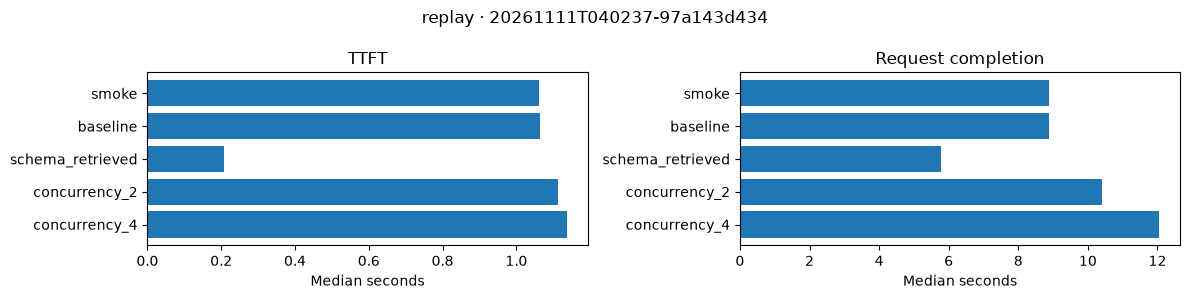

In [11]:
from clinical_trial_mvp.tutorial.session_figures import figure
fig = figure(study)
if fig is not None:
    display(fig)
    import matplotlib.pyplot as plt
    plt.close(fig)
else:
    print('No measured rows available for a figure.')


## 6. Cleanup

Save the notebook to retain genuine Live outputs. Native servers stop after each row. Stop the owned NIM container before switching models or pausing. Cleanup is safe to repeat and does not stop external servers.


In [12]:
print(study.close())


Study servers stopped. Saved records and notebook outputs are retained.


## Reference: previously measured results

The previous Dell measurements remain unchanged in [the results guide](../tutorial/RESULTS.md) and [the original executed notebook](history/dell-2026-11-07/local%20AI%20optimization%20-%20NIM%20Nemotron.ipynb). Select `MODE="replay"` explicitly to rebuild their tables. They are not measurements from this Live session.

[Execution and troubleshooting](../tutorial/RUN_ALL.md) · [SQL review packet](../tutorial/SQL_REVIEW.md)
